In [ ]:
# CELL 1 — MOUNT GOOGLE DRIVE AND INSPECT BUS-BRA

from google.colab import drive
from pathlib import Path
from collections import Counter

drive.mount("/content/drive")

# EDIT THIS PATH to match your extracted dataset folder.
DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_ROOT}\n"
        "Update DATA_ROOT to the extracted BUS-BRA folder."
    )

files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file())
extensions = Counter(p.suffix.lower() or "[no extension]" for p in files)

print("BUS-BRA — INITIAL DATASET INSPECTION")
print("=" * 65)
print(f"Root: {DATA_ROOT}")
print(f"Total files: {len(files):,}")

print("\nFILE TYPES")
for extension, count in extensions.most_common():
    print(f"{extension:15s} {count:>7,}")

print("\nTOP-LEVEL CONTENTS")
for p in sorted(DATA_ROOT.iterdir()):
    print(f"{'[DIR] ' if p.is_dir() else '[FILE]'} {p.name}")

print("\nMETADATA AND DOCUMENTATION FILES")
metadata_extensions = {
    ".csv", ".xlsx", ".xls", ".json", ".txt", ".md", ".pdf"
}
metadata_files = [
    p for p in files if p.suffix.lower() in metadata_extensions
]
if metadata_files:
    for p in metadata_files:
        print(p.relative_to(DATA_ROOT))
else:
    print("No matching files found.")

print("\nFIRST 20 FILE PATHS")
for p in files[:20]:
    print(p.relative_to(DATA_ROOT))

Mounted at /content/drive
BUS-BRA — INITIAL DATASET INSPECTION
Root: /content/drive/MyDrive/BUSBRA
Total files: 3,755

FILE TYPES
.png              3,750
.csv                  3
.txt                  1
.ipynb                1

TOP-LEVEL CONTENTS
[FILE] 10-fold-cv.csv
[FILE] 5-fold-cv.csv
[DIR]  Images
[FILE] LICENSE.txt
[DIR]  Masks
[FILE] Untitled0.ipynb
[FILE] bus_data.csv

METADATA AND DOCUMENTATION FILES
10-fold-cv.csv
5-fold-cv.csv
LICENSE.txt
bus_data.csv

FIRST 20 FILE PATHS
10-fold-cv.csv
5-fold-cv.csv
Images/bus_0001-l.png
Images/bus_0001-r.png
Images/bus_0002-l.png
Images/bus_0002-r.png
Images/bus_0003-l.png
Images/bus_0003-r.png
Images/bus_0004-l.png
Images/bus_0004-r.png
Images/bus_0005-l.png
Images/bus_0005-r.png
Images/bus_0006-s.png
Images/bus_0007-l.png
Images/bus_0007-r.png
Images/bus_0008-l.png
Images/bus_0008-r.png
Images/bus_0009-l.png
Images/bus_0009-r.png
Images/bus_0010-l.png


In [ ]:
# CELL 2 — INSPECT METADATA, PROVIDED FOLDS, AND LICENCE

import pandas as pd
from IPython.display import display

metadata_tables = {}

for filename in ["bus_data.csv", "5-fold-cv.csv", "10-fold-cv.csv"]:
    path = DATA_ROOT / filename
    if not path.is_file():
        raise FileNotFoundError(path)

    # Detect the delimiter; preserve identifiers as text.
    df = pd.read_csv(path, sep=None, engine="python", dtype=str)
    metadata_tables[filename] = df

    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Duplicate rows: {df.duplicated().sum():,}")

    print("\nFIRST 10 ROWS")
    display(df.head(10))

    print("\nCOLUMN SUMMARY")
    display(pd.DataFrame({
        "Non_missing": df.notna().sum(),
        "Missing": df.isna().sum(),
        "Unique_non_missing": df.nunique(dropna=True),
    }))

    print("\nVALUE COUNTS — COLUMNS WITH AT MOST 15 UNIQUE VALUES")
    for column in df.columns:
        if df[column].nunique(dropna=True) <= 15:
            print(f"\n{column}")
            print(df[column].value_counts(dropna=False).to_string())

bus_metadata = metadata_tables["bus_data.csv"]

print("\n" + "=" * 75)
print("LICENCE")
print("=" * 75)
license_path = DATA_ROOT / "LICENSE.txt"
print(license_path.read_text(encoding="utf-8", errors="replace"))


bus_data.csv
Shape: (1875, 10)
Columns: ['ID', 'Case', 'Histology', 'Pathology', 'BIRADS', 'Device', 'Width', 'Height', 'Side', 'BBOX']
Duplicate rows: 0

FIRST 10 ROWS


,ID,Case,Histology,Pathology,BIRADS,Device,Width,Height,Side,BBOX
0,bus_0001-l,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,274,353,left,"[91,24,103,79]"
1,bus_0001-r,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,353,right,"[102,24,82,79]"
2,bus_0002-l,2,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,274,371,left,"[134,142,88,50]"
3,bus_0002-r,2,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,276,371,right,"[113,143,68,47]"
4,bus_0003-l,3,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,372,left,"[71,78,126,137]"
5,bus_0003-r,3,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,274,372,right,"[80,66,179,156]"
6,bus_0004-l,4,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,274,383,left,"[70,50,94,32]"
7,bus_0004-r,4,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,277,383,right,"[112,53,87,47]"
8,bus_0005-l,5,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,371,left,"[118,50,82,141]"
9,bus_0005-r,5,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,276,371,right,"[108,45,138,153]"



COLUMN SUMMARY


,Non_missing,Missing,Unique_non_missing
ID,1875,0,1875
Case,1875,0,1064
Histology,1875,0,28
Pathology,1875,0,2
BIRADS,1875,0,4
Device,1875,0,4
Width,1875,0,117
Height,1875,0,135
Side,1875,0,3
BBOX,1875,0,1875



VALUE COUNTS — COLUMNS WITH AT MOST 15 UNIQUE VALUES

Pathology
Pathology
benign       1268
malignant     607

BIRADS
BIRADS
4    693
2    562
3    463
5    157

Device
Device
GE Logiq 7 @10-14MHz            902
GE Logiq 5 @10-12MHz            809
Toshiba Aplio 300 @12-14 MHz    139
U-Systems @10-14MHz              25

Side
Side
left      811
right     811
single    253

5-fold-cv.csv
Shape: (1875, 8)
Columns: ['ID', 'Pathology', 'kFold', 'valid_1', 'valid_2', 'valid_3', 'valid_4', 'valid_5']
Duplicate rows: 0

FIRST 10 ROWS


,ID,Pathology,kFold,valid_1,valid_2,valid_3,valid_4,valid_5
0,bus_0001-l,malignant,3,1,1,NaN,1,1
1,bus_0001-r,malignant,3,1,1,NaN,1,1
2,bus_0002-l,benign,5,1,1,1,1,NaN
3,bus_0002-r,benign,5,1,1,0,1,NaN
4,bus_0003-l,malignant,4,0,1,0,NaN,1
5,bus_0003-r,malignant,4,1,1,1,NaN,0
6,bus_0004-l,benign,3,1,1,NaN,1,1
7,bus_0004-r,benign,3,1,1,NaN,1,0
8,bus_0005-l,malignant,5,1,0,1,0,NaN
9,bus_0005-r,malignant,5,1,1,1,1,NaN


... (3 outputs left out)

,ID,Pathology,kFold,valid_1,valid_2,valid_3,valid_4,valid_5,valid_6,valid_7,valid_8,valid_9,valid_10
0,bus_0001-l,malignant,9,1,0,1,1,1,1,1,1,NaN,1
1,bus_0001-r,malignant,9,0,1,1,1,1,0,1,1,NaN,1
2,bus_0002-l,benign,3,1,1,NaN,0,1,1,1,1,0,0
3,bus_0002-r,benign,3,1,1,NaN,0,1,1,1,1,1,1
4,bus_0003-l,malignant,7,1,0,0,1,1,1,NaN,1,1,0
5,bus_0003-r,malignant,7,1,1,1,1,1,1,NaN,1,1,1
6,bus_0004-l,benign,4,1,0,0,NaN,0,0,1,1,0,0
7,bus_0004-r,benign,4,1,0,1,NaN,0,1,1,1,1,0
8,bus_0005-l,malignant,6,1,0,1,1,1,NaN,1,1,1,1
9,bus_0005-r,malignant,6,1,1,1,1,1,NaN,0,1,1,1



COLUMN SUMMARY


,Non_missing,Missing,Unique_non_missing
ID,1875,0,1875
Pathology,1875,0,2
kFold,1875,0,10
valid_1,1682,193,2
valid_2,1682,193,2
valid_3,1689,186,2
valid_4,1692,183,2
valid_5,1691,184,2
valid_6,1690,185,2
valid_7,1686,189,2



VALUE COUNTS — COLUMNS WITH AT MOST 15 UNIQUE VALUES

Pathology
Pathology
benign       1268
malignant     607

kFold
kFold
1     193
8     193
2     193
7     189
9     188
3     186
6     185
5     184
4     183
10    181

valid_1
valid_1
1      1347
0       335
NaN     193

valid_2
valid_2
1      1347
0       335
NaN     193

valid_3
valid_3
1      1352
0       337
NaN     186

valid_4
valid_4
1      1355
0       337
NaN     183

valid_5
valid_5
1      1353
0       338
NaN     184

valid_6
valid_6
1      1353
0       337
NaN     185

valid_7
valid_7
1      1350
0       336
NaN     189

valid_8
valid_8
1      1347
0       335
NaN     193

valid_9
valid_9
1      1350
0       337
NaN     188

valid_10
valid_10
1      1356
0       338
NaN     181

LICENCE
Copyright (c) 2023

Permission is hereby granted, free of charge, to any person obtaining a copy of this dataset and associated documentation files (the "Dataset"), to deal in the Dataset without restriction, including without limitati

In [ ]:
# CELL 3 — COMPACT METADATA AND FOLD INSPECTION

import pandas as pd
from IPython.display import display

print("BUS-BRA METADATA")
print("=" * 75)

print(f"Shape: {bus_metadata.shape}")
print(f"Columns: {bus_metadata.columns.tolist()}")
display(bus_metadata.head(8))

print("\nMETADATA COLUMN SUMMARY")
display(pd.DataFrame({
    "Missing": bus_metadata.isna().sum(),
    "Unique": bus_metadata.nunique(dropna=True),
    "Examples": [
        bus_metadata[c].dropna().unique()[:6].tolist()
        for c in bus_metadata.columns
    ],
}))

print("\nLOW-CARDINALITY METADATA VALUES")
for c in bus_metadata.columns:
    if bus_metadata[c].nunique(dropna=True) <= 15:
        print(f"\n{c}:")
        print(bus_metadata[c].value_counts(dropna=False).to_string())

for filename in ["5-fold-cv.csv", "10-fold-cv.csv"]:
    df = metadata_tables[filename]

    print("\n" + "=" * 75)
    print(f"{filename} — shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    display(df.head(5))

    print("First 3 rows containing any missing value:")
    display(df.loc[df.isna().any(axis=1)].head(3))

print("\nIMAGE AND MASK FILENAME EXAMPLES")
for folder in ["Images", "Masks"]:
    paths = sorted((DATA_ROOT / folder).glob("*.png"))
    print(f"\n{folder}: {len(paths):,} PNG files")
    for p in paths[:5]:
        print(p.name)

BUS-BRA METADATA
Shape: (1875, 10)
Columns: ['ID', 'Case', 'Histology', 'Pathology', 'BIRADS', 'Device', 'Width', 'Height', 'Side', 'BBOX']


,ID,Case,Histology,Pathology,BIRADS,Device,Width,Height,Side,BBOX
0,bus_0001-l,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,274,353,left,"[91,24,103,79]"
1,bus_0001-r,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,353,right,"[102,24,82,79]"
2,bus_0002-l,2,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,274,371,left,"[134,142,88,50]"
3,bus_0002-r,2,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,276,371,right,"[113,143,68,47]"
4,bus_0003-l,3,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,372,left,"[71,78,126,137]"
5,bus_0003-r,3,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,274,372,right,"[80,66,179,156]"
6,bus_0004-l,4,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,274,383,left,"[70,50,94,32]"
7,bus_0004-r,4,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,277,383,right,"[112,53,87,47]"



METADATA COLUMN SUMMARY


,Missing,Unique,Examples
ID,0,1875,"[bus_0001-l, bus_0001-r, bus_0002-l, bus_0002-..."
Case,0,1064,"[1, 2, 3, 4, 5, 6]"
Histology,0,28,"[invasive ductal carcinoma, fibroadenoma, hype..."
Pathology,0,2,"[malignant, benign]"
BIRADS,0,4,"[4, 2, 5, 3]"
Device,0,4,"[GE Logiq 7 @10-14MHz, GE Logiq 5 @10-12MHz, U..."
Width,0,117,"[274, 275, 276, 277, 407, 273]"
Height,0,135,"[353, 371, 372, 383, 389, 351]"
Side,0,3,"[left, right, single]"
BBOX,0,1875,"[[91,24,103,79], [102,24,82,79], [134,142,88,5..."



LOW-CARDINALITY METADATA VALUES

Pathology:
Pathology
benign       1268
malignant     607

BIRADS:
BIRADS
4    693
2    562
3    463
5    157

Device:
Device
GE Logiq 7 @10-14MHz            902
GE Logiq 5 @10-12MHz            809
Toshiba Aplio 300 @12-14 MHz    139
U-Systems @10-14MHz              25

Side:
Side
left      811
right     811
single    253

5-fold-cv.csv — shape: (1875, 8)
Columns: ['ID', 'Pathology', 'kFold', 'valid_1', 'valid_2', 'valid_3', 'valid_4', 'valid_5']


,ID,Pathology,kFold,valid_1,valid_2,valid_3,valid_4,valid_5
0,bus_0001-l,malignant,3,1,1,NaN,1,1
1,bus_0001-r,malignant,3,1,1,NaN,1,1
2,bus_0002-l,benign,5,1,1,1,1,NaN
3,bus_0002-r,benign,5,1,1,0,1,NaN
4,bus_0003-l,malignant,4,0,1,0,NaN,1


... (3 outputs left out)

,ID,Pathology,kFold,valid_1,valid_2,valid_3,valid_4,valid_5,valid_6,valid_7,valid_8,valid_9,valid_10
0,bus_0001-l,malignant,9,1,0,1,1,1,1,1,1,NaN,1
1,bus_0001-r,malignant,9,0,1,1,1,1,0,1,1,NaN,1
2,bus_0002-l,benign,3,1,1,NaN,0,1,1,1,1,0,0
3,bus_0002-r,benign,3,1,1,NaN,0,1,1,1,1,1,1
4,bus_0003-l,malignant,7,1,0,0,1,1,1,NaN,1,1,0


First 3 rows containing any missing value:


,ID,Pathology,kFold,valid_1,valid_2,valid_3,valid_4,valid_5,valid_6,valid_7,valid_8,valid_9,valid_10
0,bus_0001-l,malignant,9,1,0,1,1,1,1,1,1,NaN,1
1,bus_0001-r,malignant,9,0,1,1,1,1,0,1,1,NaN,1
2,bus_0002-l,benign,3,1,1,NaN,0,1,1,1,1,0,0



IMAGE AND MASK FILENAME EXAMPLES

Images: 1,875 PNG files
bus_0001-l.png
bus_0001-r.png
bus_0002-l.png
bus_0002-r.png
bus_0003-l.png

Masks: 1,875 PNG files
mask_0001-l.png
mask_0001-r.png
mask_0002-l.png
mask_0002-r.png
mask_0003-l.png


In [ ]:
# CELL 4 — CASE, FILE CORRESPONDENCE, AND FOLD AUDIT

import pandas as pd
from IPython.display import display

audit_metadata = bus_metadata.copy()

# Standardise text without changing the original metadata.
for c in audit_metadata.columns:
    audit_metadata[c] = audit_metadata[c].astype("string").str.strip()

print("CASE CONSISTENCY")
print("=" * 75)

case_summary = audit_metadata.groupby("Case").agg(
    Images=("ID", "size"),
    Pathology_values=("Pathology", "nunique"),
    Histology_values=("Histology", "nunique"),
    Device_values=("Device", "nunique"),
    BIRADS_values=("BIRADS", "nunique"),
)

print(f"Unique cases: {len(case_summary):,}")
print(f"Duplicate image IDs: {audit_metadata['ID'].duplicated().sum()}")
print("\nImages per case:")
print(case_summary["Images"].value_counts().sort_index().to_string())

for c in ["Pathology_values", "Histology_values", "Device_values",
          "BIRADS_values"]:
    print(f"Cases with multiple {c.replace('_values', '')} values: "
          f"{case_summary[c].gt(1).sum()}")

print("\nCASE-LEVEL PATHOLOGY COMBINATIONS")
case_pathology = audit_metadata.groupby("Case")["Pathology"].agg(
    lambda s: " + ".join(sorted(s.dropna().unique()))
)
print(case_pathology.value_counts().to_string())

print("\nDEVICE × PATHOLOGY — IMAGE COUNTS")
display(pd.crosstab(
    audit_metadata["Device"], audit_metadata["Pathology"]
))

print("\nDEVICE × PATHOLOGY — DISTINCT CASE COUNTS")
display(pd.crosstab(
    audit_metadata.drop_duplicates(["Case", "Device", "Pathology"])["Device"],
    audit_metadata.drop_duplicates(["Case", "Device", "Pathology"])["Pathology"]
))

print("\nFILE CORRESPONDENCE")
print("=" * 75)

expected_images = set(audit_metadata["ID"] + ".png")
expected_masks = {
    image_id.replace("bus_", "mask_", 1) + ".png"
    for image_id in audit_metadata["ID"]
}
actual_images = {p.name for p in (DATA_ROOT / "Images").glob("*.png")}
actual_masks = {p.name for p in (DATA_ROOT / "Masks").glob("*.png")}

for label, names in {
    "Missing images": expected_images - actual_images,
    "Unlisted images": actual_images - expected_images,
    "Missing masks": expected_masks - actual_masks,
    "Unlisted masks": actual_masks - expected_masks,
}.items():
    print(f"{label}: {len(names)}")
    if names:
        print("Examples:", sorted(names)[:5])

print("\nSUPPLIED FOLD AUDIT")
print("=" * 75)

fold_audit_rows = []

for filename in ["5-fold-cv.csv", "10-fold-cv.csv"]:
    folds = metadata_tables[filename].copy()
    for c in folds.columns:
        folds[c] = folds[c].astype("string").str.strip()

    print(f"\n{filename}")
    print(f"Duplicate IDs: {folds['ID'].duplicated().sum()}")
    print(f"Metadata IDs absent from folds: "
          f"{len(set(audit_metadata['ID']) - set(folds['ID']))}")
    print(f"Fold IDs absent from metadata: "
          f"{len(set(folds['ID']) - set(audit_metadata['ID']))}")

    if folds["ID"].duplicated().any():
        print("Skipping merge because fold IDs are duplicated.")
        continue

    merged = audit_metadata[["ID", "Case", "Pathology"]].merge(
        folds, on="ID", how="left", suffixes=("_meta", "_fold"),
        validate="one_to_one", indicator=True
    )
    matched = merged.loc[merged["_merge"].eq("both")].copy()

    print("Pathology disagreements:",
          matched["Pathology_meta"].ne(
              matched["Pathology_fold"]
          ).fillna(True).sum())

    outer = pd.to_numeric(matched["kFold"], errors="coerce")
    matched["_outer_fold"] = outer

    print("Cases assigned to multiple outer folds:",
          matched.groupby("Case")["_outer_fold"].nunique().gt(1).sum())

    for c in [c for c in folds.columns if c.startswith("valid_")]:
        fold_number = int(c.split("_")[1])
        assignment = pd.to_numeric(matched[c], errors="coerce")

        # Compare missing entries with outer-fold membership.
        expected_missing = outer.eq(fold_number)
        missing_mismatches = assignment.isna().ne(expected_missing).sum()

        # Detect cases split between values 0 and 1, without assuming
        # which value means training or validation.
        values_by_case = (
            matched.assign(_assignment=assignment)
            .groupby("Case")["_assignment"]
            .agg(lambda s: set(s.dropna()))
        )
        split_cases = values_by_case.apply(
            lambda values: 0 in values and 1 in values
        ).sum()

        fold_audit_rows.append({
            "File": filename,
            "Column": c,
            "NaN": int(assignment.isna().sum()),
            "NaN_vs_outer_fold_mismatches": int(missing_mismatches),
            "Cases_with_both_0_and_1": int(split_cases),
        })

display(pd.DataFrame(fold_audit_rows))

CASE CONSISTENCY
Unique cases: 1,064
Duplicate image IDs: 0

Images per case:
Images
1    253
2    811
Cases with multiple Pathology values: 0
Cases with multiple Histology values: 0
Cases with multiple Device values: 0
Cases with multiple BIRADS values: 1

CASE-LEVEL PATHOLOGY COMBINATIONS
Pathology
benign       722
malignant    342

DEVICE × PATHOLOGY — IMAGE COUNTS


Pathology,benign,malignant
Device,,
GE Logiq 5 @10-12MHz,566,243
GE Logiq 7 @10-14MHz,617,285
Toshiba Aplio 300 @12-14 MHz,71,68
U-Systems @10-14MHz,14,11



DEVICE × PATHOLOGY — DISTINCT CASE COUNTS


Pathology,benign,malignant
Device,,
GE Logiq 5 @10-12MHz,350,140
GE Logiq 7 @10-14MHz,327,161
Toshiba Aplio 300 @12-14 MHz,37,35
U-Systems @10-14MHz,8,6



FILE CORRESPONDENCE
Missing images: 0
Unlisted images: 0
Missing masks: 0
Unlisted masks: 0

SUPPLIED FOLD AUDIT

5-fold-cv.csv
Duplicate IDs: 0
Metadata IDs absent from folds: 0
Fold IDs absent from metadata: 0
Pathology disagreements: 0
Cases assigned to multiple outer folds: 0

10-fold-cv.csv
Duplicate IDs: 0
Metadata IDs absent from folds: 0
Fold IDs absent from metadata: 0
Pathology disagreements: 0
Cases assigned to multiple outer folds: 0


,File,Column,NaN,NaN_vs_outer_fold_mismatches,Cases_with_both_0_and_1
0,5-fold-cv.csv,valid_1,376,0,210
1,5-fold-cv.csv,valid_2,385,0,201
2,5-fold-cv.csv,valid_3,366,0,212
3,5-fold-cv.csv,valid_4,365,0,216
4,5-fold-cv.csv,valid_5,383,0,211
5,10-fold-cv.csv,valid_1,193,0,244
6,10-fold-cv.csv,valid_2,193,0,234
7,10-fold-cv.csv,valid_3,186,0,239
8,10-fold-cv.csv,valid_4,183,0,245
9,10-fold-cv.csv,valid_5,184,0,236


In [ ]:
# CELL 5 — IMAGE–MASK INTEGRITY AND EXACT DUPLICATE AUDIT

import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

integrity_rows = []
read_errors = []

for row in tqdm(
    audit_metadata.to_dict("records"),
    total=len(audit_metadata),
    desc="Checking image–mask pairs"
):
    image_id = row["ID"]
    image_path = DATA_ROOT / "Images" / f"{image_id}.png"
    mask_path = (
        DATA_ROOT / "Masks"
        / f"{image_id.replace('bus_', 'mask_', 1)}.png"
    )

    try:
        with Image.open(image_path) as im:
            im.load()
            image_mode = im.mode
            image_size = im.size
            image_array = np.array(im)
            # Canonical RGB pixels detect identical images across modes.
            rgb = np.asarray(im.convert("RGB"))
            image_hash = hashlib.sha256(
                str(rgb.shape).encode() + rgb.tobytes()
            ).hexdigest()

        with Image.open(mask_path) as mask:
            mask.load()
            mask_mode = mask.mode
            mask_size = mask.size
            mask_array = np.array(mask)

        values = np.unique(mask_array)
        scalar_mask = mask_array.ndim == 2
        foreground_fraction = (
            float((mask_array > 0).mean()) if scalar_mask else np.nan
        )

        integrity_rows.append({
            "ID": image_id,
            "Case": row["Case"],
            "Pathology": row["Pathology"],
            "Image_mode": image_mode,
            "Mask_mode": mask_mode,
            "Width": image_size[0],
            "Height": image_size[1],
            "Metadata_size_match": image_size == (
                int(row["Width"]), int(row["Height"])
            ),
            "Image_mask_size_match": image_size == mask_size,
            "Mask_is_2D": scalar_mask,
            "Mask_values": tuple(values.tolist()),
            "Mask_foreground_fraction": foreground_fraction,
            "Image_constant": bool(image_array.min() == image_array.max()),
            "Image_pixel_hash": image_hash,
        })

    except Exception as exc:
        read_errors.append({
            "ID": image_id,
            "Error": f"{type(exc).__name__}: {exc}"
        })

image_integrity = pd.DataFrame(integrity_rows)
image_read_errors = pd.DataFrame(read_errors)

print("IMAGE–MASK INTEGRITY")
print("=" * 75)
print(f"Successfully checked: {len(image_integrity):,}")
print(f"Read errors: {len(image_read_errors):,}")

if not image_read_errors.empty:
    display(image_read_errors)

if not image_integrity.empty:
    print("\nIMAGE AND MASK MODES")
    display(
        image_integrity.groupby(["Image_mode", "Mask_mode"])
        .size().rename("Count").reset_index()
    )

    print("\nINTEGRITY COUNTS")
    for column in [
        "Metadata_size_match", "Image_mask_size_match", "Mask_is_2D"
    ]:
        print(f"{column} — failures: "
              f"{(~image_integrity[column]).sum()}")

    print("Constant images:", image_integrity["Image_constant"].sum())
    print("Empty 2D masks:",
          image_integrity["Mask_foreground_fraction"].eq(0).sum())
    print("Full 2D masks:",
          image_integrity["Mask_foreground_fraction"].eq(1).sum())

    print("\nMASK VALUE COMBINATIONS")
    print(image_integrity["Mask_values"].value_counts().to_string())

    print("\nDIMENSIONS AND FOREGROUND FRACTION")
    display(image_integrity[
        ["Width", "Height", "Mask_foreground_fraction"]
    ].describe())

    exact_duplicate_images = image_integrity.loc[
        image_integrity["Image_pixel_hash"].duplicated(keep=False)
    ].sort_values(["Image_pixel_hash", "Case", "ID"])

    print("\nEXACT DUPLICATE IMAGE GROUPS")
    print("Images in duplicate groups:", len(exact_duplicate_images))
    print("Duplicate groups:",
          exact_duplicate_images["Image_pixel_hash"].nunique())

    if not exact_duplicate_images.empty:
        duplicate_summary = exact_duplicate_images.groupby(
            "Image_pixel_hash"
        ).agg(
            Images=("ID", "size"),
            Cases=("Case", "nunique"),
            Labels=("Pathology", "nunique"),
        )
        print("Groups spanning different cases:",
              duplicate_summary["Cases"].gt(1).sum())
        print("Groups with conflicting labels:",
              duplicate_summary["Labels"].gt(1).sum())
        display(exact_duplicate_images[
            ["ID", "Case", "Pathology", "Image_pixel_hash"]
        ].head(30))

Checking image–mask pairs:   0%|          | 0/1875 [00:00<?, ?it/s]

IMAGE–MASK INTEGRITY
Successfully checked: 1,873
Read errors: 2


,ID,Error
0,bus_1041-l,OSError: [Errno 5] Input/output error
1,bus_1051-l,OSError: [Errno 5] Input/output error



IMAGE AND MASK MODES


,Image_mode,Mask_mode,Count
0,L,1,1873



INTEGRITY COUNTS
Metadata_size_match — failures: 4
Image_mask_size_match — failures: 0
Mask_is_2D — failures: 0
Constant images: 0
Empty 2D masks: 0
Full 2D masks: 0

MASK VALUE COMBINATIONS
Mask_values
(False, True)    1873

DIMENSIONS AND FOREGROUND FRACTION


,Width,Height,Mask_foreground_fraction
count,1873.000000,1873.000000,1873.000000
mean,321.358783,391.340096,0.086648
std,76.944782,52.837561,0.075553
min,240.000000,268.000000,0.006090
25%,276.000000,350.000000,0.033014
50%,286.000000,383.000000,0.062179
75%,323.000000,435.000000,0.118195
max,579.000000,478.000000,0.575387



EXACT DUPLICATE IMAGE GROUPS
Images in duplicate groups: 0
Duplicate groups: 0


In [ ]:
# CELL 6 — RETRY FAILED PAIRS AND INSPECT DIMENSION DISCREPANCIES

import time
import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

failed_ids = (
    image_read_errors["ID"].tolist()
    if not image_read_errors.empty else []
)
recovered_rows = []
retry_errors = []

for image_id in failed_ids:
    row = audit_metadata.loc[
        audit_metadata["ID"].eq(image_id)
    ].iloc[0]

    image_path = DATA_ROOT / "Images" / f"{image_id}.png"
    mask_path = (
        DATA_ROOT / "Masks"
        / f"{image_id.replace('bus_', 'mask_', 1)}.png"
    )

    for attempt in range(1, 4):
        stage = "image"
        try:
            with Image.open(image_path) as im:
                im.load()
                image_mode = im.mode
                image_size = im.size
                image_array = np.array(im)
                rgb = np.asarray(im.convert("RGB"))
                image_hash = hashlib.sha256(
                    str(rgb.shape).encode() + rgb.tobytes()
                ).hexdigest()

            stage = "mask"
            with Image.open(mask_path) as mask:
                mask.load()
                mask_mode = mask.mode
                mask_size = mask.size
                mask_array = np.array(mask)

            scalar_mask = mask_array.ndim == 2

            recovered_rows.append({
                "ID": image_id,
                "Case": row["Case"],
                "Pathology": row["Pathology"],
                "Image_mode": image_mode,
                "Mask_mode": mask_mode,
                "Width": image_size[0],
                "Height": image_size[1],
                "Metadata_size_match": image_size == (
                    int(row["Width"]), int(row["Height"])
                ),
                "Image_mask_size_match": image_size == mask_size,
                "Mask_is_2D": scalar_mask,
                "Mask_values": tuple(np.unique(mask_array).tolist()),
                "Mask_foreground_fraction": (
                    float((mask_array > 0).mean())
                    if scalar_mask else np.nan
                ),
                "Image_constant": bool(
                    image_array.min() == image_array.max()
                ),
                "Image_pixel_hash": image_hash,
            })
            print(f"{image_id}: recovered on attempt {attempt}")
            break

        except Exception as exc:
            print(f"{image_id}, attempt {attempt}, {stage}: {exc}")
            if attempt < 3:
                time.sleep(2)
            else:
                retry_errors.append({
                    "ID": image_id,
                    "Stage": stage,
                    "Error": f"{type(exc).__name__}: {exc}",
                })

if recovered_rows:
    image_integrity = pd.concat(
        [image_integrity, pd.DataFrame(recovered_rows)],
        ignore_index=True
    ).drop_duplicates("ID", keep="last")

image_read_errors = pd.DataFrame(
    retry_errors, columns=["ID", "Stage", "Error"]
)

print("\nUPDATED AUDIT")
print("=" * 75)
print(f"Checked pairs: {len(image_integrity):,} / {len(audit_metadata):,}")
print(f"Unresolved read errors: {len(image_read_errors)}")
if not image_read_errors.empty:
    display(image_read_errors)

print("\nDIMENSION DISCREPANCIES")
dimension_discrepancies = image_integrity.loc[
    ~image_integrity["Metadata_size_match"],
    ["ID", "Width", "Height", "Image_mask_size_match"]
].merge(
    audit_metadata[["ID", "Case", "Device", "Width", "Height"]],
    on="ID",
    suffixes=("_actual", "_metadata"),
    validate="one_to_one"
)
display(dimension_discrepancies)

print("\nUPDATED INTEGRITY COUNTS")
for column in ["Image_mask_size_match", "Mask_is_2D"]:
    print(f"{column} — failures: {(~image_integrity[column]).sum()}")
print("Constant images:", image_integrity["Image_constant"].sum())
print("Empty masks:",
      image_integrity["Mask_foreground_fraction"].eq(0).sum())
print("Full masks:",
      image_integrity["Mask_foreground_fraction"].eq(1).sum())

exact_duplicate_images = image_integrity.loc[
    image_integrity["Image_pixel_hash"].duplicated(keep=False)
].copy()
print("Images in exact duplicate groups:", len(exact_duplicate_images))
if not exact_duplicate_images.empty:
    display(exact_duplicate_images[
        ["ID", "Case", "Pathology", "Image_pixel_hash"]
    ])

bus_1041-l: recovered on attempt 1
bus_1051-l: recovered on attempt 1

UPDATED AUDIT
Checked pairs: 1,875 / 1,875
Unresolved read errors: 0

DIMENSION DISCREPANCIES


,ID,Width_actual,Height_actual,Image_mask_size_match,Case,Device,Width_metadata,Height_metadata
0,bus_0856-l,387,353,True,856,U-Systems @10-14MHz,387,405
1,bus_0857-r,384,393,True,857,U-Systems @10-14MHz,384,409
2,bus_0912-l,360,352,True,912,GE Logiq 7 @10-14MHz,360,354
3,bus_0990-l,540,352,True,990,GE Logiq 7 @10-14MHz,540,354



UPDATED INTEGRITY COUNTS
Image_mask_size_match — failures: 0
Mask_is_2D — failures: 0
Constant images: 0
Empty masks: 0
Full masks: 0
Images in exact duplicate groups: 0


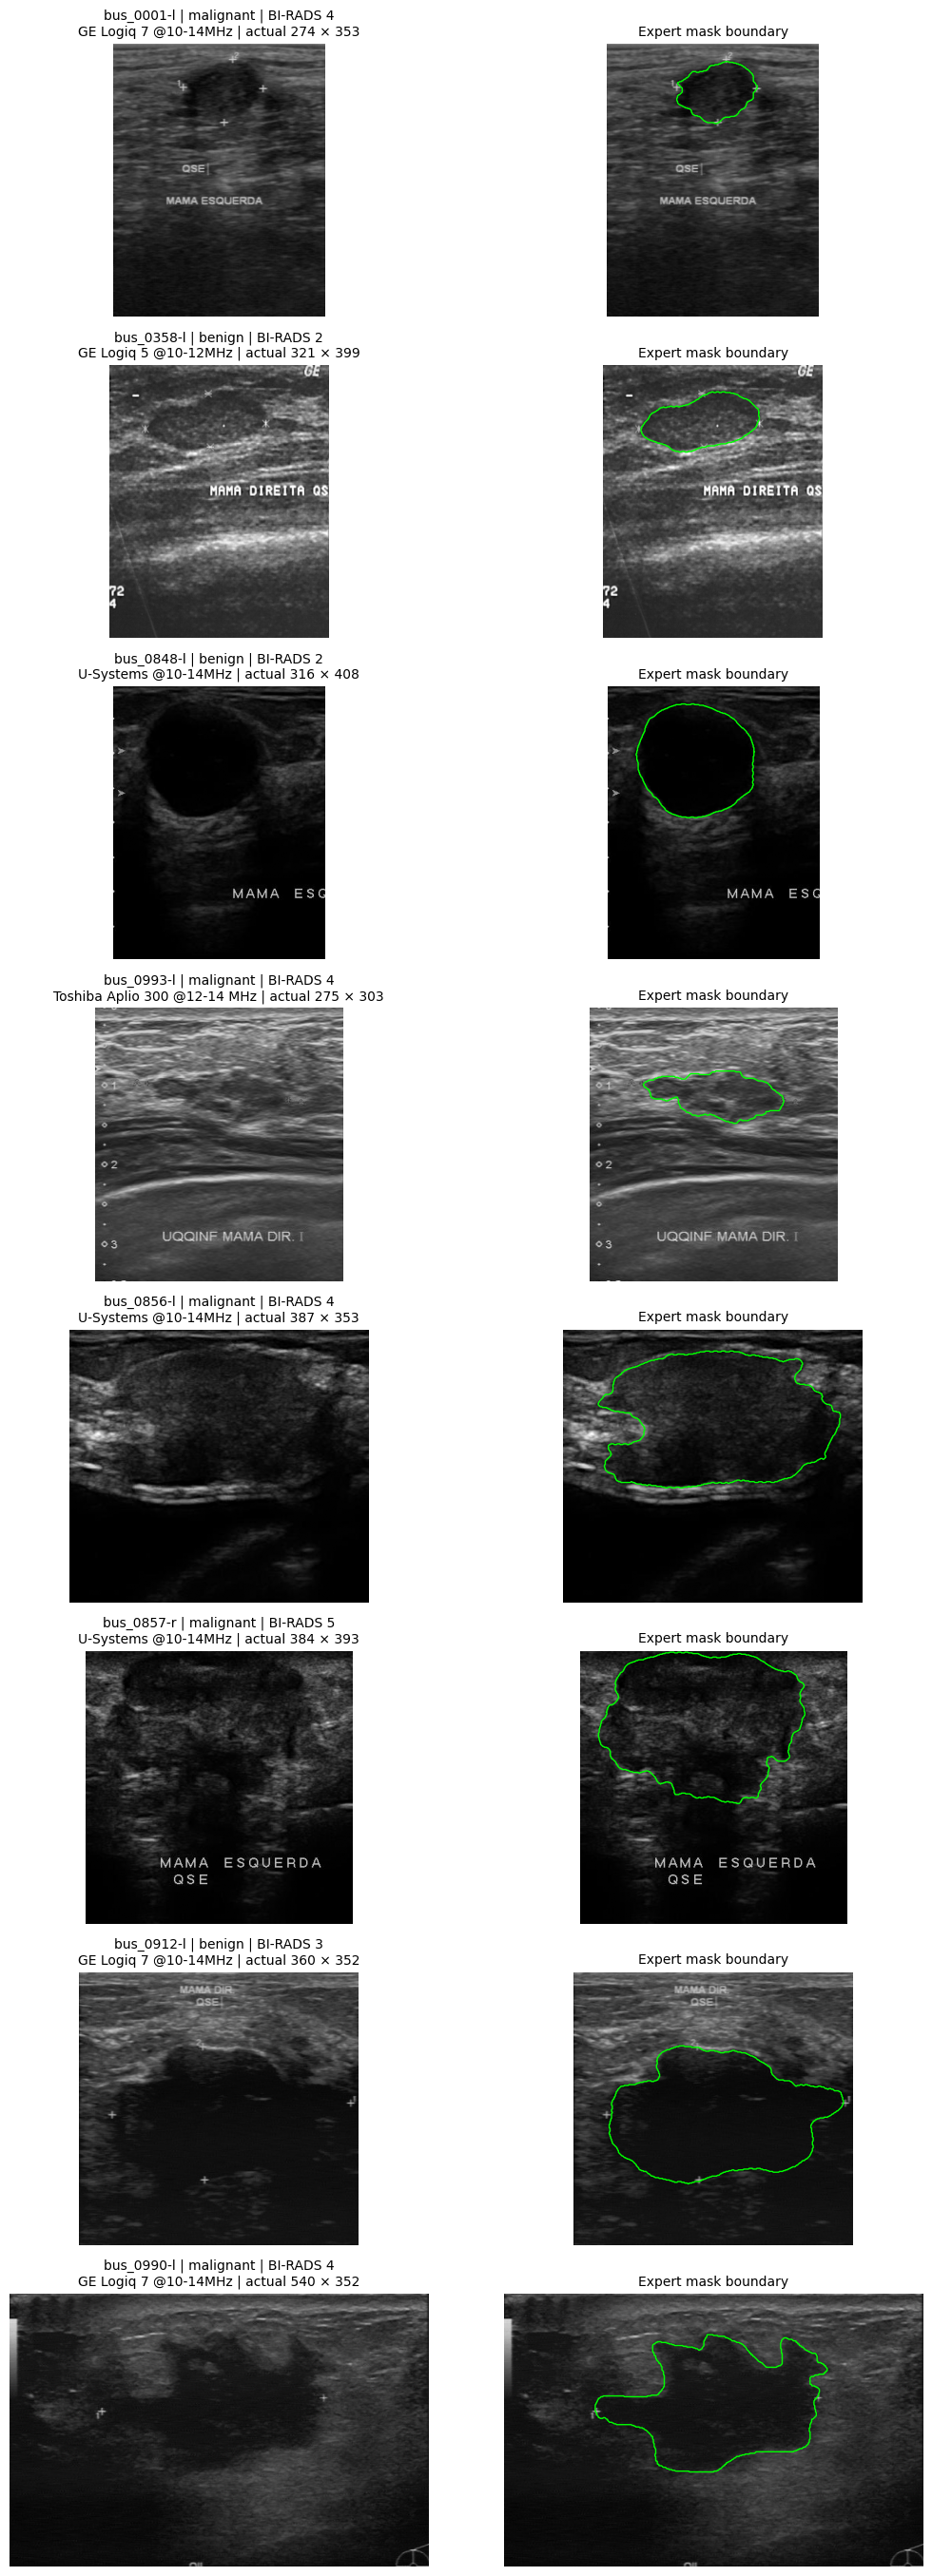

CASE CONSISTENCY — SUMMARY
Cases: 1,064
Images per case:
Images
1    253
2    811
Cases with multiple Pathology values: 0
Cases with multiple Histology values: 0
Cases with multiple Device values: 0


In [ ]:
# CELL 7 — VISUAL IMAGE–MASK REVIEW

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# One reproducible example per device, plus all dimension discrepancies.
device_examples = (
    audit_metadata.sort_values("ID")
    .groupby("Device", group_keys=False)
    .head(1)["ID"].tolist()
)
discrepancy_ids = dimension_discrepancies["ID"].tolist()
review_ids = list(dict.fromkeys(device_examples + discrepancy_ids))

fig, axes = plt.subplots(
    len(review_ids), 2,
    figsize=(11, 3.4 * len(review_ids)),
    squeeze=False
)

for i, image_id in enumerate(review_ids):
    row = audit_metadata.loc[
        audit_metadata["ID"].eq(image_id)
    ].iloc[0]

    with Image.open(
        DATA_ROOT / "Images" / f"{image_id}.png"
    ) as im:
        image = np.array(im.convert("L"))

    mask_name = image_id.replace("bus_", "mask_", 1) + ".png"
    with Image.open(DATA_ROOT / "Masks" / mask_name) as im:
        mask = np.array(im).astype(bool)

    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(
        f"{image_id} | {row['Pathology']} | BI-RADS {row['BIRADS']}\n"
        f"{row['Device']} | actual {image.shape[1]} × {image.shape[0]}",
        fontsize=10
    )

    axes[i, 1].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].contour(mask, levels=[0.5], colors=["lime"], linewidths=1)
    axes[i, 1].set_title("Expert mask boundary", fontsize=10)

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("CASE CONSISTENCY — SUMMARY")
case_checks = audit_metadata.groupby("Case").agg(
    Images=("ID", "size"),
    Pathology_values=("Pathology", "nunique"),
    Histology_values=("Histology", "nunique"),
    Device_values=("Device", "nunique"),
)
print(f"Cases: {len(case_checks):,}")
print("Images per case:")
print(case_checks["Images"].value_counts().sort_index().to_string())

for column in ["Pathology_values", "Histology_values", "Device_values"]:
    print(f"Cases with multiple {column.replace('_values', '')} values: "
          f"{case_checks[column].gt(1).sum()}")

In [ ]:
# CELL 8 — SAVE AUDIT AND BUILD ANALYSIS MANIFEST

from pathlib import Path
import json
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
AUDIT_DIR = PROJECT_ROOT / "audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

assert image_read_errors.empty, "Unresolved image–mask read errors."
assert len(image_integrity) == len(audit_metadata)
assert image_integrity["ID"].is_unique
assert image_integrity["Image_mask_size_match"].all()
assert image_integrity["Mask_is_2D"].all()

# Preserve source dimensions explicitly.
manifest = audit_metadata.rename(columns={
    "Width": "Width_metadata",
    "Height": "Height_metadata",
}).merge(
    image_integrity[[
        "ID", "Width", "Height", "Metadata_size_match",
        "Mask_foreground_fraction", "Image_pixel_hash"
    ]].rename(columns={
        "Width": "Width_actual",
        "Height": "Height_actual",
    }),
    on="ID",
    how="left",
    validate="one_to_one"
)

manifest["Label"] = manifest["Pathology"].map({
    "benign": 0, "malignant": 1
})
assert manifest["Label"].notna().all(), "Unexpected pathology label."

manifest["Image_relative_path"] = manifest["ID"].map(
    lambda x: f"Images/{x}.png"
)
manifest["Mask_relative_path"] = manifest["ID"].map(
    lambda x: f"Masks/{x.replace('bus_', 'mask_', 1)}.png"
)

# Retain supplied outer folds only; inner partitions will be defined later.
for k in [5, 10]:
    folds = metadata_tables[f"{k}-fold-cv.csv"][["ID", "kFold"]].copy()
    folds["ID"] = folds["ID"].astype("string").str.strip()
    folds[f"Outer_fold_{k}"] = pd.to_numeric(
        folds["kFold"], errors="raise"
    ).astype(int)

    manifest = manifest.merge(
        folds[["ID", f"Outer_fold_{k}"]],
        on="ID", how="left", validate="one_to_one"
    )
    assert manifest[f"Outer_fold_{k}"].notna().all()
    assert (
        manifest.groupby("Case")[f"Outer_fold_{k}"].nunique() == 1
    ).all()

summary = {
    "images": int(len(manifest)),
    "cases": int(manifest["Case"].nunique()),
    "benign_images": int(manifest["Label"].eq(0).sum()),
    "malignant_images": int(manifest["Label"].eq(1).sum()),
    "dimension_metadata_discrepancies": int(
        (~manifest["Metadata_size_match"]).sum()
    ),
    "unresolved_read_errors": int(len(image_read_errors)),
    "images_in_exact_duplicate_groups": int(
        manifest["Image_pixel_hash"].duplicated(keep=False).sum()
    ),
    "dimension_policy": "Use actual image dimensions; retain source metadata.",
    "validation_policy": (
        "Retain supplied case-separated outer folds. "
        "Do not use supplied valid_* columns for case-separated validation."
    ),
    "visual_review": (
        "Small sample reviewed; embedded text and measurement markers observed. "
        "No image alterations or exclusions applied."
    ),
}

manifest.to_csv(AUDIT_DIR / "analysis_manifest.csv", index=False)
image_integrity.to_csv(AUDIT_DIR / "image_integrity.csv", index=False)
dimension_discrepancies.to_csv(
    AUDIT_DIR / "dimension_discrepancies.csv", index=False
)
pd.DataFrame(fold_audit_rows).to_csv(
    AUDIT_DIR / "supplied_fold_audit.csv", index=False
)
(AUDIT_DIR / "audit_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

print("AUDIT SAVED")
print("=" * 70)
print(json.dumps(summary, indent=2))
print(f"\nOutput folder: {AUDIT_DIR}")
print("\nManifest preview:")
display(manifest.head(3))

AUDIT SAVED
{
  "images": 1875,
  "cases": 1064,
  "benign_images": 1268,
  "malignant_images": 607,
  "dimension_metadata_discrepancies": 4,
  "unresolved_read_errors": 0,
  "images_in_exact_duplicate_groups": 0,
  "dimension_policy": "Use actual image dimensions; retain source metadata.",
  "validation_policy": "Retain supplied case-separated outer folds. Do not use supplied valid_* columns for case-separated validation.",
  "visual_review": "Small sample reviewed; embedded text and measurement markers observed. No image alterations or exclusions applied."
}

Output folder: /content/drive/MyDrive/BUSBRA_Research/audit

Manifest preview:


,ID,Case,Histology,Pathology,BIRADS,Device,Width_metadata,Height_metadata,Side,BBOX,Width_actual,Height_actual,Metadata_size_match,Mask_foreground_fraction,Image_pixel_hash,Label,Image_relative_path,Mask_relative_path,Outer_fold_5,Outer_fold_10
0,bus_0001-l,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,274,353,left,"[91,24,103,79]",274,353,True,0.058560,1a160b18dfa1b46c0457b7f72b986d30fee9e83b5d1880...,1,Images/bus_0001-l.png,Masks/mask_0001-l.png,3,9
1,bus_0001-r,1,invasive ductal carcinoma,malignant,4,GE Logiq 7 @10-14MHz,275,353,right,"[102,24,82,79]",275,353,True,0.049271,fbfffdd8ed782403c2f2b51a45a5cd4f3eef77f0eacc94...,1,Images/bus_0001-r.png,Masks/mask_0001-r.png,3,9
2,bus_0002-l,2,fibroadenoma,benign,4,GE Logiq 7 @10-14MHz,274,371,left,"[134,142,88,50]",274,371,True,0.033801,5dd3238cf45683ac3d323bcaaa7a4971129b10c836e61e...,0,Images/bus_0002-l.png,Masks/mask_0002-l.png,5,3


In [ ]:
# CELL 9 — CASE-LEVEL CLASS BALANCE AND OUTER-FOLD SUMMARY

import pandas as pd
from IPython.display import display

# Confirm each case has a single label, device, and outer-fold assignment.
for column in ["Label", "Device", "Outer_fold_5", "Outer_fold_10"]:
    assert manifest.groupby("Case")[column].nunique().eq(1).all(), (
        f"Inconsistent {column} within a case."
    )

case_manifest = (
    manifest.groupby("Case", as_index=False)
    .agg(
        Label=("Label", "first"),
        Pathology=("Pathology", "first"),
        Device=("Device", "first"),
        Images=("ID", "size"),
        Outer_fold_5=("Outer_fold_5", "first"),
        Outer_fold_10=("Outer_fold_10", "first"),
    )
)

print("CASE-LEVEL CLASS BALANCE")
print("=" * 75)
display(
    case_manifest.groupby("Pathology")
    .agg(Cases=("Case", "size"), Images=("Images", "sum"))
    .assign(
        Case_percent=lambda x: (100 * x["Cases"] / len(case_manifest)).round(2)
    )
)

print("\nDEVICE-LEVEL CLASS BALANCE")
device_summary = (
    case_manifest.groupby("Device")
    .agg(
        Cases=("Case", "size"),
        Images=("Images", "sum"),
        Malignant_cases=("Label", "sum"),
    )
)
device_summary["Benign_cases"] = (
    device_summary["Cases"] - device_summary["Malignant_cases"]
)
device_summary["Malignant_case_percent"] = (
    100 * device_summary["Malignant_cases"] / device_summary["Cases"]
).round(2)
display(device_summary)

outer_fold_summaries = {}

for k in [5, 10]:
    column = f"Outer_fold_{k}"
    summary = (
        case_manifest.groupby(column)
        .agg(
            Cases=("Case", "size"),
            Images=("Images", "sum"),
            Malignant_cases=("Label", "sum"),
        )
    )
    summary["Benign_cases"] = summary["Cases"] - summary["Malignant_cases"]
    summary["Malignant_case_percent"] = (
        100 * summary["Malignant_cases"] / summary["Cases"]
    ).round(2)
    outer_fold_summaries[k] = summary

    print(f"\n{k}-FOLD OUTER PARTITIONS")
    display(summary)

    print(f"DEVICE COUNTS BY OUTER FOLD — {k}-FOLD, CASE LEVEL")
    display(pd.crosstab(
        case_manifest[column], case_manifest["Device"]
    ))

case_manifest.to_csv(AUDIT_DIR / "case_manifest.csv", index=False)
device_summary.to_csv(AUDIT_DIR / "device_class_balance.csv")

for k, summary in outer_fold_summaries.items():
    summary.to_csv(AUDIT_DIR / f"outer_{k}_fold_summary.csv")

print("\nSaved case manifest and balance summaries.")

CASE-LEVEL CLASS BALANCE


,Cases,Images,Case_percent
Pathology,,,
benign,722,1268,67.86
malignant,342,607,32.14



DEVICE-LEVEL CLASS BALANCE


,Cases,Images,Malignant_cases,Benign_cases,Malignant_case_percent
Device,,,,,
GE Logiq 5 @10-12MHz,490,809,140,350,28.57
GE Logiq 7 @10-14MHz,488,902,161,327,32.99
Toshiba Aplio 300 @12-14 MHz,72,139,35,37,48.61
U-Systems @10-14MHz,14,25,6,8,42.86



5-FOLD OUTER PARTITIONS


,Cases,Images,Malignant_cases,Benign_cases,Malignant_case_percent
Outer_fold_5,,,,,
1,212,376,68,144,32.08
2,213,385,69,144,32.39
3,213,366,68,145,31.92
4,214,365,69,145,32.24
5,212,383,68,144,32.08


... (3 outputs left out)

,Cases,Images,Malignant_cases,Benign_cases,Malignant_case_percent
Outer_fold_10,,,,,
1,106,193,34,72,32.08
2,107,193,34,73,31.78
3,106,186,34,72,32.08
4,106,183,34,72,32.08
5,107,184,35,72,32.71
6,107,185,35,72,32.71
7,107,189,34,73,31.78
8,106,193,34,72,32.08
9,106,188,34,72,32.08


DEVICE COUNTS BY OUTER FOLD — 10-FOLD, CASE LEVEL


Device,GE Logiq 5 @10-12MHz,GE Logiq 7 @10-14MHz,Toshiba Aplio 300 @12-14 MHz,U-Systems @10-14MHz
Outer_fold_10,,,,
1,48,50,8,0
2,57,46,3,1
3,48,51,5,2
4,43,52,10,1
5,51,48,8,0
6,54,46,6,1
7,47,51,7,2
8,41,56,9,0
9,50,45,8,3



Saved case manifest and balance summaries.


In [ ]:
# CELL 10 — CREATE CASE-SEPARATED TRAIN / VALIDATION / TEST PARTITIONS

from sklearn.model_selection import train_test_split
import pandas as pd
import json

SPLIT_SEED = 2026
SPLIT_DIR = PROJECT_ROOT / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

split_tables = []
split_summary_rows = []

for outer_fold in range(1, 6):
    test_cases = case_manifest.loc[
        case_manifest["Outer_fold_5"].eq(outer_fold)
    ].copy()

    development_cases = (
        case_manifest.loc[
            ~case_manifest["Outer_fold_5"].eq(outer_fold)
        ]
        .sort_values("Case")
        .copy()
    )

    train_cases, val_cases = train_test_split(
        development_cases,
        test_size=0.20,
        stratify=development_cases["Label"],
        random_state=SPLIT_SEED + outer_fold,
    )

    case_sets = {
        "train": set(train_cases["Case"]),
        "validation": set(val_cases["Case"]),
        "test": set(test_cases["Case"]),
    }

    assert case_sets["train"].isdisjoint(case_sets["validation"])
    assert case_sets["train"].isdisjoint(case_sets["test"])
    assert case_sets["validation"].isdisjoint(case_sets["test"])
    assert set.union(*case_sets.values()) == set(case_manifest["Case"])

    fold_manifest = manifest.copy()
    fold_manifest["Evaluation_fold"] = outer_fold

    case_to_split = {
        case: split
        for split, cases in case_sets.items()
        for case in cases
    }
    fold_manifest["Split"] = fold_manifest["Case"].map(case_to_split)

    assert fold_manifest["Split"].notna().all()
    assert fold_manifest.groupby("Case")["Split"].nunique().eq(1).all()

    fold_manifest.to_csv(
        SPLIT_DIR / f"outer_fold_{outer_fold}.csv", index=False
    )
    split_tables.append(fold_manifest)

    for split in ["train", "validation", "test"]:
        subset = fold_manifest.loc[fold_manifest["Split"].eq(split)]
        cases = subset.drop_duplicates("Case")

        assert set(cases["Label"]) == {0, 1}

        split_summary_rows.append({
            "Outer_fold": outer_fold,
            "Split": split,
            "Cases": len(cases),
            "Images": len(subset),
            "Benign_cases": int(cases["Label"].eq(0).sum()),
            "Malignant_cases": int(cases["Label"].eq(1).sum()),
            "Malignant_case_percent": round(
                100 * cases["Label"].mean(), 2
            ),
        })

all_splits = pd.concat(split_tables, ignore_index=True)
split_summary = pd.DataFrame(split_summary_rows)

# Every image must be evaluated in the outer test set exactly once.
test_assignments = all_splits.loc[all_splits["Split"].eq("test")]
assert len(test_assignments) == len(manifest)
assert test_assignments["ID"].is_unique

split_summary.to_csv(SPLIT_DIR / "split_summary.csv", index=False)

split_config = {
    "outer_folds": "Supplied Outer_fold_5",
    "inner_validation_fraction_of_development_cases": 0.20,
    "inner_stratification": "Case-level pathology label",
    "base_seed": SPLIT_SEED,
    "fold_seed": "base_seed + outer_fold",
    "grouping_variable": "Case",
    "supplied_valid_columns_used": False,
}
(SPLIT_DIR / "split_config.json").write_text(
    json.dumps(split_config, indent=2), encoding="utf-8"
)

display(split_summary)
print("\nAll case-overlap checks passed.")
print("Every image appears in an outer test partition exactly once.")
print(f"Partitions saved to: {SPLIT_DIR}")

,Outer_fold,Split,Cases,Images,Benign_cases,Malignant_cases,Malignant_case_percent
0,1,train,681,1186,462,219,32.16
1,1,validation,171,313,116,55,32.16
2,1,test,212,376,144,68,32.08
3,2,train,680,1183,462,218,32.06
4,2,validation,171,307,116,55,32.16
5,2,test,213,385,144,69,32.39
6,3,train,680,1192,461,219,32.21
7,3,validation,171,317,116,55,32.16
8,3,test,213,366,145,68,31.92
9,4,train,680,1205,462,218,32.06



All case-overlap checks passed.
Every image appears in an outer test partition exactly once.
Partitions saved to: /content/drive/MyDrive/BUSBRA_Research/splits


In [ ]:
# CELL 11 — CHECK COLAB HARDWARE AND SOFTWARE

import sys
import shutil
import platform
import importlib
import subprocess
import json
from datetime import datetime, timezone

print("COLAB ENVIRONMENT")
print("=" * 70)
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

package_versions = {}

for package in [
    "torch", "torchvision", "numpy", "pandas",
    "sklearn", "PIL", "cv2", "matplotlib"
]:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "unknown")
        package_versions[package] = version
        print(f"{package:15s}: {version}")
    except Exception as exc:
        package_versions[package] = f"Unavailable: {exc}"
        print(f"{package:15s}: unavailable ({exc})")

print("\nGPU")
gpu_info = "No nvidia-smi available"

if shutil.which("nvidia-smi"):
    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,driver_version",
            "--format=csv,noheader"
        ],
        capture_output=True,
        text=True
    )
    gpu_info = result.stdout.strip() or result.stderr.strip()
print(gpu_info)

try:
    import torch
    print("PyTorch CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("CUDA version:", torch.version.cuda)
        print("GPU name:", torch.cuda.get_device_name(0))
except Exception as exc:
    print("PyTorch GPU check failed:", exc)

print("\nLOCAL DISK")
disk = shutil.disk_usage("/content")
print(f"Free: {disk.free / 2**30:.1f} GiB")

environment_info = {
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "packages": package_versions,
    "gpu": gpu_info,
    "local_disk_free_gib": round(disk.free / 2**30, 2),
}

(AUDIT_DIR / "colab_environment.json").write_text(
    json.dumps(environment_info, indent=2),
    encoding="utf-8"
)

print("\nEnvironment record saved.")

COLAB ENVIRONMENT
Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
torch          : 2.14.1+cu130
torchvision    : 0.29.1+cu130
numpy          : 2.4.6
pandas         : 2.2.3
sklearn        : 1.6.1
PIL            : 11.3.0
cv2            : 4.14.0
matplotlib     : 3.10.0

GPU
Tesla T4, 15360 MiB, 580.82.07
PyTorch CUDA available: True
CUDA version: 13.0
GPU name: Tesla T4

LOCAL DISK
Free: 112.3 GiB

Environment record saved.


In [ ]:
# CELL 12 — CACHE DATA ON COLAB LOCAL DISK

from pathlib import Path
import hashlib
import time
import pandas as pd
from tqdm.auto import tqdm

LOCAL_DATA_ROOT = Path("/content/BUSBRA")
cache_errors = []
copied_count = 0
existing_count = 0

relative_paths = (
    manifest["Image_relative_path"].tolist()
    + manifest["Mask_relative_path"].tolist()
)

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

for relative_path in tqdm(relative_paths, desc="Caching images and masks"):
    source = DATA_ROOT / relative_path
    destination = LOCAL_DATA_ROOT / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)

    # Files successfully written by this cell can be reused on rerun.
    if destination.is_file() and destination.stat().st_size > 0:
        existing_count += 1
        continue

    for attempt in range(1, 4):
        temporary = destination.with_suffix(".png.partial")
        try:
            source_bytes = source.read_bytes()
            if not source_bytes:
                raise ValueError("Source file is empty.")

            temporary.write_bytes(source_bytes)

            if sha256_bytes(temporary.read_bytes()) != sha256_bytes(source_bytes):
                raise IOError("Copy verification failed.")

            temporary.replace(destination)
            copied_count += 1
            break

        except Exception as exc:
            if temporary.exists():
                temporary.unlink()

            if attempt < 3:
                time.sleep(2)
            else:
                cache_errors.append({
                    "Path": relative_path,
                    "Error": f"{type(exc).__name__}: {exc}",
                })

print("\nLOCAL CACHE")
print("=" * 70)
print("Location:", LOCAL_DATA_ROOT)
print("Newly copied:", copied_count)
print("Already present:", existing_count)
print("Failed:", len(cache_errors))

if cache_errors:
    display(pd.DataFrame(cache_errors))

missing_local = [
    p for p in relative_paths
    if not (LOCAL_DATA_ROOT / p).is_file()
    or (LOCAL_DATA_ROOT / p).stat().st_size == 0
]
print("Missing or empty local files:", len(missing_local))

assert not cache_errors and not missing_local, (
    "Cache incomplete. Rerun this cell to retry missing files."
)

print("\nCache ready. Training will read from LOCAL_DATA_ROOT.")
print("The local cache must be recreated after a Colab runtime reset.")

Caching images and masks:   0%|          | 0/3750 [00:00<?, ?it/s]


LOCAL CACHE
Location: /content/BUSBRA
Newly copied: 3750
Already present: 0
Failed: 0
Missing or empty local files: 0

Cache ready. Training will read from LOCAL_DATA_ROOT.
The local cache must be recreated after a Colab runtime reset.


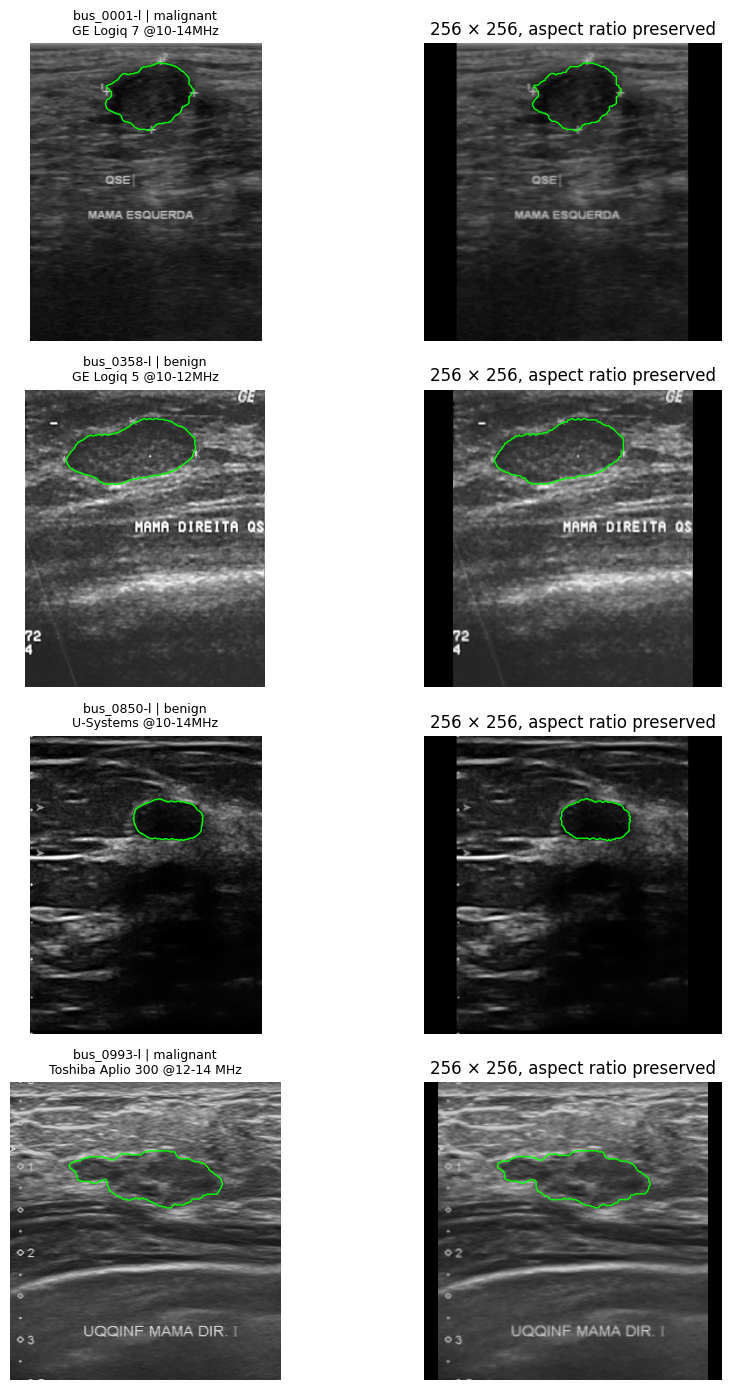

Transformation checks passed for the displayed training examples.
Image range: [0, 1]; mask values: {0, 1}.
Original image files remain unchanged.


In [ ]:
# CELL 13 — DEFINE AND REVIEW ASPECT-RATIO-PRESERVING RESIZING

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_SIZE = 256

def resize_pair(image, mask, size=IMAGE_SIZE):
    """Resize image and mask identically, then centre-pad to a square."""
    if image.size != mask.size:
        raise ValueError("Image and mask dimensions differ.")

    width, height = image.size
    scale = size / max(width, height)
    new_width = max(1, min(size, round(width * scale)))
    new_height = max(1, min(size, round(height * scale)))

    image_resized = image.convert("L").resize(
        (new_width, new_height), Image.Resampling.BILINEAR
    )
    mask_resized = mask.convert("L").resize(
        (new_width, new_height), Image.Resampling.NEAREST
    )

    left = (size - new_width) // 2
    top = (size - new_height) // 2

    image_canvas = Image.new("L", (size, size), color=0)
    mask_canvas = Image.new("L", (size, size), color=0)
    image_canvas.paste(image_resized, (left, top))
    mask_canvas.paste(mask_resized, (left, top))

    image_array = np.asarray(image_canvas, dtype=np.float32) / 255.0
    mask_array = (np.asarray(mask_canvas) > 0).astype(np.float32)

    geometry = {
        "original_width": width,
        "original_height": height,
        "resized_width": new_width,
        "resized_height": new_height,
        "left_padding": left,
        "top_padding": top,
    }
    return image_array, mask_array, geometry

# Review only examples from outer fold 1's training subset.
review_subset = all_splits.loc[
    all_splits["Evaluation_fold"].eq(1)
    & all_splits["Split"].eq("train")
]
review_examples = (
    review_subset.sort_values("ID")
    .groupby("Device", group_keys=False)
    .head(1)
)

fig, axes = plt.subplots(
    len(review_examples), 2,
    figsize=(10, 3.5 * len(review_examples)),
    squeeze=False
)

for i, (_, row) in enumerate(review_examples.iterrows()):
    with Image.open(LOCAL_DATA_ROOT / row["Image_relative_path"]) as im:
        original = im.convert("L")
    with Image.open(LOCAL_DATA_ROOT / row["Mask_relative_path"]) as im:
        original_mask = im.convert("L")

    image_array, mask_array, geometry = resize_pair(
        original, original_mask
    )

    assert image_array.shape == (IMAGE_SIZE, IMAGE_SIZE)
    assert mask_array.shape == image_array.shape
    assert set(np.unique(mask_array)).issubset({0.0, 1.0})
    assert mask_array.sum() > 0

    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].contour(
        np.asarray(original_mask) > 0,
        levels=[0.5], colors=["lime"], linewidths=1
    )
    axes[i, 0].set_title(
        f"{row['ID']} | {row['Pathology']}\n{row['Device']}",
        fontsize=9
    )

    axes[i, 1].imshow(image_array, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].contour(
        mask_array, levels=[0.5], colors=["lime"], linewidths=1
    )
    axes[i, 1].set_title("256 × 256, aspect ratio preserved")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Transformation checks passed for the displayed training examples.")
print("Image range: [0, 1]; mask values: {0, 1}.")
print("Original image files remain unchanged.")

In [ ]:
# CELL 14 — DEFINE DATASETS AND CHECK ONE TRAINING BATCH

import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

class BUSBRADataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = root
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(self.root / row["Image_relative_path"]) as im:
            image = im.convert("L")
        with Image.open(self.root / row["Mask_relative_path"]) as im:
            mask = im.convert("L")

        image, mask, _ = resize_pair(image, mask)

        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }

ACTIVE_FOLD = 1
BATCH_SIZE = 16

fold_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(ACTIVE_FOLD)
].copy()

datasets = {
    split: BUSBRADataset(
        fold_table.loc[fold_table["Split"].eq(split)],
        LOCAL_DATA_ROOT,
        augment=(split == "train")
    )
    for split in ["train", "validation", "test"]
}

# A dedicated generator controls training shuffle order.
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    datasets["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator,
)

validation_loader = DataLoader(
    datasets["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

batch = next(iter(train_loader))

assert batch["image"].shape == (BATCH_SIZE, 1, IMAGE_SIZE, IMAGE_SIZE)
assert batch["mask"].shape == batch["image"].shape
assert torch.isfinite(batch["image"]).all()
assert batch["image"].min() >= 0 and batch["image"].max() <= 1
assert set(torch.unique(batch["mask"]).tolist()).issubset({0.0, 1.0})
assert (batch["mask"].sum(dim=(1, 2, 3)) > 0).all()
assert set(batch["label"].tolist()).issubset({0.0, 1.0})

print(f"Active outer fold: {ACTIVE_FOLD}")
for split, dataset in datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")

print("\nBATCH CHECK")
print("Image shape:", tuple(batch["image"].shape))
print("Mask shape:", tuple(batch["mask"].shape))
print("Label shape:", tuple(batch["label"].shape))
print("Image dtype:", batch["image"].dtype)
print("Image range:",
      float(batch["image"].min()), float(batch["image"].max()))
print("Mask values:", torch.unique(batch["mask"]).tolist())
print("Labels:", batch["label"].tolist())
print("\nAll batch checks passed. No training performed.")

# Reset after inspection so the batch check does not change training order.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
loader_generator.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Active outer fold: 1
train       : 1,186 images
validation  : 313 images
test        : 376 images

BATCH CHECK
Image shape: (16, 1, 256, 256)
Mask shape: (16, 1, 256, 256)
Label shape: (16,)
Image dtype: torch.float32
Image range: 0.0 1.0
Mask values: [0.0, 1.0]
Labels: [0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0]

All batch checks passed. No training performed.


In [ ]:
# CELL 15 — DEFINE FULL-IMAGE REFERENCE CLASSIFIER

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class FullImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)

        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, image):
        # Input: grayscale [B, 1, H, W], range [0, 1].
        image_rgb = image.repeat(1, 3, 1, 1)
        normalised = (image_rgb - self.image_mean) / self.image_std
        return self.backbone(normalised).squeeze(1)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

full_image_model = FullImageClassifier().to(DEVICE)

# Evaluation mode avoids updating BatchNorm statistics during this check.
full_image_model.eval()
with torch.no_grad():
    check_logits = full_image_model(batch["image"][:4].to(DEVICE))

assert check_logits.shape == (4,)
assert torch.isfinite(check_logits).all()

total_parameters = sum(p.numel() for p in full_image_model.parameters())
trainable_parameters = sum(
    p.numel() for p in full_image_model.parameters() if p.requires_grad
)

print("FULL-IMAGE REFERENCE CLASSIFIER")
print("=" * 70)
print("Architecture: ResNet18")
print("Initial weights: ImageNet-1K V1")
print("Device:", DEVICE)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Output shape:", tuple(check_logits.shape))
print("Finite outputs:", bool(torch.isfinite(check_logits).all()))
print("\nForward-pass check passed. No training performed.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 91.3MB/s]


FULL-IMAGE REFERENCE CLASSIFIER
Architecture: ResNet18
Initial weights: ImageNet-1K V1
Device: cuda
Total parameters: 11,177,025
Trainable parameters: 11,177,025
Output shape: (4,)
Finite outputs: True

Forward-pass check passed. No training performed.


In [ ]:
# CELL 16 — TRAINING SETTINGS AND CASE-LEVEL VALIDATION

import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)

RUN_DIR = PROJECT_ROOT / "models" / "full_image_resnet18" / "fold_1"
RUN_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CONFIG = {
    "model": "ResNet18",
    "weights": "ImageNet1K_V1",
    "outer_fold": ACTIVE_FOLD,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "early_stopping_patience": 7,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "loss": "Unweighted BCEWithLogitsLoss",
    "case_weighting": "Each image weighted by inverse images per training case",
    "selection_metric": "Validation case-level ROC-AUC",
    "case_prediction": "Mean image probability within case",
    "diagnostic_threshold": 0.5,
    "augmentation": "Paired horizontal flip, probability 0.5",
}

# Give single-image and two-image cases equal total loss weight.
train_table = datasets["train"].table
train_case_sizes = train_table.groupby("Case").size()
train_id_weights = {
    str(row["ID"]): 1.0 / train_case_sizes.loc[row["Case"]]
    for _, row in train_table.iterrows()
}

# Scale weights to mean 1, preserving a consistent loss scale.
mean_weight = np.mean(list(train_id_weights.values()))
train_id_weights = {
    image_id: float(weight / mean_weight)
    for image_id, weight in train_id_weights.items()
}

criterion = nn.BCEWithLogitsLoss(reduction="none")

optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"],
)

def training_loss(logits, labels, image_ids):
    weights = torch.tensor(
        [train_id_weights[str(image_id)] for image_id in image_ids],
        dtype=logits.dtype,
        device=logits.device,
    )
    return (criterion(logits, labels) * weights).mean()

@torch.inference_mode()
def evaluate_classifier(model, loader):
    model.eval()
    records = []

    for batch_eval in loader:
        images = batch_eval["image"].to(DEVICE, non_blocking=True)
        logits = model(images)
        probabilities = torch.sigmoid(logits).cpu().numpy()

        for image_id, case, label, probability in zip(
            batch_eval["id"],
            batch_eval["case"],
            batch_eval["label"].numpy(),
            probabilities,
        ):
            records.append({
                "ID": image_id,
                "Case": case,
                "Label": int(label),
                "Probability": float(probability),
            })

    image_predictions = pd.DataFrame(records)
    assert image_predictions.groupby("Case")["Label"].nunique().eq(1).all()

    case_predictions = (
        image_predictions.groupby("Case", as_index=False)
        .agg(
            Label=("Label", "first"),
            Probability=("Probability", "mean"),
            Images=("ID", "size"),
        )
    )

    y = case_predictions["Label"].to_numpy()
    p = case_predictions["Probability"].to_numpy()
    assert set(y) == {0, 1}
    assert np.isfinite(p).all()

    metrics = {
        "case_roc_auc": float(roc_auc_score(y, p)),
        "case_average_precision": float(average_precision_score(y, p)),
        "case_balanced_accuracy_at_0.5": float(
            balanced_accuracy_score(y, p >= 0.5)
        ),
        "case_brier_score": float(brier_score_loss(y, p)),
        "cases": int(len(case_predictions)),
    }
    return metrics, image_predictions, case_predictions

(RUN_DIR / "training_config.json").write_text(
    json.dumps(TRAIN_CONFIG, indent=2),
    encoding="utf-8",
)

print(json.dumps(TRAIN_CONFIG, indent=2))
print(f"\nTraining cases: {len(train_case_sizes):,}")
print(f"Checkpoint folder: {RUN_DIR}")
print("Training setup complete. No training performed.")

{
  "model": "ResNet18",
  "weights": "ImageNet1K_V1",
  "outer_fold": 1,
  "seed": 2026,
  "image_size": 256,
  "batch_size": 16,
  "max_epochs": 30,
  "early_stopping_patience": 7,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "gradient_clip_norm": 1.0,
  "loss": "Unweighted BCEWithLogitsLoss",
  "case_weighting": "Each image weighted by inverse images per training case",
  "selection_metric": "Validation case-level ROC-AUC",
  "case_prediction": "Mean image probability within case",
  "diagnostic_threshold": 0.5,
  "augmentation": "Paired horizontal flip, probability 0.5"
}

Training cases: 681
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/full_image_resnet18/fold_1
Training setup complete. No training performed.


In [ ]:
# CELL 17 — TRAIN FULL-IMAGE RESNET18, OUTER FOLD 1

import random
import time
import numpy as np
import pandas as pd
import torch

BEST_PATH = RUN_DIR / "best.pt"
LAST_PATH = RUN_DIR / "last.pt"

def save_checkpoint_atomic(state, path):
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)

start_epoch = 1
best_auc = -float("inf")
epochs_without_improvement = 0
training_history = []

# Resume this run if a latest checkpoint already exists.
if LAST_PATH.exists():
    checkpoint = torch.load(
        LAST_PATH, map_location="cpu", weights_only=False
    )
    assert checkpoint["config"] == TRAIN_CONFIG, (
        "Saved configuration differs from the current configuration."
    )

    full_image_model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])

    # Move optimizer tensors to the model device.
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    start_epoch = checkpoint["epoch"] + 1
    best_auc = checkpoint["best_auc"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    training_history = checkpoint["history"]

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"])
    loader_generator.set_state(checkpoint["loader_rng"])
    if torch.cuda.is_available():
        torch.cuda.set_rng_state_all(checkpoint["cuda_rng"])

    print(f"Resuming after epoch {checkpoint['epoch']}.")
else:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    loader_generator.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    print("Starting training from the initialised model.")

if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
    print("This run has already reached its early-stopping criterion.")
else:
    for epoch in range(start_epoch, TRAIN_CONFIG["max_epochs"] + 1):
        started = time.perf_counter()
        full_image_model.train()
        loss_sum = 0.0
        image_count = 0

        for training_batch in train_loader:
            images = training_batch["image"].to(
                DEVICE, non_blocking=True
            )
            labels = training_batch["label"].to(
                DEVICE, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)
            logits = full_image_model(images)
            loss = training_loss(logits, labels, training_batch["id"])

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite training loss at epoch {epoch}."
                )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                full_image_model.parameters(),
                TRAIN_CONFIG["gradient_clip_norm"],
                error_if_nonfinite=True,
            )
            optimizer.step()

            loss_sum += loss.item() * len(labels)
            image_count += len(labels)

        val_metrics, _, _ = evaluate_classifier(
            full_image_model, validation_loader
        )
        val_auc = val_metrics["case_roc_auc"]
        improved = val_auc > best_auc

        if improved:
            best_auc = val_auc
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        epoch_record = {
            "epoch": epoch,
            "train_weighted_loss": loss_sum / image_count,
            **val_metrics,
            "seconds": time.perf_counter() - started,
        }
        training_history.append(epoch_record)

        state = {
            "epoch": epoch,
            "config": TRAIN_CONFIG,
            "model_state": full_image_model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "best_auc": best_auc,
            "epochs_without_improvement": epochs_without_improvement,
            "history": training_history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": loader_generator.get_state(),
            "cuda_rng": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        if improved:
            save_checkpoint_atomic(state, BEST_PATH)
        save_checkpoint_atomic(state, LAST_PATH)

        pd.DataFrame(training_history).to_csv(
            RUN_DIR / "training_history.csv", index=False
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Loss {epoch_record['train_weighted_loss']:.4f} | "
            f"Val AUC {val_auc:.4f} | "
            f"Val AP {val_metrics['case_average_precision']:.4f} | "
            f"Brier {val_metrics['case_brier_score']:.4f} | "
            f"{epoch_record['seconds']:.1f}s"
            + (" | BEST" if improved else ""),
            flush=True,
        )

        if (
            epochs_without_improvement
            >= TRAIN_CONFIG["early_stopping_patience"]
        ):
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level ROC-AUC: {best_auc:.4f}")
print(f"Best checkpoint: {BEST_PATH}")
print("Outer test partition has not been evaluated.")

Starting training from the initialised model.
Epoch 01 | Loss 0.4908 | Val AUC 0.8781 | Val AP 0.7802 | Brier 0.1468 | 16.2s | BEST
Epoch 02 | Loss 0.3551 | Val AUC 0.8672 | Val AP 0.7996 | Brier 0.1351 | 17.6s
Epoch 03 | Loss 0.2887 | Val AUC 0.8340 | Val AP 0.7410 | Brier 0.1618 | 19.9s
Epoch 04 | Loss 0.1953 | Val AUC 0.8536 | Val AP 0.7739 | Brier 0.1617 | 20.5s
Epoch 05 | Loss 0.1339 | Val AUC 0.7947 | Val AP 0.7134 | Brier 0.1698 | 19.7s
Epoch 06 | Loss 0.1326 | Val AUC 0.8555 | Val AP 0.7597 | Brier 0.1754 | 21.6s
Epoch 07 | Loss 0.1114 | Val AUC 0.8517 | Val AP 0.7960 | Brier 0.1539 | 21.4s
Epoch 08 | Loss 0.0633 | Val AUC 0.8624 | Val AP 0.8025 | Brier 0.1345 | 21.8s
Early stopping reached.

Best validation case-level ROC-AUC: 0.8781
Best checkpoint: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_1/best.pt
Outer test partition has not been evaluated.


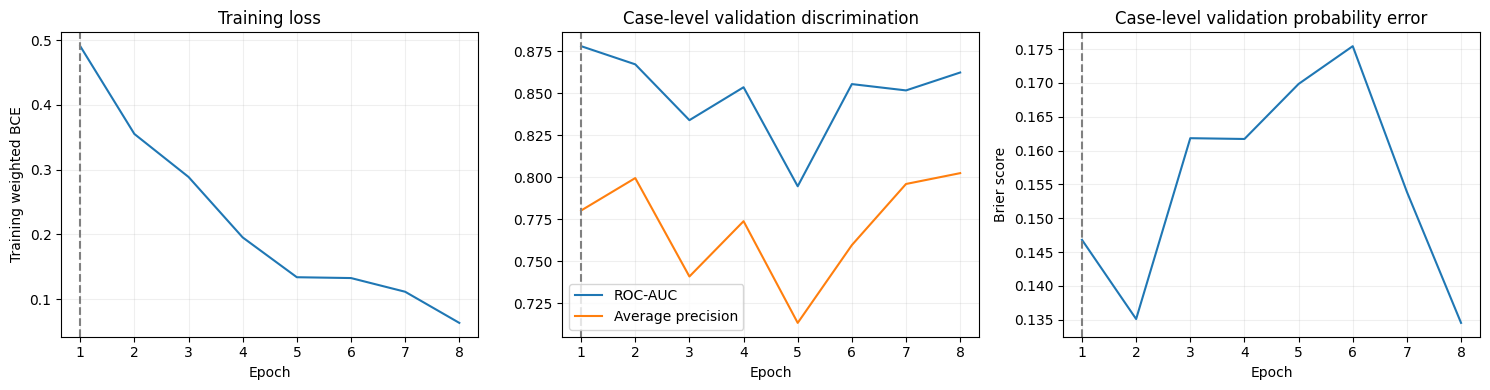

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 1,
  "outer_fold": 1,
  "case_roc_auc": 0.8780564263322883,
  "case_average_precision": 0.7802446085737798,
  "case_balanced_accuracy_at_0.5": 0.6870689655172414,
  "case_brier_score": 0.14680255096014788,
  "cases": 171
}

Validation predictions and learning curves saved.
Outer test partition remains unevaluated.


In [ ]:
# CELL 18 — VERIFY SELECTED CHECKPOINT AND SAVE VALIDATION RESULTS

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

best_checkpoint = torch.load(
    BEST_PATH, map_location="cpu", weights_only=False
)
assert best_checkpoint["config"] == TRAIN_CONFIG

full_image_model.load_state_dict(best_checkpoint["model_state"])
full_image_model.to(DEVICE)
full_image_model.eval()

validation_metrics, validation_image_predictions, validation_case_predictions = (
    evaluate_classifier(full_image_model, validation_loader)
)

assert np.isclose(
    validation_metrics["case_roc_auc"],
    best_checkpoint["best_auc"],
    atol=1e-6,
), "Reloaded validation AUC differs from the saved result."

validation_image_predictions.to_csv(
    RUN_DIR / "validation_image_predictions.csv", index=False
)
validation_case_predictions.to_csv(
    RUN_DIR / "validation_case_predictions.csv", index=False
)

selected_result = {
    "selected_epoch": int(best_checkpoint["epoch"]),
    "outer_fold": ACTIVE_FOLD,
    **validation_metrics,
}
(RUN_DIR / "selected_validation_metrics.json").write_text(
    json.dumps(selected_result, indent=2),
    encoding="utf-8"
)

history_df = pd.read_csv(RUN_DIR / "training_history.csv")
selected_epoch = best_checkpoint["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_df["epoch"], history_df["train_weighted_loss"])
axes[0].set_ylabel("Training weighted BCE")
axes[0].set_title("Training loss")

axes[1].plot(
    history_df["epoch"], history_df["case_roc_auc"], label="ROC-AUC"
)
axes[1].plot(
    history_df["epoch"],
    history_df["case_average_precision"],
    label="Average precision"
)
axes[1].set_title("Case-level validation discrimination")
axes[1].legend()

axes[2].plot(history_df["epoch"], history_df["case_brier_score"])
axes[2].set_ylabel("Brier score")
axes[2].set_title("Case-level validation probability error")

for ax in axes:
    ax.axvline(
        selected_epoch, color="gray", linestyle="--", label="Selected epoch"
    )
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(RUN_DIR / "learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("SELECTED CHECKPOINT — VERIFIED")
print("=" * 70)
print(json.dumps(selected_result, indent=2))
print("\nValidation predictions and learning curves saved.")
print("Outer test partition remains unevaluated.")

In [ ]:
# CELL 19 — PREPARE REFERENCE CLASSIFIER FOR OUTER FOLD 2

import random
import json
import numpy as np
import torch
from torch.utils.data import DataLoader

ACTIVE_FOLD = 5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

fold_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(ACTIVE_FOLD)
].copy()

datasets = {
    split: BUSBRADataset(
        fold_table.loc[fold_table["Split"].eq(split)],
        LOCAL_DATA_ROOT,
        augment=(split == "train")
    )
    for split in ["train", "validation", "test"]
}

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    datasets["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator,
)
validation_loader = DataLoader(
    datasets["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

train_table = datasets["train"].table
train_case_sizes = train_table.groupby("Case").size()
train_id_weights = {
    str(row["ID"]): 1.0 / train_case_sizes.loc[row["Case"]]
    for _, row in train_table.iterrows()
}
mean_weight = np.mean(list(train_id_weights.values()))
train_id_weights = {
    image_id: float(weight / mean_weight)
    for image_id, weight in train_id_weights.items()
}

# Fresh ImageNet initialisation; no fold-1 fitted weights are reused.
full_image_model = FullImageClassifier().to(DEVICE)

TRAIN_CONFIG = {**TRAIN_CONFIG, "outer_fold": ACTIVE_FOLD}
optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"],
)

RUN_DIR = (
    PROJECT_ROOT / "models" / "full_image_resnet18"
    / f"fold_{ACTIVE_FOLD}"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

config_path = RUN_DIR / "training_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == TRAIN_CONFIG
else:
    config_path.write_text(
        json.dumps(TRAIN_CONFIG, indent=2), encoding="utf-8"
    )

print(f"Prepared outer fold {ACTIVE_FOLD}")
for split, dataset in datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("Fresh model initialised.")
print("Checkpoint folder:", RUN_DIR)
print("Existing continuation checkpoint:", (RUN_DIR / "last.pt").exists())

Prepared outer fold 5
train       : 1,192 images
validation  : 300 images
test        : 383 images
Fresh model initialised.
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/full_image_resnet18/fold_5
Existing continuation checkpoint: False


In [ ]:
# CELL 20 — FIVE-FOLD OUTER-TEST EVALUATION OF REFERENCE CLASSIFIER

import json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)

REFERENCE_DIR = PROJECT_ROOT / "models" / "full_image_resnet18"
RESULTS_DIR = PROJECT_ROOT / "results" / "full_image_resnet18"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

fold_results = []
outer_image_tables = []
outer_case_tables = []

# Use a separate model to leave the active training model unchanged.
evaluation_model = FullImageClassifier().to(DEVICE)

for fold in range(1, 6):
    fold_dir = REFERENCE_DIR / f"fold_{fold}"
    checkpoint_path = fold_dir / "best.pt"
    assert checkpoint_path.is_file(), f"Missing: {checkpoint_path}"

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    expected_config = {**TRAIN_CONFIG, "outer_fold": fold}
    assert checkpoint["config"] == expected_config

    test_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & all_splits["Split"].eq("test")
    ].copy()

    development_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & ~all_splits["Split"].eq("test")
    ]
    assert set(test_table["Case"]).isdisjoint(
        set(development_table["Case"])
    )

    test_dataset = BUSBRADataset(
        test_table, LOCAL_DATA_ROOT, augment=False
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    evaluation_model.load_state_dict(checkpoint["model_state"])
    metrics, image_predictions, case_predictions = evaluate_classifier(
        evaluation_model, test_loader
    )

    assert set(image_predictions["ID"]) == set(test_table["ID"])

    image_predictions["Outer_fold"] = fold
    case_predictions["Outer_fold"] = fold

    image_predictions.to_csv(
        fold_dir / "test_image_predictions.csv", index=False
    )
    case_predictions.to_csv(
        fold_dir / "test_case_predictions.csv", index=False
    )

    fold_results.append({
        "Outer_fold": fold,
        "Selected_epoch": checkpoint["epoch"],
        **metrics,
    })
    outer_image_tables.append(image_predictions)
    outer_case_tables.append(case_predictions)

    print(
        f"Fold {fold} | Cases {metrics['cases']} | "
        f"Test AUC {metrics['case_roc_auc']:.4f} | "
        f"AP {metrics['case_average_precision']:.4f}",
        flush=True
    )

reference_oof_images = pd.concat(outer_image_tables, ignore_index=True)
reference_oof_cases = pd.concat(outer_case_tables, ignore_index=True)
reference_fold_results = pd.DataFrame(fold_results)

assert reference_oof_images["ID"].is_unique
assert len(reference_oof_images) == len(manifest)
assert reference_oof_cases["Case"].is_unique
assert len(reference_oof_cases) == manifest["Case"].nunique()
assert set(reference_oof_cases["Case"]) == set(
    manifest["Case"].astype(str)
)

y = reference_oof_cases["Label"].to_numpy()
p = reference_oof_cases["Probability"].to_numpy()

reference_pooled_metrics = {
    "cases": int(len(y)),
    "case_roc_auc": float(roc_auc_score(y, p)),
    "case_average_precision": float(average_precision_score(y, p)),
    "case_balanced_accuracy_at_0.5": float(
        balanced_accuracy_score(y, p >= 0.5)
    ),
    "case_brier_score": float(brier_score_loss(y, p)),
}

reference_oof_images.to_csv(
    RESULTS_DIR / "outer_test_image_predictions.csv", index=False
)
reference_oof_cases.to_csv(
    RESULTS_DIR / "outer_test_case_predictions.csv", index=False
)
reference_fold_results.to_csv(
    RESULTS_DIR / "outer_test_fold_metrics.csv", index=False
)
(RESULTS_DIR / "pooled_outer_test_metrics.json").write_text(
    json.dumps(reference_pooled_metrics, indent=2), encoding="utf-8"
)

print("\nOUTER-TEST RESULTS BY FOLD")
display(reference_fold_results)

print("\nPOOLED OUT-OF-FOLD CASE-LEVEL RESULTS")
print(json.dumps(reference_pooled_metrics, indent=2))

print("\nFOLD METRIC MEANS AND STANDARD DEVIATIONS")
display(reference_fold_results[[
    "case_roc_auc",
    "case_average_precision",
    "case_balanced_accuracy_at_0.5",
    "case_brier_score",
]].agg(["mean", "std"]))

print("\nPredictions and metrics saved:", RESULTS_DIR)

Fold 1 | Cases 212 | Test AUC 0.9584 | AP 0.9369
Fold 2 | Cases 213 | Test AUC 0.8927 | AP 0.8362
Fold 3 | Cases 213 | Test AUC 0.9043 | AP 0.8354
Fold 4 | Cases 214 | Test AUC 0.8866 | AP 0.8008
Fold 5 | Cases 212 | Test AUC 0.8963 | AP 0.8265

OUTER-TEST RESULTS BY FOLD


,Outer_fold,Selected_epoch,case_roc_auc,case_average_precision,case_balanced_accuracy_at_0.5,case_brier_score,cases
0,1,15,0.958435,0.936945,0.875408,0.074431,212
1,2,25,0.892713,0.836197,0.817784,0.126905,213
2,3,18,0.904260,0.835425,0.804209,0.128593,213
3,4,6,0.886557,0.800782,0.813693,0.131224,214
4,5,7,0.896344,0.826540,0.774510,0.126792,212



POOLED OUT-OF-FOLD CASE-LEVEL RESULTS
{
  "cases": 1064,
  "case_roc_auc": 0.90708882085176,
  "case_average_precision": 0.8421199555233918,
  "case_balanced_accuracy_at_0.5": 0.817174515235457,
  "case_brier_score": 0.1176336955373867
}

FOLD METRIC MEANS AND STANDARD DEVIATIONS


,case_roc_auc,case_average_precision,case_balanced_accuracy_at_0.5,case_brier_score
mean,0.907662,0.847178,0.817121,0.117589
std,0.029097,0.052190,0.036715,0.024192



Predictions and metrics saved: /content/drive/MyDrive/BUSBRA_Research/results/full_image_resnet18


In [ ]:
# CELL 21 — CASE-LEVEL BOOTSTRAP CONFIDENCE INTERVALS

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)
from tqdm.auto import tqdm

BOOTSTRAP_REPEATS = 2000
rng = np.random.default_rng(SEED)

predictions = reference_oof_cases.copy()
assert predictions["Case"].is_unique

y = predictions["Label"].to_numpy(dtype=int)
p = predictions["Probability"].to_numpy(dtype=float)

negative_indices = np.flatnonzero(y == 0)
positive_indices = np.flatnonzero(y == 1)

def calculate_metrics(labels, probabilities):
    return {
        "ROC_AUC": roc_auc_score(labels, probabilities),
        "Average_precision": average_precision_score(labels, probabilities),
        "Balanced_accuracy_at_0.5": balanced_accuracy_score(
            labels, probabilities >= 0.5
        ),
        "Brier_score": brier_score_loss(labels, probabilities),
    }

point_estimates = calculate_metrics(y, p)
bootstrap_records = []

for _ in tqdm(range(BOOTSTRAP_REPEATS), desc="Case bootstrap"):
    sampled_indices = np.concatenate([
        rng.choice(
            negative_indices, size=len(negative_indices), replace=True
        ),
        rng.choice(
            positive_indices, size=len(positive_indices), replace=True
        ),
    ])
    bootstrap_records.append(
        calculate_metrics(y[sampled_indices], p[sampled_indices])
    )

reference_bootstrap = pd.DataFrame(bootstrap_records)

reference_confidence_intervals = pd.DataFrame([
    {
        "Metric": metric,
        "Estimate": estimate,
        "CI_95_lower": reference_bootstrap[metric].quantile(0.025),
        "CI_95_upper": reference_bootstrap[metric].quantile(0.975),
    }
    for metric, estimate in point_estimates.items()
])

reference_confidence_intervals.to_csv(
    RESULTS_DIR / "case_bootstrap_confidence_intervals.csv",
    index=False
)
reference_bootstrap.to_csv(
    RESULTS_DIR / "case_bootstrap_samples.csv",
    index=False
)

display(reference_confidence_intervals.round(4))
print(f"\nBootstrap repetitions: {BOOTSTRAP_REPEATS:,}")
print("Sampling unit: case; class counts held fixed.")
print("No models refitted.")

Case bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

,Metric,Estimate,CI_95_lower,CI_95_upper
0,ROC_AUC,0.9071,0.8866,0.9258
1,Average_precision,0.8421,0.8087,0.8737
2,Balanced_accuracy_at_0.5,0.8172,0.7912,0.8421
3,Brier_score,0.1176,0.1027,0.1338



Bootstrap repetitions: 2,000
Sampling unit: case; class counts held fixed.
No models refitted.


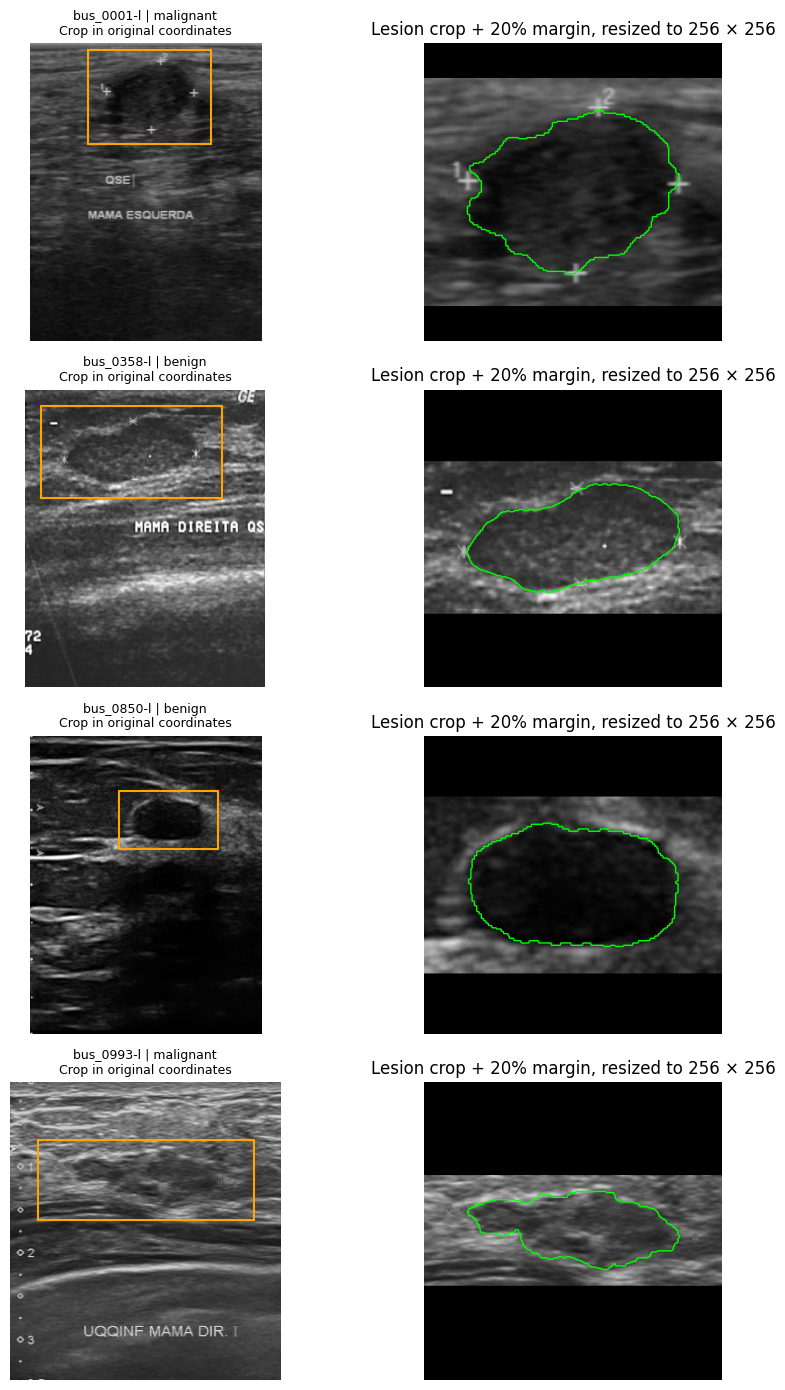

Crop checks passed for displayed training examples.
Green contours are for visual review only, not model inputs.
Empty predicted masks will fall back to the full image.


In [ ]:
# CELL 22 — DEFINE AND REVIEW LESION-GUIDED CROPPING

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

CROP_MARGIN = 0.20

def crop_from_mask(image, mask, margin=CROP_MARGIN):
    """
    Crop to the foreground bounding box, expanded on each side by
    margin × bounding-box width/height. Empty masks use the full image.
    Coordinates refer to original image pixels.
    """
    if image.size != mask.size:
        raise ValueError("Image and mask dimensions differ.")

    binary_mask = np.asarray(mask.convert("L")) > 0
    ys, xs = np.where(binary_mask)

    if len(xs) == 0:
        return image.copy(), mask.copy(), {
            "box": (0, 0, image.width, image.height),
            "fallback": True,
        }

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1

    pad_x = int(np.ceil(margin * (x1 - x0)))
    pad_y = int(np.ceil(margin * (y1 - y0)))

    box = (
        max(0, x0 - pad_x),
        max(0, y0 - pad_y),
        min(image.width, x1 + pad_x),
        min(image.height, y1 + pad_y),
    )

    return image.crop(box), mask.crop(box), {
        "box": box,
        "fallback": False,
    }

# Use only fold-1 training examples for visual review.
crop_review = (
    all_splits.loc[
        all_splits["Evaluation_fold"].eq(1)
        & all_splits["Split"].eq("train")
    ]
    .sort_values("ID")
    .groupby("Device", group_keys=False)
    .head(1)
)

fig, axes = plt.subplots(
    len(crop_review), 2,
    figsize=(10, 3.5 * len(crop_review)),
    squeeze=False
)

for i, (_, row) in enumerate(crop_review.iterrows()):
    with Image.open(LOCAL_DATA_ROOT / row["Image_relative_path"]) as im:
        image = im.convert("L")
    with Image.open(LOCAL_DATA_ROOT / row["Mask_relative_path"]) as im:
        mask = im.convert("L")

    cropped_image, cropped_mask, crop_info = crop_from_mask(image, mask)
    resized_image, resized_mask, _ = resize_pair(
        cropped_image, cropped_mask
    )

    assert not crop_info["fallback"]
    assert resized_mask.sum() > 0

    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    x0, y0, x1, y1 = crop_info["box"]
    axes[i, 0].add_patch(plt.Rectangle(
        (x0, y0), x1 - x0, y1 - y0,
        fill=False, edgecolor="orange", linewidth=1.5
    ))
    axes[i, 0].set_title(
        f"{row['ID']} | {row['Pathology']}\nCrop in original coordinates",
        fontsize=9
    )

    axes[i, 1].imshow(resized_image, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].contour(
        resized_mask, levels=[0.5], colors=["lime"], linewidths=1
    )
    axes[i, 1].set_title("Lesion crop + 20% margin, resized to 256 × 256")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Crop checks passed for displayed training examples.")
print("Green contours are for visual review only, not model inputs.")
print("Empty predicted masks will fall back to the full image.")

In [ ]:
# CELL 23 — PREPARE EXPERT-MASK-GUIDED CLASSIFIER, FOLD 1

import random
import json
import numpy as np
import torch
from torch.utils.data import DataLoader
from PIL import Image

class ExpertCropDataset(BUSBRADataset):
    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(self.root / row["Image_relative_path"]) as im:
            image = im.convert("L")
        with Image.open(self.root / row["Mask_relative_path"]) as im:
            mask = im.convert("L")

        image, mask, _ = crop_from_mask(image, mask)
        image, mask, _ = resize_pair(image, mask)

        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }

ACTIVE_FOLD = 5

# Load the saved reference configuration for a matched comparison.
reference_config_path = (
    PROJECT_ROOT / "models" / "full_image_resnet18"
    / f"fold_{ACTIVE_FOLD}" / "training_config.json"
)
reference_config = json.loads(reference_config_path.read_text())

TRAIN_CONFIG = {
    **reference_config,
    "outer_fold": ACTIVE_FOLD,
    "input_mode": "Expert-mask bounding-box crop",
    "crop_margin_per_side": CROP_MARGIN,
    "empty_mask_policy": "Full-image fallback",
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

fold_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(ACTIVE_FOLD)
].copy()

datasets = {
    split: ExpertCropDataset(
        fold_table.loc[fold_table["Split"].eq(split)],
        LOCAL_DATA_ROOT,
        augment=(split == "train")
    )
    for split in ["train", "validation", "test"]
}

loader_generator = torch.Generator().manual_seed(SEED)
loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,
    "pin_memory": torch.cuda.is_available(),
}

train_loader = DataLoader(
    datasets["train"], shuffle=True,
    generator=loader_generator, **loader_options
)
validation_loader = DataLoader(
    datasets["validation"], shuffle=False, **loader_options
)

train_table = datasets["train"].table
train_case_sizes = train_table.groupby("Case").size()
train_id_weights = {
    str(row["ID"]): 1.0 / train_case_sizes.loc[row["Case"]]
    for _, row in train_table.iterrows()
}
mean_weight = np.mean(list(train_id_weights.values()))
train_id_weights = {
    key: float(value / mean_weight)
    for key, value in train_id_weights.items()
}

# Reuse the training-loop variable name, with a fresh model.
full_image_model = FullImageClassifier().to(DEVICE)
optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"],
)

RUN_DIR = (
    PROJECT_ROOT / "models" / "expert_crop_resnet18"
    / f"fold_{ACTIVE_FOLD}"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

config_path = RUN_DIR / "training_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == TRAIN_CONFIG
else:
    config_path.write_text(
        json.dumps(TRAIN_CONFIG, indent=2), encoding="utf-8"
    )

# Deterministic shape check without consuming training augmentation RNG.
sample = datasets["validation"][0]
assert sample["image"].shape == (1, IMAGE_SIZE, IMAGE_SIZE)
assert sample["mask"].sum() > 0
assert torch.isfinite(sample["image"]).all()

print("EXPERT-CROP CLASSIFIER READY")
print("=" * 70)
print("Outer fold:", ACTIVE_FOLD)
for split, dataset in datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("Crop margin per side:", CROP_MARGIN)
print("Fresh ImageNet model initialised.")
print("Checkpoint folder:", RUN_DIR)
print("No training performed.")

EXPERT-CROP CLASSIFIER READY
Outer fold: 5
train       : 1,192 images
validation  : 300 images
test        : 383 images
Crop margin per side: 0.2
Fresh ImageNet model initialised.
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/expert_crop_resnet18/fold_5
No training performed.


In [ ]:
# CELL 24 — EXPERT-CROP OUTER-TEST EVALUATION

import json
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)

EXPERT_MODEL_DIR = PROJECT_ROOT / "models" / "expert_crop_resnet18"
EXPERT_RESULTS_DIR = PROJECT_ROOT / "results" / "expert_crop_resnet18"
EXPERT_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

expert_fold_records = []
expert_image_tables = []
expert_case_tables = []

expert_evaluation_model = FullImageClassifier().to(DEVICE)

for fold in range(1, 6):
    fold_dir = EXPERT_MODEL_DIR / f"fold_{fold}"
    checkpoint = torch.load(
        fold_dir / "best.pt",
        map_location="cpu",
        weights_only=False,
    )

    saved_config = json.loads(
        (fold_dir / "training_config.json").read_text()
    )
    assert checkpoint["config"] == saved_config
    assert saved_config["outer_fold"] == fold
    assert saved_config["input_mode"] == "Expert-mask bounding-box crop"
    assert saved_config["crop_margin_per_side"] == CROP_MARGIN

    test_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & all_splits["Split"].eq("test")
    ].copy()

    development_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & ~all_splits["Split"].eq("test")
    ]
    assert set(test_table["Case"]).isdisjoint(
        set(development_table["Case"])
    )

    loader = DataLoader(
        ExpertCropDataset(
            test_table, LOCAL_DATA_ROOT, augment=False
        ),
        batch_size=saved_config["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    expert_evaluation_model.load_state_dict(checkpoint["model_state"])
    metrics, image_predictions, case_predictions = evaluate_classifier(
        expert_evaluation_model, loader
    )

    assert image_predictions["ID"].is_unique
    assert set(image_predictions["ID"]) == set(test_table["ID"])

    image_predictions["Outer_fold"] = fold
    case_predictions["Outer_fold"] = fold

    image_predictions.to_csv(
        fold_dir / "test_image_predictions.csv", index=False
    )
    case_predictions.to_csv(
        fold_dir / "test_case_predictions.csv", index=False
    )

    expert_image_tables.append(image_predictions)
    expert_case_tables.append(case_predictions)
    expert_fold_records.append({
        "Outer_fold": fold,
        "Selected_epoch": int(checkpoint["epoch"]),
        **metrics,
    })

    print(
        f"Fold {fold} | Cases {metrics['cases']} | "
        f"Test AUC {metrics['case_roc_auc']:.4f} | "
        f"AP {metrics['case_average_precision']:.4f}",
        flush=True,
    )

expert_oof_images = pd.concat(expert_image_tables, ignore_index=True)
expert_oof_cases = pd.concat(expert_case_tables, ignore_index=True)
expert_fold_results = pd.DataFrame(expert_fold_records)

assert expert_oof_images["ID"].is_unique
assert len(expert_oof_images) == len(manifest)
assert expert_oof_cases["Case"].is_unique
assert set(expert_oof_cases["Case"]) == set(manifest["Case"].astype(str))

y = expert_oof_cases["Label"].to_numpy()
p = expert_oof_cases["Probability"].to_numpy()

expert_pooled_metrics = {
    "cases": int(len(y)),
    "case_roc_auc": float(roc_auc_score(y, p)),
    "case_average_precision": float(average_precision_score(y, p)),
    "case_balanced_accuracy_at_0.5": float(
        balanced_accuracy_score(y, p >= 0.5)
    ),
    "case_brier_score": float(brier_score_loss(y, p)),
}

expert_oof_images.to_csv(
    EXPERT_RESULTS_DIR / "outer_test_image_predictions.csv", index=False
)
expert_oof_cases.to_csv(
    EXPERT_RESULTS_DIR / "outer_test_case_predictions.csv", index=False
)
expert_fold_results.to_csv(
    EXPERT_RESULTS_DIR / "outer_test_fold_metrics.csv", index=False
)
(EXPERT_RESULTS_DIR / "pooled_outer_test_metrics.json").write_text(
    json.dumps(expert_pooled_metrics, indent=2), encoding="utf-8"
)

print("\nEXPERT-CROP OUTER-TEST RESULTS")
display(expert_fold_results)

print("\nPOOLED CASE-LEVEL RESULTS")
print(json.dumps(expert_pooled_metrics, indent=2))
print("\nSaved:", EXPERT_RESULTS_DIR)

Fold 1 | Cases 212 | Test AUC 0.9331 | AP 0.8832
Fold 2 | Cases 213 | Test AUC 0.9258 | AP 0.8848
Fold 3 | Cases 213 | Test AUC 0.8946 | AP 0.8427
Fold 4 | Cases 214 | Test AUC 0.8777 | AP 0.7990
Fold 5 | Cases 212 | Test AUC 0.8983 | AP 0.8407

EXPERT-CROP OUTER-TEST RESULTS


,Outer_fold,Selected_epoch,case_roc_auc,case_average_precision,case_balanced_accuracy_at_0.5,case_brier_score,cases
0,1,1,0.933109,0.883160,0.780229,0.108576,212
1,2,5,0.925825,0.884823,0.750453,0.115760,213
2,3,13,0.894625,0.842682,0.834077,0.128797,213
3,4,8,0.877661,0.798974,0.823038,0.146586,214
4,5,6,0.898284,0.840670,0.834967,0.123068,212



POOLED CASE-LEVEL RESULTS
{
  "cases": 1064,
  "case_roc_auc": 0.8885487032447231,
  "case_average_precision": 0.8139510391181208,
  "case_balanced_accuracy_at_0.5": 0.8044013542628501,
  "case_brier_score": 0.12459444531409829
}

Saved: /content/drive/MyDrive/BUSBRA_Research/results/expert_crop_resnet18


In [ ]:
# CELL 25 — PAIRED COMPARISON: EXPERT CROP VS FULL IMAGE

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss
)
from tqdm.auto import tqdm

COMPARISON_DIR = PROJECT_ROOT / "results" / "paired_comparisons"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

reference = pd.read_csv(
    PROJECT_ROOT / "results" / "full_image_resnet18"
    / "outer_test_case_predictions.csv",
    dtype={"Case": str}
)
expert = pd.read_csv(
    EXPERT_RESULTS_DIR / "outer_test_case_predictions.csv",
    dtype={"Case": str}
)

assert reference["Case"].is_unique and expert["Case"].is_unique
assert set(reference["Case"]) == set(expert["Case"])

paired_predictions = reference.merge(
    expert,
    on="Case",
    suffixes=("_full", "_crop"),
    validate="one_to_one"
).reset_index(drop=True)

assert paired_predictions["Label_full"].eq(
    paired_predictions["Label_crop"]
).all()
assert paired_predictions["Outer_fold_full"].eq(
    paired_predictions["Outer_fold_crop"]
).all()

y = paired_predictions["Label_full"].to_numpy(dtype=int)
p_full = paired_predictions["Probability_full"].to_numpy()
p_crop = paired_predictions["Probability_crop"].to_numpy()
folds = paired_predictions["Outer_fold_full"].to_numpy()

def comparison_metrics(labels, probabilities):
    return np.array([
        roc_auc_score(labels, probabilities),
        average_precision_score(labels, probabilities),
        balanced_accuracy_score(labels, probabilities >= 0.5),
        brier_score_loss(labels, probabilities),
    ])

metric_names = [
    "ROC_AUC", "Average_precision",
    "Balanced_accuracy_at_0.5", "Brier_score"
]

full_point = comparison_metrics(y, p_full)
crop_point = comparison_metrics(y, p_crop)

fold_rows = []
for fold in sorted(np.unique(folds)):
    idx = np.flatnonzero(folds == fold)
    difference = (
        comparison_metrics(y[idx], p_crop[idx])
        - comparison_metrics(y[idx], p_full[idx])
    )
    fold_rows.append({
        "Outer_fold": int(fold),
        **dict(zip(metric_names, difference))
    })

fold_differences = pd.DataFrame(fold_rows)

# Stratified, paired resampling within each outer fold and class.
strata = [
    np.flatnonzero((folds == fold) & (y == label))
    for fold in sorted(np.unique(folds))
    for label in [0, 1]
]
assert all(len(indices) > 0 for indices in strata)

rng = np.random.default_rng(SEED)
paired_bootstrap_differences = []

for _ in tqdm(range(2000), desc="Paired case bootstrap"):
    indices = np.concatenate([
        rng.choice(group, size=len(group), replace=True)
        for group in strata
    ])
    paired_bootstrap_differences.append(
        comparison_metrics(y[indices], p_crop[indices])
        - comparison_metrics(y[indices], p_full[indices])
    )

paired_bootstrap_differences = pd.DataFrame(
    paired_bootstrap_differences, columns=metric_names
)

paired_comparison_summary = pd.DataFrame({
    "Metric": metric_names,
    "Full_image": full_point,
    "Expert_crop": crop_point,
    "Difference_crop_minus_full": crop_point - full_point,
    "Difference_CI_95_lower": [
        paired_bootstrap_differences[c].quantile(0.025)
        for c in metric_names
    ],
    "Difference_CI_95_upper": [
        paired_bootstrap_differences[c].quantile(0.975)
        for c in metric_names
    ],
})

paired_predictions.to_csv(
    COMPARISON_DIR / "full_vs_expert_case_predictions.csv", index=False
)
paired_comparison_summary.to_csv(
    COMPARISON_DIR / "full_vs_expert_paired_summary.csv", index=False
)
fold_differences.to_csv(
    COMPARISON_DIR / "full_vs_expert_fold_differences.csv", index=False
)
paired_bootstrap_differences.to_csv(
    COMPARISON_DIR / "full_vs_expert_bootstrap_differences.csv", index=False
)

print("POOLED PAIRED COMPARISON")
display(paired_comparison_summary.round(4))

print("\nWITHIN-FOLD DIFFERENCES — CROP MINUS FULL IMAGE")
display(fold_differences.round(4))

print("\nMean within-fold differences:")
print(fold_differences[metric_names].mean().round(4).to_string())

print("\nPositive differences favour cropping except for Brier score.")
print("Intervals are conditional on the fitted models; no retraining.")

Paired case bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

POOLED PAIRED COMPARISON


,Metric,Full_image,Expert_crop,Difference_crop_minus_full,Difference_CI_95_lower,Difference_CI_95_upper
0,ROC_AUC,0.9071,0.8885,-0.0185,-0.0410,0.0020
1,Average_precision,0.8421,0.8140,-0.0282,-0.0613,0.0055
2,Balanced_accuracy_at_0.5,0.8172,0.8044,-0.0128,-0.0392,0.0147
3,Brier_score,0.1176,0.1246,0.0070,-0.0088,0.0229



WITHIN-FOLD DIFFERENCES — CROP MINUS FULL IMAGE


,Outer_fold,ROC_AUC,Average_precision,Balanced_accuracy_at_0.5,Brier_score
0,1,-0.0253,-0.0538,-0.0952,0.0341
1,2,0.0331,0.0486,-0.0673,-0.0111
2,3,-0.0096,0.0073,0.0299,0.0002
3,4,-0.0089,-0.0018,0.0093,0.0154
4,5,0.0019,0.0141,0.0605,-0.0037



Mean within-fold differences:
ROC_AUC                    -0.0018
Average_precision           0.0029
Balanced_accuracy_at_0.5   -0.0126
Brier_score                 0.0070

Positive differences favour cropping except for Brier score.
Intervals are conditional on the fitted models; no retraining.


In [ ]:
# CELL 26 — PREPARE FULL-IMAGE SEGMENTATION DATA, FOLD 1

import json
import torch
from torch.utils.data import DataLoader

SEGMENTATION_FOLD = 5
SEGMENTATION_BATCH_SIZE = 8

segmentation_fold_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(SEGMENTATION_FOLD)
].copy()

# The original dataset class returns full images and aligned expert masks.
segmentation_datasets = {
    split: BUSBRADataset(
        segmentation_fold_table.loc[
            segmentation_fold_table["Split"].eq(split)
        ],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split in ["train", "validation", "test"]
}

segmentation_generator = torch.Generator().manual_seed(SEED)

segmentation_train_loader = DataLoader(
    segmentation_datasets["train"],
    batch_size=SEGMENTATION_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=segmentation_generator,
)

segmentation_validation_loader = DataLoader(
    segmentation_datasets["validation"],
    batch_size=SEGMENTATION_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_resnet18_unet"
    / f"fold_{SEGMENTATION_FOLD}"
)
SEGMENTATION_RUN_DIR.mkdir(parents=True, exist_ok=True)

segmentation_data_config = {
    "outer_fold": SEGMENTATION_FOLD,
    "input": "Full grayscale image",
    "target": "Expert binary lesion mask",
    "image_size": IMAGE_SIZE,
    "batch_size": SEGMENTATION_BATCH_SIZE,
    "resize": "Aspect-ratio-preserving resize with centre padding",
    "augmentation": "Paired horizontal flip, probability 0.5",
    "partition_source": "Existing saved case-separated partitions",
    "seed": SEED,
}

config_path = SEGMENTATION_RUN_DIR / "data_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == segmentation_data_config
else:
    config_path.write_text(
        json.dumps(segmentation_data_config, indent=2),
        encoding="utf-8",
    )

sample = segmentation_datasets["validation"][0]
assert sample["image"].shape == (1, IMAGE_SIZE, IMAGE_SIZE)
assert sample["mask"].shape == sample["image"].shape
assert sample["mask"].sum() > 0
assert set(torch.unique(sample["mask"]).tolist()).issubset({0.0, 1.0})

print("SEGMENTATION DATA READY")
print("=" * 70)
for split, dataset in segmentation_datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("Sample image shape:", tuple(sample["image"].shape))
print("Sample mask shape:", tuple(sample["mask"].shape))
print("Output folder:", SEGMENTATION_RUN_DIR)
print("No segmentation model trained.")

SEGMENTATION DATA READY
train       : 1,192 images
validation  : 300 images
test        : 383 images
Sample image shape: (1, 256, 256)
Sample mask shape: (1, 256, 256)
Output folder: /content/drive/MyDrive/BUSBRA_Research/models/segmentation_resnet18_unet/fold_5
No segmentation model trained.


In [ ]:
# CELL 27 — DEFINE RESNET18 U-NET AND CHECK OUTPUT SHAPE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

class DecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv2d(
                input_channels + skip_channels,
                output_channels, 3, padding=1, bias=False
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                output_channels, output_channels,
                3, padding=1, bias=False
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, features, skip):
        features = F.interpolate(
            features, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )
        return self.convolutions(torch.cat([features, skip], dim=1))

class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4

        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)
        self.decoder0 = DecoderBlock(64, 64, 32)

        self.output_head = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 1),
        )

        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, image):
        original_size = image.shape[-2:]
        image = image.repeat(1, 3, 1, 1)
        image = (image - self.image_mean) / self.image_std

        stem = self.stem(image)
        level1 = self.encoder1(self.pool(stem))
        level2 = self.encoder2(level1)
        level3 = self.encoder3(level2)
        level4 = self.encoder4(level3)

        features = self.decoder3(level4, level3)
        features = self.decoder2(features, level2)
        features = self.decoder1(features, level1)
        features = self.decoder0(features, stem)
        features = F.interpolate(
            features, size=original_size,
            mode="bilinear", align_corners=False
        )
        return self.output_head(features)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

segmentation_model = ResNet18UNet().to(DEVICE)
segmentation_model.eval()

check_image = (
    segmentation_datasets["validation"][0]["image"]
    .unsqueeze(0).to(DEVICE)
)

with torch.inference_mode():
    segmentation_logits = segmentation_model(check_image)

assert segmentation_logits.shape == (1, 1, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(segmentation_logits).all()

print("SEGMENTATION MODEL CHECK")
print("=" * 70)
print("Architecture: U-Net with ImageNet-pretrained ResNet18 encoder")
print("Device:", DEVICE)
print("Parameters:",
      f"{sum(p.numel() for p in segmentation_model.parameters()):,}")
print("Input shape:", tuple(check_image.shape))
print("Output shape:", tuple(segmentation_logits.shape))
print("Finite outputs:", bool(torch.isfinite(segmentation_logits).all()))
print("Forward-pass check passed. No training performed.")

SEGMENTATION MODEL CHECK
Architecture: U-Net with ImageNet-pretrained ResNet18 encoder
Device: cuda
Parameters: 14,325,729
Input shape: (1, 1, 256, 256)
Output shape: (1, 1, 256, 256)
Finite outputs: True
Forward-pass check passed. No training performed.


In [ ]:
# CELL 28 — SEGMENTATION LOSS, VALIDATION, AND TRAINING SETTINGS

import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

SEGMENTATION_CONFIG = {
    **segmentation_data_config,
    "architecture": "ResNet18UNet",
    "encoder_weights": "ImageNet1K_V1",
    "max_epochs": 40,
    "early_stopping_patience": 8,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "loss": "0.5 * pixel_mean_BCE + 0.5 * soft_Dice_loss",
    "case_weighting": "Inverse training images per case, normalised to mean 1",
    "selection_metric": "Validation mean case Dice at threshold 0.5",
    "prediction_threshold": 0.5,
    "postprocessing": "None",
    "metric_aggregation": "Mean image metric per case, then mean across cases",
}

seg_train_table = segmentation_datasets["train"].table
seg_case_sizes = seg_train_table.groupby("Case").size()

segmentation_id_weights = {
    str(row["ID"]): 1.0 / seg_case_sizes.loc[row["Case"]]
    for _, row in seg_train_table.iterrows()
}
seg_mean_weight = np.mean(list(segmentation_id_weights.values()))
segmentation_id_weights = {
    key: float(value / seg_mean_weight)
    for key, value in segmentation_id_weights.items()
}

def segmentation_loss(logits, masks, image_ids):
    probabilities = torch.sigmoid(logits)
    dimensions = (1, 2, 3)

    bce = F.binary_cross_entropy_with_logits(
        logits, masks, reduction="none"
    ).mean(dim=dimensions)

    intersection = (probabilities * masks).sum(dim=dimensions)
    soft_dice = (
        (2 * intersection + 1e-6)
        / (
            probabilities.sum(dim=dimensions)
            + masks.sum(dim=dimensions)
            + 1e-6
        )
    )
    per_image_loss = 0.5 * bce + 0.5 * (1 - soft_dice)

    weights = torch.tensor(
        [segmentation_id_weights[str(i)] for i in image_ids],
        dtype=logits.dtype,
        device=logits.device,
    )
    return (per_image_loss * weights).mean()

@torch.inference_mode()
def evaluate_segmentation(model, loader):
    model.eval()
    records = []

    for evaluation_batch in loader:
        images = evaluation_batch["image"].to(DEVICE, non_blocking=True)
        masks = evaluation_batch["mask"].to(DEVICE, non_blocking=True) > 0.5

        probabilities = torch.sigmoid(model(images))
        assert torch.isfinite(probabilities).all()

        predictions = probabilities >= 0.5
        dimensions = (1, 2, 3)

        intersection = (predictions & masks).sum(dim=dimensions).float()
        predicted_area = predictions.sum(dim=dimensions).float()
        true_area = masks.sum(dim=dimensions).float()
        union = predicted_area + true_area - intersection

        dice = (2 * intersection + 1e-6) / (
            predicted_area + true_area + 1e-6
        )
        iou = (intersection + 1e-6) / (union + 1e-6)

        for image_id, case, d, j, empty in zip(
            evaluation_batch["id"],
            evaluation_batch["case"],
            dice.cpu().tolist(),
            iou.cpu().tolist(),
            predicted_area.eq(0).cpu().tolist(),
        ):
            records.append({
                "ID": image_id,
                "Case": case,
                "Dice": float(d),
                "IoU": float(j),
                "Empty_prediction": bool(empty),
            })

    image_scores = pd.DataFrame(records)
    case_scores = (
        image_scores.groupby("Case", as_index=False)
        .agg(
            Dice=("Dice", "mean"),
            IoU=("IoU", "mean"),
            Images=("ID", "size"),
        )
    )
    metrics = {
        "case_dice": float(case_scores["Dice"].mean()),
        "case_iou": float(case_scores["IoU"].mean()),
        "empty_prediction_images": int(
            image_scores["Empty_prediction"].sum()
        ),
        "cases": int(len(case_scores)),
    }
    return metrics, image_scores, case_scores

segmentation_optimizer = torch.optim.AdamW(
    segmentation_model.parameters(),
    lr=SEGMENTATION_CONFIG["learning_rate"],
    weight_decay=SEGMENTATION_CONFIG["weight_decay"],
)

seg_config_path = SEGMENTATION_RUN_DIR / "training_config.json"
if seg_config_path.exists():
    assert json.loads(seg_config_path.read_text()) == SEGMENTATION_CONFIG
else:
    seg_config_path.write_text(
        json.dumps(SEGMENTATION_CONFIG, indent=2),
        encoding="utf-8",
    )

print(json.dumps(SEGMENTATION_CONFIG, indent=2))
print("\nSegmentation training setup complete. No training performed.")

{
  "outer_fold": 5,
  "input": "Full grayscale image",
  "target": "Expert binary lesion mask",
  "image_size": 256,
  "batch_size": 8,
  "resize": "Aspect-ratio-preserving resize with centre padding",
  "augmentation": "Paired horizontal flip, probability 0.5",
  "partition_source": "Existing saved case-separated partitions",
  "seed": 2026,
  "architecture": "ResNet18UNet",
  "encoder_weights": "ImageNet1K_V1",
  "max_epochs": 40,
  "early_stopping_patience": 8,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "gradient_clip_norm": 1.0,
  "loss": "0.5 * pixel_mean_BCE + 0.5 * soft_Dice_loss",
  "case_weighting": "Inverse training images per case, normalised to mean 1",
  "selection_metric": "Validation mean case Dice at threshold 0.5",
  "prediction_threshold": 0.5,
  "postprocessing": "None",
  "metric_aggregation": "Mean image metric per case, then mean across cases"
}

Segmentation training setup complete. No training performed.


In [ ]:
# RECOVERY CELL R1 — MOUNT DRIVE AND CHECK SAVED PROGRESS

from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

drive.mount("/content/drive")

DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")
PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
AUDIT_DIR = PROJECT_ROOT / "audit"
LOCAL_DATA_ROOT = Path("/content/BUSBRA")

print("RUNTIME")
print("=" * 70)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nSAVED DATA")
for path in [
    AUDIT_DIR / "analysis_manifest.csv",
    PROJECT_ROOT / "splits" / "outer_fold_2.csv",
    PROJECT_ROOT / "splits"
    / "segmentation_crossfit_outer_2" / "inner_fold_3.csv",
]:
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path}")

print("\nINNER SEGMENTATION CHECKPOINTS — OUTER FOLD 2")
rows = []
for inner_fold in [1, 2, 3]:
    folder = (
        PROJECT_ROOT / "models" / "segmentation_crossfit"
        / "outer_fold_2" / f"inner_fold_{inner_fold}"
    )
    rows.append({
        "Inner_fold": inner_fold,
        "Best_checkpoint": (folder / "best.pt").is_file(),
        "Latest_checkpoint": (folder / "last.pt").is_file(),
        "Saved_validation_metrics": (
            folder / "selected_validation_metrics.json"
        ).is_file(),
    })

display(pd.DataFrame(rows))

print("\nLOCAL CACHE")
print("Images:", len(list((LOCAL_DATA_ROOT / "Images").glob("*.png"))))
print("Masks:", len(list((LOCAL_DATA_ROOT / "Masks").glob("*.png"))))

Mounted at /content/drive
RUNTIME
GPU available: True
GPU: Tesla T4

SAVED DATA
FOUND: /content/drive/MyDrive/BUSBRA_Research/audit/analysis_manifest.csv
FOUND: /content/drive/MyDrive/BUSBRA_Research/splits/outer_fold_2.csv
FOUND: /content/drive/MyDrive/BUSBRA_Research/splits/segmentation_crossfit_outer_2/inner_fold_3.csv

INNER SEGMENTATION CHECKPOINTS — OUTER FOLD 2


,Inner_fold,Best_checkpoint,Latest_checkpoint,Saved_validation_metrics
0,1,True,True,True
1,2,True,True,True
2,3,True,True,False



LOCAL CACHE
Images: 0
Masks: 0


In [ ]:
# RECOVERY R2 — inspect saved progress; no training
import json
import torch

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / "outer_fold_2" / "inner_fold_3"
)

for filename in ("best.pt", "last.pt"):
    path = SEGMENTATION_RUN_DIR / filename
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )  # Your own saved checkpoint

    print(f"\n{filename}")
    for key in ("epoch", "best_dice", "stale_epochs"):
        print(f"{key}: {checkpoint.get(key, 'not recorded')}")

    history = checkpoint.get("history", [])
    print("Saved history entries:", len(history))
    if len(history):
        print("Last history entry:", history[-1])

    del checkpoint

config_path = SEGMENTATION_RUN_DIR / "training_config.json"
if config_path.exists():
    with config_path.open() as f:
        recovered_segmentation_config = json.load(f)
    print("\nSaved training configuration:")
    print(json.dumps(recovered_segmentation_config, indent=2))

print("\nInspection complete. No training performed.")


best.pt
epoch: 13
best_dice: 0.8960221458922376
stale_epochs: 0
Saved history entries: 13
Last history entry: {'epoch': 13, 'train_weighted_loss': 0.05458326944813561, 'case_dice': 0.8960221458922376, 'case_iou': 0.8183834233454296, 'empty_prediction_images': 0, 'cases': 91, 'seconds': 10.655645640003058}

last.pt
epoch: 14
best_dice: 0.8960221458922376
stale_epochs: 1
Saved history entries: 14
Last history entry: {'epoch': 14, 'train_weighted_loss': 0.05220421272725724, 'case_dice': 0.8946793036813827, 'case_iou': 0.8193989011297421, 'empty_prediction_images': 1, 'cases': 91, 'seconds': 10.57585627500157}

Saved training configuration:
{
  "outer_fold": 2,
  "input": "Full grayscale image",
  "target": "Expert binary lesion mask",
  "image_size": 256,
  "batch_size": 8,
  "resize": "Aspect-ratio-preserving resize with centre padding",
  "augmentation": "Paired horizontal flip, probability 0.5",
  "partition_source": "Saved inner case-separated cross-fitting partitions",
  "seed": 202

In [ ]:
# RECOVERY R3 — restore local cache; no training
from pathlib import Path
import shutil
import pandas as pd
from tqdm.auto import tqdm

DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")
PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
LOCAL_DATA_ROOT = Path("/content/BUSBRA")

manifest = pd.read_csv(
    PROJECT_ROOT / "audit" / "analysis_manifest.csv"
)

relative_paths = sorted(set(
    manifest["Image_relative_path"].tolist()
    + manifest["Mask_relative_path"].tolist()
))

copied = 0
existing = 0
failures = []

for relative_path in tqdm(relative_paths, desc="Restoring local cache"):
    source = DATA_ROOT / relative_path
    destination = LOCAL_DATA_ROOT / relative_path

    if destination.exists() and destination.stat().st_size > 0:
        existing += 1
        continue

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".part")

    for attempt in range(3):
        try:
            shutil.copyfile(source, temporary)
            if temporary.stat().st_size == 0:
                raise IOError("Empty copied file")
            temporary.replace(destination)
            copied += 1
            break
        except Exception as error:
            if attempt == 2:
                failures.append((str(relative_path), str(error)))

print("\nNewly copied:", copied)
print("Already present:", existing)
print("Failed:", len(failures))

if failures:
    display(pd.DataFrame(failures, columns=["File", "Error"]))

assert not failures, "Resolve failed copies before continuing."
print("\nLocal cache restored. No training performed.")

Restoring local cache:   0%|          | 0/3750 [00:00<?, ?it/s]


Newly copied: 3750
Already present: 0
Failed: 0

Local cache restored. No training performed.


In [ ]:
# RECOVERY R4 — inspect model structure for restoration
import torch

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / "outer_fold_2" / "inner_fold_3"
)

recovery_checkpoint = torch.load(
    SEGMENTATION_RUN_DIR / "last.pt",
    map_location="cpu",
    weights_only=False,
)

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nCheckpoint fields:")
print(list(recovery_checkpoint.keys()))

print("\nModel parameter names and shapes:")
for name, tensor in recovery_checkpoint["model_state"].items():
    if tensor.ndim >= 2 or name in ("mean", "std"):
        print(name, tuple(tensor.shape))

print("\nCompleted epoch:", recovery_checkpoint["epoch"])
print("Next epoch:", recovery_checkpoint["epoch"] + 1)
print("Best validation Dice:", recovery_checkpoint["best_dice"])
print("Early-stopping counter:", recovery_checkpoint["stale_epochs"])
print("\nCheckpoint inspected. No files changed. No training performed.")

GPU available: True
GPU: Tesla T4

Checkpoint fields:
['epoch', 'config', 'model_state', 'optimizer_state', 'best_dice', 'stale_epochs', 'history', 'python_rng', 'numpy_rng', 'torch_rng', 'loader_rng', 'cuda_rng']

Model parameter names and shapes:
image_mean (1, 3, 1, 1)
image_std (1, 3, 1, 1)
stem.0.weight (64, 3, 7, 7)
encoder1.0.conv1.weight (64, 64, 3, 3)
encoder1.0.conv2.weight (64, 64, 3, 3)
encoder1.1.conv1.weight (64, 64, 3, 3)
encoder1.1.conv2.weight (64, 64, 3, 3)
encoder2.0.conv1.weight (128, 64, 3, 3)
encoder2.0.conv2.weight (128, 128, 3, 3)
encoder2.0.downsample.0.weight (128, 64, 1, 1)
encoder2.1.conv1.weight (128, 128, 3, 3)
encoder2.1.conv2.weight (128, 128, 3, 3)
encoder3.0.conv1.weight (256, 128, 3, 3)
encoder3.0.conv2.weight (256, 256, 3, 3)
encoder3.0.downsample.0.weight (256, 128, 1, 1)
encoder3.1.conv1.weight (256, 256, 3, 3)
encoder3.1.conv2.weight (256, 256, 3, 3)
encoder4.0.conv1.weight (512, 256, 3, 3)
encoder4.0.conv2.weight (512, 512, 3, 3)
encoder4.0.downs

In [ ]:
# RECOVERY R5 — restore inner-fold training state; no training
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
LOCAL_DATA_ROOT = Path("/content/BUSBRA")
CROSSFIT_OUTER_FOLD = 2
INNER_FOLD = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / "outer_fold_2" / "inner_fold_3"
)
SEG_BEST_PATH = SEGMENTATION_RUN_DIR / "best.pt"
SEG_LAST_PATH = SEGMENTATION_RUN_DIR / "last.pt"

checkpoint = torch.load(
    SEG_LAST_PATH, map_location="cpu", weights_only=False
)
segmentation_config = checkpoint["config"].copy()
with (SEGMENTATION_RUN_DIR / "training_config.json").open() as f:
    assert json.load(f) == segmentation_config

IMAGE_SIZE = segmentation_config["image_size"]
SEED = segmentation_config["seed"]


# Restore the architecture matching the saved parameter names.
class DecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv2d(
                input_channels + skip_channels, output_channels,
                3, padding=1, bias=False
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                output_channels, output_channels,
                3, padding=1, bias=False
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, features, skip):
        features = F.interpolate(
            features, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )
        return self.convolutions(torch.cat([features, skip], dim=1))


class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Saved weights are loaded below; no ImageNet download needed.
        encoder = resnet18(weights=None)
        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4

        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)
        self.decoder0 = DecoderBlock(64, 64, 32)
        self.output_head = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 1),
        )
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, image):
        output_size = image.shape[-2:]
        image = image.repeat(1, 3, 1, 1)
        image = (image - self.image_mean) / self.image_std
        stem = self.stem(image)
        e1 = self.encoder1(self.pool(stem))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        e4 = self.encoder4(e3)
        decoded = self.decoder3(e4, e3)
        decoded = self.decoder2(decoded, e2)
        decoded = self.decoder1(decoded, e1)
        decoded = self.decoder0(decoded, stem)
        decoded = F.interpolate(
            decoded, size=output_size,
            mode="bilinear", align_corners=False
        )
        return self.output_head(decoded)


def resize_pair(image, mask, size=256):
    assert image.size == mask.size
    width, height = image.size
    scale = size / max(width, height)
    new_width = max(1, min(size, round(width * scale)))
    new_height = max(1, min(size, round(height * scale)))
    left = (size - new_width) // 2
    top = (size - new_height) // 2

    image_canvas = Image.new("L", (size, size), 0)
    mask_canvas = Image.new("L", (size, size), 0)
    image_canvas.paste(
        image.resize(
            (new_width, new_height), Image.Resampling.BILINEAR
        ), (left, top)
    )
    mask_canvas.paste(
        mask.resize(
            (new_width, new_height), Image.Resampling.NEAREST
        ), (left, top)
    )
    geometry = dict(
        original_width=width, original_height=height,
        resized_width=new_width, resized_height=new_height,
        left_padding=left, top_padding=top
    )
    return (
        np.asarray(image_canvas, dtype=np.float32) / 255.0,
        (np.asarray(mask_canvas) > 0).astype(np.float32),
        geometry,
    )


class BUSBRADataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = Path(root)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.root / row["Image_relative_path"]) as f:
            image = f.convert("L")
        with Image.open(self.root / row["Mask_relative_path"]) as f:
            mask = f.convert("L")
        image, mask, _ = resize_pair(image, mask, IMAGE_SIZE)
        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()
        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"])),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }


# Reload the existing assignments; do not generate new partitions.
assignments = pd.read_csv(
    PROJECT_ROOT / "splits" / "segmentation_crossfit_outer_2"
    / "inner_fold_3.csv",
    dtype={"ID": str, "Case": str},
)
role_mapping = {
    "train": "fit", "validation": "selection", "predict": "predict"
}
segmentation_datasets = {
    split: BUSBRADataset(
        assignments.loc[assignments["Segmentation_role"].eq(role)],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split, role in role_mapping.items()
}
case_sets = [
    set(dataset.table["Case"])
    for dataset in segmentation_datasets.values()
]
assert all(
    case_sets[i].isdisjoint(case_sets[j])
    for i in range(3) for j in range(i + 1, 3)
)
for dataset in segmentation_datasets.values():
    assert len(dataset) > 0
    for column in ("Image_relative_path", "Mask_relative_path"):
        assert all(
            (LOCAL_DATA_ROOT / path).is_file()
            for path in dataset.table[column]
        )

segmentation_generator = torch.Generator()
segmentation_generator.set_state(checkpoint["loader_rng"].cpu())
segmentation_loaders = {
    split: DataLoader(
        dataset,
        batch_size=segmentation_config["batch_size"],
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        generator=segmentation_generator if split == "train" else None,
    )
    for split, dataset in segmentation_datasets.items()
}

training_table = segmentation_datasets["train"].table
case_counts = training_table.groupby("Case")["ID"].transform("size")
image_weights = 1.0 / case_counts
image_weights = image_weights / image_weights.mean()
segmentation_id_weights = dict(zip(training_table["ID"], image_weights))


def segmentation_loss(logits, masks, image_ids):
    pixel_bce = F.binary_cross_entropy_with_logits(
        logits, masks, reduction="none"
    ).flatten(1).mean(1)
    probabilities = logits.sigmoid().flatten(1)
    targets = masks.flatten(1)
    soft_dice = (
        2 * (probabilities * targets).sum(1) + 1e-6
    ) / (probabilities.sum(1) + targets.sum(1) + 1e-6)
    weights = logits.new_tensor([
        segmentation_id_weights[str(image_id)] for image_id in image_ids
    ])
    return ((0.5 * pixel_bce + 0.5 * (1 - soft_dice)) * weights).mean()


segmentation_model = ResNet18UNet().to(DEVICE)
segmentation_model.load_state_dict(checkpoint["model_state"], strict=True)
segmentation_optimizer = torch.optim.AdamW(
    segmentation_model.parameters(),
    lr=segmentation_config["learning_rate"],
    weight_decay=segmentation_config["weight_decay"],
)
segmentation_optimizer.load_state_dict(checkpoint["optimizer_state"])

# AdamW keeps its scalar step on CPU in this configuration.
for state in segmentation_optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value) and key != "step":
            state[key] = value.to(DEVICE)

segmentation_start_epoch = int(checkpoint["epoch"]) + 1
segmentation_best_dice = float(checkpoint["best_dice"])
segmentation_stale_epochs = int(checkpoint["stale_epochs"])
segmentation_history = list(checkpoint["history"])

# Restore RNG states after constructing the model.
random.setstate(checkpoint["python_rng"])
np.random.set_state(checkpoint["numpy_rng"])
torch.set_rng_state(checkpoint["torch_rng"].cpu())
if DEVICE.type == "cuda" and checkpoint["cuda_rng"] is not None:
    torch.cuda.set_rng_state_all([
        state.cpu() for state in checkpoint["cuda_rng"]
    ])

print("RESTORATION COMPLETE")
print("Outer fold:", CROSSFIT_OUTER_FOLD, "| Inner fold:", INNER_FOLD)
print("Device:", DEVICE)
print("Model weights: strict checkpoint match")
print("Optimizer: restored")
for split, dataset in segmentation_datasets.items():
    print(
        f"{split:12s}: {len(dataset):,} images | "
        f"{dataset.table['Case'].nunique()} cases"
    )
print("Next epoch:", segmentation_start_epoch)
print("Best validation Dice:", segmentation_best_dice)
print("Early-stopping counter:", segmentation_stale_epochs)
print("No training performed. Checkpoint files unchanged.")

RESTORATION COMPLETE
Outer fold: 2 | Inner fold: 3
Device: cuda
Model weights: strict checkpoint match
Optimizer: restored
train       : 626 images | 363 cases
validation  : 163 images | 91 cases
predict     : 394 images | 226 cases
Next epoch: 15
Best validation Dice: 0.8960221458922376
Early-stopping counter: 1
No training performed. Checkpoint files unchanged.


In [ ]:
# RECOVERY R6 — check GPU, cache, and restored definitions
from pathlib import Path
import torch

print("GPU available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Select a GPU runtime before continuing."
print("GPU:", torch.cuda.get_device_name(0))

cache_root = Path("/content/BUSBRA")
for folder in ("Images", "Masks"):
    files = list((cache_root / folder).glob("*.png"))
    print(f"Cached {folder}: {len(files):,}")

checkpoint_path = Path(
    "/content/drive/MyDrive/BUSBRA_Research/models/"
    "segmentation_crossfit/outer_fold_2/inner_fold_3/last.pt"
)
print("Drive checkpoint accessible:", checkpoint_path.is_file())

required = (
    "ResNet18UNet",
    "BUSBRADataset",
    "segmentation_model",
    "segmentation_optimizer",
    "segmentation_loaders",
    "segmentation_loss",
)
for name in required:
    print(f"{name}: {'present' if name in globals() else 'missing'}")

if "segmentation_model" in globals():
    print("Model currently on:", next(segmentation_model.parameters()).device)

print("\nCheck complete. No training performed.")

GPU available: True
GPU: Tesla T4
Cached Images: 0
Cached Masks: 0
Drive checkpoint accessible: False
ResNet18UNet: missing
BUSBRADataset: missing
segmentation_model: missing
segmentation_optimizer: missing
segmentation_loaders: missing
segmentation_loss: missing

Check complete. No training performed.


In [ ]:
# RECOVERY R7 — resume outer fold 2 / inner fold 3
import random
import time
import numpy as np
import pandas as pd
import torch

assert torch.cuda.is_available()
DEVICE = torch.device("cuda")


@torch.inference_mode()
def evaluate_segmentation(model, loader):
    model.eval()
    records = []

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["mask"].to(DEVICE, non_blocking=True) > 0.5
        predictions = model(images).sigmoid() >= 0.5

        predictions = predictions.flatten(1)
        targets = targets.flatten(1)
        intersection = (predictions & targets).sum(1).float()
        predicted_area = predictions.sum(1).float()
        target_area = targets.sum(1).float()

        dice = (2 * intersection + 1e-6) / (
            predicted_area + target_area + 1e-6
        )
        iou = (intersection + 1e-6) / (
            predicted_area + target_area - intersection + 1e-6
        )

        for index, image_id in enumerate(batch["id"]):
            records.append({
                "ID": str(image_id),
                "Case": str(batch["case"][index]),
                "Dice": float(dice[index].cpu()),
                "IoU": float(iou[index].cpu()),
                "Empty_prediction": int(predicted_area[index].item() == 0),
            })

    image_scores = pd.DataFrame(records)
    case_scores = image_scores.groupby("Case", as_index=False).agg(
        Dice=("Dice", "mean"),
        IoU=("IoU", "mean"),
        Images=("ID", "size"),
    )
    metrics = {
        "case_dice": float(case_scores["Dice"].mean()),
        "case_iou": float(case_scores["IoU"].mean()),
        "empty_prediction_images": int(
            image_scores["Empty_prediction"].sum()
        ),
        "cases": int(len(case_scores)),
    }
    return metrics, image_scores, case_scores


def save_segmentation_checkpoint(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


# Reload last.pt so rerunning this cell resumes the latest saved epoch.
resume = torch.load(
    SEG_LAST_PATH, map_location="cpu", weights_only=False
)
assert resume["config"] == segmentation_config
assert segmentation_config["outer_fold"] == 2
assert segmentation_config["inner_fold"] == 3

segmentation_model.to(DEVICE)
segmentation_model.load_state_dict(resume["model_state"], strict=True)
segmentation_optimizer.load_state_dict(resume["optimizer_state"])
for state in segmentation_optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value) and key != "step":
            state[key] = value.to(DEVICE)

segmentation_start_epoch = int(resume["epoch"]) + 1
segmentation_best_dice = float(resume["best_dice"])
segmentation_stale_epochs = int(resume["stale_epochs"])
segmentation_history = list(resume["history"])

random.setstate(resume["python_rng"])
np.random.set_state(resume["numpy_rng"])
torch.set_rng_state(resume["torch_rng"].cpu())
segmentation_generator.set_state(resume["loader_rng"].cpu())
if resume["cuda_rng"] is not None:
    torch.cuda.set_rng_state_all([
        state.cpu() for state in resume["cuda_rng"]
    ])
del resume

max_epochs = segmentation_config["max_epochs"]
patience = segmentation_config["early_stopping_patience"]

print(f"Resuming at epoch {segmentation_start_epoch}")
print(f"Best saved validation Dice: {segmentation_best_dice:.4f}")
print(f"Early-stopping counter: {segmentation_stale_epochs}/{patience}")

if segmentation_stale_epochs >= patience:
    print("Early stopping was already reached; no further training.")
else:
    for epoch in range(segmentation_start_epoch, max_epochs + 1):
        started = time.perf_counter()
        segmentation_model.train()
        accumulated_loss = 0.0
        image_count = 0

        for batch in segmentation_loaders["train"]:
            images = batch["image"].to(DEVICE, non_blocking=True)
            masks = batch["mask"].to(DEVICE, non_blocking=True)

            segmentation_optimizer.zero_grad(set_to_none=True)
            logits = segmentation_model(images)
            loss = segmentation_loss(logits, masks, batch["id"])
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; checkpoint unchanged.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                segmentation_model.parameters(),
                segmentation_config["gradient_clip_norm"],
                error_if_nonfinite=True,
            )
            segmentation_optimizer.step()

            accumulated_loss += loss.item() * images.size(0)
            image_count += images.size(0)

        metrics, _, _ = evaluate_segmentation(
            segmentation_model, segmentation_loaders["validation"]
        )
        improved = metrics["case_dice"] > segmentation_best_dice
        if improved:
            segmentation_best_dice = metrics["case_dice"]
            segmentation_stale_epochs = 0
        else:
            segmentation_stale_epochs += 1

        elapsed = time.perf_counter() - started
        segmentation_history.append({
            "epoch": epoch,
            "train_weighted_loss": accumulated_loss / image_count,
            **metrics,
            "seconds": elapsed,
        })

        payload = {
            "epoch": epoch,
            "config": segmentation_config,
            "model_state": segmentation_model.state_dict(),
            "optimizer_state": segmentation_optimizer.state_dict(),
            "best_dice": segmentation_best_dice,
            "stale_epochs": segmentation_stale_epochs,
            "history": segmentation_history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": segmentation_generator.get_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }
        if improved:
            save_segmentation_checkpoint(payload, SEG_BEST_PATH)
        save_segmentation_checkpoint(payload, SEG_LAST_PATH)
        pd.DataFrame(segmentation_history).to_csv(
            SEGMENTATION_RUN_DIR / "training_history.csv", index=False
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Loss {accumulated_loss / image_count:.4f} | "
            f"Val Dice {metrics['case_dice']:.4f} | "
            f"Val IoU {metrics['case_iou']:.4f} | "
            f"Empty {metrics['empty_prediction_images']} | "
            f"{elapsed:.1f}s"
            + (" | BEST" if improved else ""),
            flush=True,
        )

        if segmentation_stale_epochs >= patience:
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level Dice: {segmentation_best_dice:.4f}")
print("Best checkpoint:", SEG_BEST_PATH)
print("Inner prediction partition has not been evaluated by this cell.")

Resuming at epoch 15
Best saved validation Dice: 0.8960
Early-stopping counter: 1/8
Epoch 15 | Loss 0.0510 | Val Dice 0.8963 | Val IoU 0.8196 | Empty 0 | 19.4s | BEST
Epoch 16 | Loss 0.0484 | Val Dice 0.8952 | Val IoU 0.8203 | Empty 0 | 11.1s
Epoch 17 | Loss 0.0453 | Val Dice 0.8975 | Val IoU 0.8227 | Empty 0 | 11.5s | BEST
Epoch 18 | Loss 0.0425 | Val Dice 0.9017 | Val IoU 0.8274 | Empty 0 | 11.8s | BEST
Epoch 19 | Loss 0.0417 | Val Dice 0.9017 | Val IoU 0.8284 | Empty 0 | 12.0s
Epoch 20 | Loss 0.0406 | Val Dice 0.9014 | Val IoU 0.8276 | Empty 0 | 13.0s
Epoch 21 | Loss 0.0427 | Val Dice 0.9000 | Val IoU 0.8252 | Empty 0 | 11.8s
Epoch 22 | Loss 0.0411 | Val Dice 0.8945 | Val IoU 0.8212 | Empty 1 | 11.8s
Epoch 23 | Loss 0.0375 | Val Dice 0.8985 | Val IoU 0.8237 | Empty 0 | 11.2s
Epoch 24 | Loss 0.0377 | Val Dice 0.8901 | Val IoU 0.8120 | Empty 0 | 11.9s
Epoch 25 | Loss 0.0386 | Val Dice 0.8968 | Val IoU 0.8236 | Empty 1 | 11.7s
Epoch 26 | Loss 0.0375 | Val Dice 0.8929 | Val IoU 0.8189 |

In [ ]:
# RECOVERY R8 — verify and save selected inner-fold checkpoint results
import json
import numpy as np
import pandas as pd
import torch

selected_checkpoint = torch.load(
    SEG_BEST_PATH, map_location="cpu", weights_only=False
)
segmentation_model.load_state_dict(
    selected_checkpoint["model_state"], strict=True
)
segmentation_model.to(DEVICE)

selected_metrics, validation_image_scores, validation_case_scores = (
    evaluate_segmentation(
        segmentation_model,
        segmentation_loaders["validation"],
    )
)

assert np.isclose(
    selected_metrics["case_dice"],
    selected_checkpoint["best_dice"],
    atol=1e-6,
    rtol=0,
), "Validation Dice does not match the saved checkpoint."

selected_report = {
    "selected_epoch": int(selected_checkpoint["epoch"]),
    "outer_fold": 2,
    "inner_fold": 3,
    **selected_metrics,
}

validation_image_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_image_scores.csv",
    index=False,
)
validation_case_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_case_scores.csv",
    index=False,
)
with (
    SEGMENTATION_RUN_DIR / "selected_validation_metrics.json"
).open("w") as f:
    json.dump(selected_report, f, indent=2)

print("SELECTED CHECKPOINT — VERIFIED")
print(json.dumps(selected_report, indent=2))
print("\nValidation scores saved.")
print("No training performed.")
print("Inner prediction partition remains untouched by this cell.")

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 18,
  "outer_fold": 2,
  "inner_fold": 3,
  "case_dice": 0.9017349271983891,
  "case_iou": 0.8274242743686006,
  "empty_prediction_images": 0,
  "cases": 91
}

Validation scores saved.
No training performed.
Inner prediction partition remains untouched by this cell.


In [ ]:
# CELL 35B — save cross-fitted training masks for outer fold 2
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.nn import functional as F
from tqdm.auto import tqdm

assert torch.cuda.is_available()
DEVICE = torch.device("cuda")
CROSSFIT_OUTER_FOLD = 2

mask_output_dir = (
    PROJECT_ROOT / "predicted_masks" / "outer_fold_2" / "train"
)
mask_output_dir.mkdir(parents=True, exist_ok=True)

outer_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_2.csv",
    dtype={"ID": str, "Case": str},
)
outer_training = outer_table.loc[outer_table["Split"].eq("train")]
excluded_cases = set(
    outer_table.loc[~outer_table["Split"].eq("train"), "Case"]
)
expected_ids = set(outer_training["ID"])

records = []
provenance = []


def checkpoint_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


with torch.inference_mode():
    for inner_fold in (1, 2, 3):
        assignment_path = (
            PROJECT_ROOT / "splits" / "segmentation_crossfit_outer_2"
            / f"inner_fold_{inner_fold}.csv"
        )
        table = pd.read_csv(
            assignment_path, dtype={"ID": str, "Case": str}
        )
        prediction_table = table.loc[
            table["Segmentation_role"].eq("predict")
        ].copy()
        fitting_cases = set(
            table.loc[table["Segmentation_role"].eq("fit"), "Case"]
        )
        selection_cases = set(
            table.loc[table["Segmentation_role"].eq("selection"), "Case"]
        )
        prediction_cases = set(prediction_table["Case"])

        assert prediction_cases.isdisjoint(fitting_cases)
        assert prediction_cases.isdisjoint(selection_cases)
        assert set(table["Case"]).isdisjoint(excluded_cases)
        assert set(table["ID"]) == expected_ids

        checkpoint_path = (
            PROJECT_ROOT / "models" / "segmentation_crossfit"
            / "outer_fold_2" / f"inner_fold_{inner_fold}" / "best.pt"
        )
        saved = torch.load(
            checkpoint_path, map_location="cpu", weights_only=False
        )
        assert saved["config"]["outer_fold"] == 2
        assert saved["config"]["inner_fold"] == inner_fold
        assert saved["config"]["prediction_threshold"] == 0.5

        model = ResNet18UNet().to(DEVICE)
        model.load_state_dict(saved["model_state"], strict=True)
        model.eval()

        for row in tqdm(
            prediction_table.to_dict("records"),
            desc=f"Inner fold {inner_fold}",
        ):
            # Only the ultrasound image is read; no expert mask is opened.
            with Image.open(
                LOCAL_DATA_ROOT / row["Image_relative_path"]
            ) as f:
                image = f.convert("L")

            width, height = image.size
            blank_mask = Image.new("L", image.size, 0)
            image_array, _, geometry = resize_pair(
                image, blank_mask, saved["config"]["image_size"]
            )
            image_tensor = torch.from_numpy(
                image_array.copy()
            )[None, None].to(DEVICE)

            probabilities = model(image_tensor).sigmoid()
            left = geometry["left_padding"]
            top = geometry["top_padding"]
            resized_width = geometry["resized_width"]
            resized_height = geometry["resized_height"]

            probabilities = probabilities[
                :, :, top:top + resized_height,
                left:left + resized_width
            ]
            probabilities = F.interpolate(
                probabilities,
                size=(height, width),
                mode="bilinear",
                align_corners=False,
            )
            binary_mask = (
                probabilities[0, 0] >= 0.5
            ).cpu().numpy().astype(np.uint8) * 255

            destination = mask_output_dir / f"{row['ID']}.png"
            temporary = destination.with_suffix(".tmp.png")
            Image.fromarray(binary_mask).save(temporary)
            temporary.replace(destination)

            records.append({
                "ID": row["ID"],
                "Case": row["Case"],
                "Split": "train",
                "Outer_fold": 2,
                "Inner_fold": inner_fold,
                "Mask_path": str(destination),
                "Width": width,
                "Height": height,
                "Empty_prediction": int(not binary_mask.any()),
            })

        provenance.append({
            "inner_fold": inner_fold,
            "checkpoint": str(checkpoint_path),
            "checkpoint_sha256": checkpoint_sha256(checkpoint_path),
            "selected_epoch": int(saved["epoch"]),
            "fit_cases": sorted(fitting_cases),
            "selection_cases": sorted(selection_cases),
            "predict_cases": sorted(prediction_cases),
        })
        del model, saved
        torch.cuda.empty_cache()

train_mask_manifest = pd.DataFrame(records)
assert train_mask_manifest["ID"].is_unique
assert set(train_mask_manifest["ID"]) == expected_ids
assert len(train_mask_manifest) == len(outer_training)
assert train_mask_manifest["Case"].nunique() == outer_training["Case"].nunique()

fold_output_dir = mask_output_dir.parent
train_mask_manifest.to_csv(
    fold_output_dir / "train_mask_manifest.csv", index=False
)
with (fold_output_dir / "train_mask_provenance.json").open("w") as f:
    json.dump({
        "outer_fold": 2,
        "threshold": 0.5,
        "postprocessing": "None",
        "mask_space": "Original image dimensions",
        "expert_masks_read_during_prediction": False,
        "inner_models": provenance,
    }, f, indent=2)

print("\nCROSS-FITTED TRAINING MASKS SAVED")
display(train_mask_manifest.groupby("Inner_fold").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
    Empty_masks=("Empty_prediction", "sum"),
))
print("Total images:", len(train_mask_manifest))
print("Total cases:", train_mask_manifest["Case"].nunique())
print("Output:", mask_output_dir)
print("No classifier training performed.")

Inner fold 1:   0%|          | 0/398 [00:00<?, ?it/s]

Inner fold 2:   0%|          | 0/391 [00:00<?, ?it/s]

Inner fold 3:   0%|          | 0/394 [00:00<?, ?it/s]


CROSS-FITTED TRAINING MASKS SAVED


,Images,Cases,Empty_masks
Inner_fold,,,
1,398,227,0
2,391,227,0
3,394,226,1


Total images: 1183
Total cases: 680
Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_2/train
No classifier training performed.


In [ ]:
# CELL 36B — prepare automatic-crop classifier, outer fold 2
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

ACTIVE_FOLD = 4
DEVICE = torch.device("cuda")
assert torch.cuda.is_available()

mask_root = PROJECT_ROOT / "predicted_masks" / "outer_fold_4"
RUN_DIR = (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18" / "fold_4"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

# Reuse the saved automatic-crop experiment configuration.
with (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18"
    / "fold_1" / "training_config.json"
).open() as f:
    classifier_config = json.load(f)
classifier_config["outer_fold"] = ACTIVE_FOLD

config_path = RUN_DIR / "training_config.json"
if config_path.exists():
    with config_path.open() as f:
        assert json.load(f) == classifier_config, "Configuration mismatch."

SEED = classifier_config["seed"]
IMAGE_SIZE = classifier_config["image_size"]
BATCH_SIZE = classifier_config["batch_size"]
CROP_MARGIN = classifier_config["crop_margin_per_side"]

fold_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_4.csv",
    dtype={"ID": str, "Case": str},
)
mask_table = pd.concat([
    pd.read_csv(
        mask_root / "train_mask_manifest.csv",
        dtype={"ID": str, "Case": str},
    ),
    pd.read_csv(
        mask_root / "mask_manifest.csv",
        dtype={"ID": str, "Case": str},
    ),
], ignore_index=True)

assert mask_table["ID"].is_unique
assert set(mask_table["ID"]) == set(fold_table["ID"])

automatic_table = fold_table.merge(
    mask_table[["ID", "Case", "Split", "Mask_path"]],
    on=["ID", "Case", "Split"],
    how="left",
    validate="one_to_one",
)
assert automatic_table["Mask_path"].notna().all()
assert all(Path(path).is_file() for path in automatic_table["Mask_path"])


def crop_from_mask(image, mask, margin=0.20):
    assert image.size == mask.size
    width, height = image.size
    ys, xs = np.where(np.asarray(mask) > 0)

    if len(xs) == 0:
        return image.copy(), mask.copy(), {
            "box": (0, 0, width, height), "fallback": True
        }

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    dx = math.ceil((x1 - x0) * margin)
    dy = math.ceil((y1 - y0) * margin)
    box = (
        max(0, x0 - dx), max(0, y0 - dy),
        min(width, x1 + dx), min(height, y1 + dy),
    )
    return image.crop(box), mask.crop(box), {
        "box": box, "fallback": False
    }


class AutomaticCropDataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = Path(root)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.root / row["Image_relative_path"]) as f:
            image = f.convert("L")
        with Image.open(row["Mask_path"]) as f:
            mask = f.convert("L")

        image, mask, crop_info = crop_from_mask(
            image, mask, CROP_MARGIN
        )
        image, mask, _ = resize_pair(image, mask, IMAGE_SIZE)
        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
            "fallback": crop_info["fallback"],
        }


class FullImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, image):
        image = image.repeat(1, 3, 1, 1)
        image = (image - self.image_mean) / self.image_std
        return self.backbone(image).squeeze(1)


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

classifier_datasets = {
    split: AutomaticCropDataset(
        automatic_table.loc[automatic_table["Split"].eq(split)],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split in ("train", "validation", "test")
}
classifier_generator = torch.Generator().manual_seed(SEED)
classifier_loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=True,
        generator=classifier_generator if split == "train" else None,
    )
    for split, dataset in classifier_datasets.items()
}

training_table = classifier_datasets["train"].table
counts = training_table.groupby("Case")["ID"].transform("size")
weights = 1.0 / counts
weights = weights / weights.mean()
classifier_id_weights = dict(zip(training_table["ID"], weights))

full_image_model = FullImageClassifier().to(DEVICE)
classifier_optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=classifier_config["learning_rate"],
    weight_decay=classifier_config["weight_decay"],
)
classifier_criterion = nn.BCEWithLogitsLoss(reduction="none")

with config_path.open("w") as f:
    json.dump(classifier_config, f, indent=2)
automatic_table.to_csv(RUN_DIR / "input_manifest.csv", index=False)

print("AUTOMATIC-CROP CLASSIFIER READY")
print("Outer fold:", ACTIVE_FOLD)
for split, dataset in classifier_datasets.items():
    print(
        f"{split:12s}: {len(dataset):,} images | "
        f"{dataset.table['Case'].nunique()} cases"
    )
print("Crop margin per side:", CROP_MARGIN)
print("Expert masks are not read by this classifier dataset.")
print("Continuation checkpoint exists:", (RUN_DIR / "last.pt").exists())
print("Checkpoint folder:", RUN_DIR)
print("No training performed.")

AUTOMATIC-CROP CLASSIFIER READY
Outer fold: 4
train       : 1,205 images | 680 cases
validation  : 305 images | 170 cases
test        : 365 images | 214 cases
Crop margin per side: 0.2
Expert masks are not read by this classifier dataset.
Continuation checkpoint exists: False
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_4
No training performed.


In [ ]:
# CELL 37B — train automatic-crop classifier, outer fold 2
import random
import time

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
)


@torch.inference_mode()
def evaluate_classifier(model, loader):
    model.eval()
    records = []

    for batch in loader:
        probabilities = model(
            batch["image"].to(DEVICE, non_blocking=True)
        ).sigmoid().cpu().numpy()

        for index, image_id in enumerate(batch["id"]):
            records.append({
                "ID": str(image_id),
                "Case": str(batch["case"][index]),
                "Label": int(batch["label"][index].item()),
                "Probability": float(probabilities[index]),
            })

    image_predictions = pd.DataFrame(records)
    assert image_predictions.groupby("Case")["Label"].nunique().eq(1).all()

    case_predictions = image_predictions.groupby(
        "Case", as_index=False
    ).agg(
        Label=("Label", "first"),
        Probability=("Probability", "mean"),
        Images=("ID", "size"),
    )
    labels = case_predictions["Label"].to_numpy()
    probabilities = case_predictions["Probability"].to_numpy()

    metrics = {
        "case_roc_auc": float(roc_auc_score(labels, probabilities)),
        "case_average_precision": float(
            average_precision_score(labels, probabilities)
        ),
        "case_balanced_accuracy_at_0.5": float(
            balanced_accuracy_score(labels, probabilities >= 0.5)
        ),
        "case_brier_score": float(
            brier_score_loss(labels, probabilities)
        ),
        "cases": int(len(case_predictions)),
    }
    return metrics, image_predictions, case_predictions


def save_classifier_checkpoint(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


assert ACTIVE_FOLD == 4
assert classifier_config["outer_fold"] == 4
assert torch.cuda.is_available()
DEVICE = torch.device("cuda")
full_image_model.to(DEVICE)

best_path = RUN_DIR / "best.pt"
last_path = RUN_DIR / "last.pt"

start_epoch = 1
best_auc = -float("inf")
epochs_without_improvement = 0
classifier_history = []

if last_path.exists():
    saved = torch.load(
        last_path, map_location="cpu", weights_only=False
    )
    assert saved["config"] == classifier_config
    full_image_model.load_state_dict(saved["model_state"], strict=True)
    classifier_optimizer.load_state_dict(saved["optimizer_state"])

    for state in classifier_optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value) and key != "step":
                state[key] = value.to(DEVICE)

    start_epoch = int(saved["epoch"]) + 1
    best_auc = float(saved["best_auc"])
    epochs_without_improvement = int(saved["epochs_without_improvement"])
    classifier_history = list(saved["history"])

    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"].cpu())
    classifier_generator.set_state(saved["loader_rng"].cpu())
    if saved["cuda_rng"] is not None:
        torch.cuda.set_rng_state_all([
            state.cpu() for state in saved["cuda_rng"]
        ])
    del saved
    print(f"Resuming at epoch {start_epoch}.")
else:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    classifier_generator.manual_seed(SEED)
    print("Starting training from the initialised model.")

patience = classifier_config["early_stopping_patience"]
max_epochs = classifier_config["max_epochs"]

if epochs_without_improvement >= patience:
    print("Early stopping was already reached; no further training.")
else:
    for epoch in range(start_epoch, max_epochs + 1):
        started = time.perf_counter()
        full_image_model.train()
        accumulated_loss = 0.0
        image_count = 0

        for batch in classifier_loaders["train"]:
            images = batch["image"].to(DEVICE, non_blocking=True)
            labels = batch["label"].to(DEVICE, non_blocking=True)
            weights = images.new_tensor([
                classifier_id_weights[str(image_id)]
                for image_id in batch["id"]
            ])

            classifier_optimizer.zero_grad(set_to_none=True)
            logits = full_image_model(images)
            loss = (
                classifier_criterion(logits, labels) * weights
            ).mean()
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                full_image_model.parameters(),
                classifier_config["gradient_clip_norm"],
                error_if_nonfinite=True,
            )
            classifier_optimizer.step()

            accumulated_loss += loss.item() * images.size(0)
            image_count += images.size(0)

        metrics, _, _ = evaluate_classifier(
            full_image_model, classifier_loaders["validation"]
        )
        improved = metrics["case_roc_auc"] > best_auc
        if improved:
            best_auc = metrics["case_roc_auc"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        elapsed = time.perf_counter() - started
        classifier_history.append({
            "epoch": epoch,
            "train_weighted_loss": accumulated_loss / image_count,
            **metrics,
            "seconds": elapsed,
        })

        payload = {
            "epoch": epoch,
            "config": classifier_config,
            "model_state": full_image_model.state_dict(),
            "optimizer_state": classifier_optimizer.state_dict(),
            "best_auc": best_auc,
            "epochs_without_improvement": epochs_without_improvement,
            "history": classifier_history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": classifier_generator.get_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }
        if improved:
            save_classifier_checkpoint(payload, best_path)
        save_classifier_checkpoint(payload, last_path)
        pd.DataFrame(classifier_history).to_csv(
            RUN_DIR / "training_history.csv", index=False
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Loss {accumulated_loss / image_count:.4f} | "
            f"Val AUC {metrics['case_roc_auc']:.4f} | "
            f"Val AP {metrics['case_average_precision']:.4f} | "
            f"Brier {metrics['case_brier_score']:.4f} | "
            f"{elapsed:.1f}s"
            + (" | BEST" if improved else ""),
            flush=True,
        )

        if epochs_without_improvement >= patience:
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level ROC-AUC: {best_auc:.4f}")
print("Best checkpoint:", best_path)
print("Outer test partition has not been evaluated.")

Resuming at epoch 6.
Epoch 06 | Loss 0.1643 | Val AUC 0.9258 | Val AP 0.8901 | Brier 0.1012 | 13.9s
Epoch 07 | Loss 0.1377 | Val AUC 0.8791 | Val AP 0.7846 | Brier 0.1414 | 12.2s
Epoch 08 | Loss 0.0794 | Val AUC 0.9279 | Val AP 0.8803 | Brier 0.1032 | 15.0s
Epoch 09 | Loss 0.0732 | Val AUC 0.9032 | Val AP 0.8440 | Brier 0.1183 | 11.9s
Early stopping reached.

Best validation case-level ROC-AUC: 0.9437
Best checkpoint: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_4/best.pt
Outer test partition has not been evaluated.


In [ ]:
# CELL 45 — check fold 4 classifier progress after disconnect
from google.colab import drive
from pathlib import Path
import torch

drive.mount("/content/drive")

folder = Path(
    "/content/drive/MyDrive/BUSBRA_Research/models/"
    "automatic_crop_resnet18/fold_4"
)

for filename in ("best.pt", "last.pt"):
    path = folder / filename
    print(f"\n{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    if path.exists():
        saved = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print("Saved epoch:", saved["epoch"])
        print("Best validation AUC:", saved["best_auc"])
        if filename == "last.pt":
            print("Resume at epoch:", saved["epoch"] + 1)
            print(
                "Early-stopping counter:",
                saved["epochs_without_improvement"],
            )
        del saved

print("\nNo training performed. No files changed.")

Mounted at /content/drive

best.pt: FOUND
Saved epoch: 2
Best validation AUC: 0.9437154150197629

last.pt: FOUND
Saved epoch: 5
Best validation AUC: 0.9437154150197629
Resume at epoch: 6
Early-stopping counter: 3

No training performed. No files changed.


In [ ]:
# CELL 46 — check GPU and recovery requirements
from pathlib import Path
import torch

print("GPU available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Select a GPU runtime before continuing."
print("GPU:", torch.cuda.get_device_name(0))

for folder in ("Images", "Masks"):
    root = Path("/content/BUSBRA") / folder
    print(f"Cached {folder}: {len(list(root.glob('*.png'))):,}")

checkpoint_path = Path(
    "/content/drive/MyDrive/BUSBRA_Research/models/"
    "automatic_crop_resnet18/fold_4/last.pt"
)
print("Drive checkpoint accessible:", checkpoint_path.is_file())

for name in (
    "resize_pair",
    "AutomaticCropDataset",
    "FullImageClassifier",
    "evaluate_classifier",
    "classifier_loaders",
    "classifier_optimizer",
):
    print(f"{name}: {'present' if name in globals() else 'missing'}")

print("\nNo training performed. No files changed.")

GPU available: True
GPU: Tesla T4
Cached Images: 0
Cached Masks: 0
Drive checkpoint accessible: False
resize_pair: missing
AutomaticCropDataset: missing
FullImageClassifier: missing
evaluate_classifier: missing
classifier_loaders: missing
classifier_optimizer: missing

No training performed. No files changed.


In [ ]:
# CELL 47 — mount Drive and confirm fold 4 checkpoint
from google.colab import drive
from pathlib import Path
import torch

drive.mount("/content/drive")

DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")
PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
LOCAL_DATA_ROOT = Path("/content/BUSBRA")
RUN_DIR = (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18" / "fold_4"
)

checkpoint_path = RUN_DIR / "last.pt"
assert checkpoint_path.is_file(), (
    f"Checkpoint not accessible after mounting Drive: {checkpoint_path}"
)

saved = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
print("Checkpoint found:", checkpoint_path)
print("Last completed epoch:", saved["epoch"])
print("Resume at epoch:", saved["epoch"] + 1)
print("Best validation AUC:", saved["best_auc"])
print("Early-stopping counter:", saved["epochs_without_improvement"])
del saved

print("\nNo training performed. No files changed.")

Mounted at /content/drive
Checkpoint found: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_4/last.pt
Last completed epoch: 5
Resume at epoch: 6
Best validation AUC: 0.9437154150197629
Early-stopping counter: 3

No training performed. No files changed.


In [ ]:
# CELL 48 — restore fold 4 classifier inputs locally; no training
import shutil
import pandas as pd
from tqdm.auto import tqdm

classifier_input_table = pd.read_csv(
    RUN_DIR / "input_manifest.csv",
    dtype={"ID": str, "Case": str},
)
active_inputs = classifier_input_table.loc[
    classifier_input_table["Split"].isin(["train", "validation"])
].copy()

LOCAL_PREDICTED_MASK_ROOT = (
    LOCAL_DATA_ROOT / "predicted_masks" / "outer_fold_4"
)

copy_jobs = []
for row in active_inputs.to_dict("records"):
    copy_jobs.append((
        DATA_ROOT / row["Image_relative_path"],
        LOCAL_DATA_ROOT / row["Image_relative_path"],
    ))
    copy_jobs.append((
        Path(row["Mask_path"]),
        LOCAL_PREDICTED_MASK_ROOT / row["Split"] / f"{row['ID']}.png",
    ))

# Remove any duplicate destinations.
copy_jobs = list({str(dst): (src, dst) for src, dst in copy_jobs}.values())
copied = existing = 0
failures = []

for source, destination in tqdm(copy_jobs, desc="Caching classifier inputs"):
    if destination.is_file() and destination.stat().st_size > 0:
        existing += 1
        continue

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".part")
    for attempt in range(3):
        try:
            shutil.copyfile(source, temporary)
            if temporary.stat().st_size == 0:
                raise IOError("Empty copied file")
            temporary.replace(destination)
            copied += 1
            break
        except Exception as error:
            if attempt == 2:
                failures.append({
                    "Source": str(source), "Error": str(error)
                })

print("\nNewly copied:", copied)
print("Already present:", existing)
print("Failed:", len(failures))
if failures:
    display(pd.DataFrame(failures))
assert not failures, "Resolve failed copies before continuing."

# Keep this local-path table in memory; saved Drive manifests stay unchanged.
active_inputs["Mask_path"] = [
    str(LOCAL_PREDICTED_MASK_ROOT / split / f"{image_id}.png")
    for split, image_id in zip(active_inputs["Split"], active_inputs["ID"])
]

display(active_inputs.groupby("Split").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
))
print("Classifier inputs cached. No training performed.")

Caching classifier inputs:   0%|          | 0/3020 [00:00<?, ?it/s]


Newly copied: 3020
Already present: 0
Failed: 0


,Images,Cases
Split,,
train,1205,680
validation,305,170


Classifier inputs cached. No training performed.


In [ ]:
# CELL 49 — restore automatic-crop fold 4 from last.pt
import json
import math
import random
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18

assert torch.cuda.is_available()
DEVICE = torch.device("cuda")
ACTIVE_FOLD = 4

recovery = torch.load(
    RUN_DIR / "last.pt", map_location="cpu", weights_only=False
)
classifier_config = recovery["config"].copy()
assert classifier_config["outer_fold"] == ACTIVE_FOLD
with (RUN_DIR / "training_config.json").open() as f:
    assert json.load(f) == classifier_config

SEED = classifier_config["seed"]
IMAGE_SIZE = classifier_config["image_size"]
BATCH_SIZE = classifier_config["batch_size"]
CROP_MARGIN = classifier_config["crop_margin_per_side"]


def resize_pair(image, mask, size=256):
    assert image.size == mask.size
    width, height = image.size
    scale = size / max(width, height)
    rw = max(1, min(size, round(width * scale)))
    rh = max(1, min(size, round(height * scale)))
    left, top = (size - rw) // 2, (size - rh) // 2
    image_canvas = Image.new("L", (size, size), 0)
    mask_canvas = Image.new("L", (size, size), 0)
    image_canvas.paste(
        image.resize((rw, rh), Image.Resampling.BILINEAR), (left, top)
    )
    mask_canvas.paste(
        mask.resize((rw, rh), Image.Resampling.NEAREST), (left, top)
    )
    return (
        np.asarray(image_canvas, dtype=np.float32) / 255.0,
        (np.asarray(mask_canvas) > 0).astype(np.float32),
        {
            "original_width": width, "original_height": height,
            "resized_width": rw, "resized_height": rh,
            "left_padding": left, "top_padding": top,
        },
    )


def crop_from_mask(image, mask, margin=0.20):
    assert image.size == mask.size
    width, height = image.size
    ys, xs = np.where(np.asarray(mask) > 0)
    if len(xs) == 0:
        return image.copy(), mask.copy(), {
            "box": (0, 0, width, height), "fallback": True
        }

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    dx, dy = math.ceil((x1 - x0) * margin), math.ceil((y1 - y0) * margin)
    box = (
        max(0, x0 - dx), max(0, y0 - dy),
        min(width, x1 + dx), min(height, y1 + dy),
    )
    return image.crop(box), mask.crop(box), {
        "box": box, "fallback": False
    }


class AutomaticCropDataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = Path(root)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.root / row["Image_relative_path"]) as f:
            image = f.convert("L")
        with Image.open(row["Mask_path"]) as f:
            mask = f.convert("L")
        image, mask, info = crop_from_mask(image, mask, CROP_MARGIN)
        image, mask, _ = resize_pair(image, mask, IMAGE_SIZE)
        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()
        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
            "fallback": info["fallback"],
        }


class FullImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=None)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, image):
        image = image.repeat(1, 3, 1, 1)
        return self.backbone(
            (image - self.image_mean) / self.image_std
        ).squeeze(1)


# active_inputs contains the local predicted-mask paths from Cell 48.
classifier_datasets = {
    split: AutomaticCropDataset(
        active_inputs.loc[active_inputs["Split"].eq(split)],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split in ("train", "validation")
}
assert set(classifier_datasets["train"].table["Case"]).isdisjoint(
    set(classifier_datasets["validation"].table["Case"])
)
for dataset in classifier_datasets.values():
    for row in dataset.table.to_dict("records"):
        assert (LOCAL_DATA_ROOT / row["Image_relative_path"]).is_file()
        assert Path(row["Mask_path"]).is_file()

classifier_generator = torch.Generator()
classifier_loaders = {
    split: DataLoader(
        dataset, batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        num_workers=0, pin_memory=True,
        generator=classifier_generator if split == "train" else None,
    )
    for split, dataset in classifier_datasets.items()
}

training_table = classifier_datasets["train"].table
counts = training_table.groupby("Case")["ID"].transform("size")
weights = 1.0 / counts
weights = weights / weights.mean()
classifier_id_weights = dict(zip(training_table["ID"], weights))

full_image_model = FullImageClassifier().to(DEVICE)
full_image_model.load_state_dict(recovery["model_state"], strict=True)
classifier_optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=classifier_config["learning_rate"],
    weight_decay=classifier_config["weight_decay"],
)
classifier_optimizer.load_state_dict(recovery["optimizer_state"])
for state in classifier_optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value) and key != "step":
            state[key] = value.to(DEVICE)

classifier_criterion = nn.BCEWithLogitsLoss(reduction="none")

random.setstate(recovery["python_rng"])
np.random.set_state(recovery["numpy_rng"])
torch.set_rng_state(recovery["torch_rng"].cpu())
classifier_generator.set_state(recovery["loader_rng"].cpu())
if recovery["cuda_rng"] is not None:
    torch.cuda.set_rng_state_all([
        state.cpu() for state in recovery["cuda_rng"]
    ])

print("FOLD 4 CLASSIFIER RESTORED")
print("Device:", next(full_image_model.parameters()).device)
print("Model weights: strict checkpoint match")
print("Optimizer and random states: restored")
print("Last completed epoch:", recovery["epoch"])
print("Resume at epoch:", recovery["epoch"] + 1)
print("Best validation AUC:", recovery["best_auc"])
print("Early-stopping counter:", recovery["epochs_without_improvement"])
for split, dataset in classifier_datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("No training performed. Checkpoint files unchanged.")
del recovery

FOLD 4 CLASSIFIER RESTORED
Device: cuda:0
Model weights: strict checkpoint match
Optimizer and random states: restored
Last completed epoch: 5
Resume at epoch: 6
Best validation AUC: 0.9437154150197629
Early-stopping counter: 3
train       : 1,205 images
validation  : 305 images
No training performed. Checkpoint files unchanged.


In [ ]:
# CELL 50 — restore segmentation architecture definitions
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18


class DecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv2d(
                input_channels + skip_channels, output_channels,
                3, padding=1, bias=False,
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                output_channels, output_channels,
                3, padding=1, bias=False,
            ),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, features, skip):
        features = F.interpolate(
            features, size=skip.shape[-2:],
            mode="bilinear", align_corners=False,
        )
        return self.convolutions(torch.cat([features, skip], dim=1))


class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = resnet18(weights=None)
        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4
        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)
        self.decoder0 = DecoderBlock(64, 64, 32)
        self.output_head = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 1),
        )
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )

    def forward(self, image):
        output_size = image.shape[-2:]
        image = image.repeat(1, 3, 1, 1)
        image = (image - self.image_mean) / self.image_std
        stem = self.stem(image)
        e1 = self.encoder1(self.pool(stem))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        e4 = self.encoder4(e3)
        decoded = self.decoder3(e4, e3)
        decoded = self.decoder2(decoded, e2)
        decoded = self.decoder1(decoded, e1)
        decoded = self.decoder0(decoded, stem)
        decoded = F.interpolate(
            decoded, size=output_size,
            mode="bilinear", align_corners=False,
        )
        return self.output_head(decoded)


print("Segmentation architecture definitions restored.")
print("No training performed. No checkpoint files changed.")

Segmentation architecture definitions restored.
No training performed. No checkpoint files changed.


In [ ]:
# CELL 51 — cache fold 5 segmentation training inputs
import shutil
import pandas as pd
from tqdm.auto import tqdm

fold5_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_5.csv",
    dtype={"ID": str, "Case": str},
)
fold5_training = fold5_table.loc[
    fold5_table["Split"].eq("train")
].copy()

relative_paths = sorted(set(
    fold5_training["Image_relative_path"].tolist()
    + fold5_training["Mask_relative_path"].tolist()
))

copied = existing = 0
failures = []

for relative_path in tqdm(
    relative_paths, desc="Caching fold 5 segmentation inputs"
):
    source = DATA_ROOT / relative_path
    destination = LOCAL_DATA_ROOT / relative_path

    if destination.is_file() and destination.stat().st_size > 0:
        existing += 1
        continue

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".part")

    for attempt in range(3):
        try:
            shutil.copyfile(source, temporary)
            if temporary.stat().st_size == 0:
                raise IOError("Empty copied file")
            temporary.replace(destination)
            copied += 1
            break
        except Exception as error:
            if attempt == 2:
                failures.append({
                    "File": relative_path, "Error": str(error)
                })

print("\nNewly copied:", copied)
print("Already present:", existing)
print("Failed:", len(failures))
if failures:
    display(pd.DataFrame(failures))

assert not failures, "Resolve failed copies before continuing."
print("Fold 5 segmentation inputs cached.")
print("No training performed.")

Caching fold 5 segmentation inputs:   0%|          | 0/2384 [00:00<?, ?it/s]


Newly copied: 1494
Already present: 890
Failed: 0
Fold 5 segmentation inputs cached.
No training performed.


In [ ]:
# CELL 52 — restore segmentation dataset, loss, and evaluation
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from torch.nn import functional as F
from torch.utils.data import Dataset


class BUSBRADataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = Path(root)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.root / row["Image_relative_path"]) as f:
            image = f.convert("L")
        with Image.open(self.root / row["Mask_relative_path"]) as f:
            mask = f.convert("L")

        image, mask, _ = resize_pair(image, mask, IMAGE_SIZE)
        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }


def segmentation_loss(logits, masks, image_ids):
    pixel_bce = F.binary_cross_entropy_with_logits(
        logits, masks, reduction="none"
    ).flatten(1).mean(1)

    probabilities = logits.sigmoid().flatten(1)
    targets = masks.flatten(1)
    soft_dice = (
        2 * (probabilities * targets).sum(1) + 1e-6
    ) / (probabilities.sum(1) + targets.sum(1) + 1e-6)

    weights = logits.new_tensor([
        segmentation_id_weights[str(image_id)] for image_id in image_ids
    ])
    return (
        (0.5 * pixel_bce + 0.5 * (1 - soft_dice)) * weights
    ).mean()


@torch.inference_mode()
def evaluate_segmentation(model, loader):
    model.eval()
    records = []

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["mask"].to(DEVICE, non_blocking=True) > 0.5
        predictions = model(images).sigmoid() >= 0.5

        predictions = predictions.flatten(1)
        targets = targets.flatten(1)
        intersection = (predictions & targets).sum(1).float()
        predicted_area = predictions.sum(1).float()
        target_area = targets.sum(1).float()

        dice = (2 * intersection + 1e-6) / (
            predicted_area + target_area + 1e-6
        )
        iou = (intersection + 1e-6) / (
            predicted_area + target_area - intersection + 1e-6
        )

        for index, image_id in enumerate(batch["id"]):
            records.append({
                "ID": str(image_id),
                "Case": str(batch["case"][index]),
                "Dice": float(dice[index].cpu()),
                "IoU": float(iou[index].cpu()),
                "Empty_prediction": int(predicted_area[index].item() == 0),
            })

    image_scores = pd.DataFrame(records)
    case_scores = image_scores.groupby("Case", as_index=False).agg(
        Dice=("Dice", "mean"),
        IoU=("IoU", "mean"),
        Images=("ID", "size"),
    )
    metrics = {
        "case_dice": float(case_scores["Dice"].mean()),
        "case_iou": float(case_scores["IoU"].mean()),
        "empty_prediction_images": int(
            image_scores["Empty_prediction"].sum()
        ),
        "cases": int(len(case_scores)),
    }
    return metrics, image_scores, case_scores


def save_segmentation_checkpoint(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


print("Segmentation dataset, loss, evaluation, and saving functions restored.")
print("No training performed.")

Segmentation dataset, loss, evaluation, and saving functions restored.
No training performed.


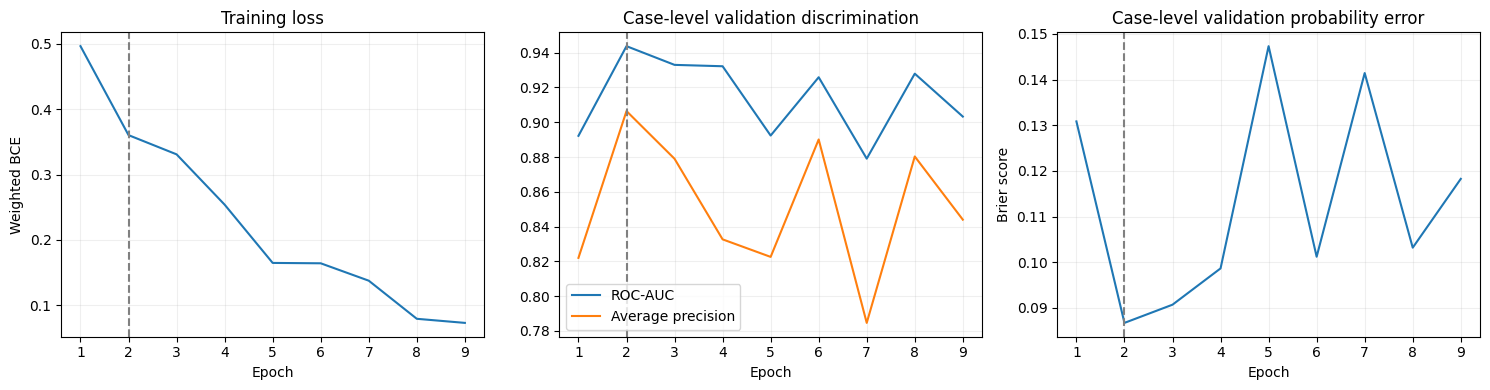

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 2,
  "outer_fold": 4,
  "case_roc_auc": 0.9437154150197629,
  "case_average_precision": 0.9064108823327529,
  "case_balanced_accuracy_at_0.5": 0.8648221343873518,
  "case_brier_score": 0.08672137910524846,
  "cases": 170
}

Validation predictions and learning curves saved.
Outer test partition remains unevaluated.


In [ ]:
# CELL 38B — verify automatic-crop fold 2 checkpoint
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

assert ACTIVE_FOLD == 4
selected = torch.load(
    RUN_DIR / "best.pt", map_location="cpu", weights_only=False
)
assert selected["config"] == classifier_config

full_image_model.load_state_dict(selected["model_state"], strict=True)
full_image_model.to(DEVICE)

metrics, image_predictions, case_predictions = evaluate_classifier(
    full_image_model, classifier_loaders["validation"]
)
assert np.isclose(
    metrics["case_roc_auc"], selected["best_auc"],
    atol=1e-8, rtol=0,
), "Validation ROC-AUC does not match the selected checkpoint."

report = {
    "selected_epoch": int(selected["epoch"]),
    "outer_fold": ACTIVE_FOLD,
    **metrics,
}
image_predictions.to_csv(
    RUN_DIR / "validation_image_predictions.csv", index=False
)
case_predictions.to_csv(
    RUN_DIR / "validation_case_predictions.csv", index=False
)
with (RUN_DIR / "selected_validation_metrics.json").open("w") as f:
    json.dump(report, f, indent=2)

history = pd.read_csv(RUN_DIR / "training_history.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["epoch"], history["train_weighted_loss"])
axes[0].set(title="Training loss", ylabel="Weighted BCE")

axes[1].plot(
    history["epoch"], history["case_roc_auc"], label="ROC-AUC"
)
axes[1].plot(
    history["epoch"], history["case_average_precision"],
    label="Average precision"
)
axes[1].set(title="Case-level validation discrimination")
axes[1].legend()

axes[2].plot(history["epoch"], history["case_brier_score"])
axes[2].set(
    title="Case-level validation probability error",
    ylabel="Brier score"
)

for ax in axes:
    ax.axvline(
        report["selected_epoch"], color="gray", linestyle="--"
    )
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(RUN_DIR / "learning_curves.png", dpi=200)
plt.show()
plt.close(fig)

print("SELECTED CHECKPOINT — VERIFIED")
print(json.dumps(report, indent=2))
print("\nValidation predictions and learning curves saved.")
print("Outer test partition remains unevaluated.")

In [ ]:
# CELL 39 — save outer fold 3 validation/test predicted masks
import hashlib
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.nn import functional as F
from tqdm.auto import tqdm

MASK_FOLD = 5
DEVICE = torch.device("cuda")
assert torch.cuda.is_available()

fold_table = pd.read_csv(
    PROJECT_ROOT / "splits" / f"outer_fold_{MASK_FOLD}.csv",
    dtype={"ID": str, "Case": str},
)
prediction_table = fold_table.loc[
    fold_table["Split"].isin(["validation", "test"])
].copy()

checkpoint_path = (
    PROJECT_ROOT / "models" / "segmentation_resnet18_unet"
    / f"fold_{MASK_FOLD}" / "best.pt"
)
saved = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
assert saved["config"]["outer_fold"] == MASK_FOLD
assert saved["config"]["prediction_threshold"] == 0.5

mask_model = ResNet18UNet().to(DEVICE)
mask_model.load_state_dict(saved["model_state"], strict=True)
mask_model.eval()

output_dir = (
    PROJECT_ROOT / "predicted_masks" / f"outer_fold_{MASK_FOLD}"
)
for split in ("validation", "test"):
    (output_dir / split).mkdir(parents=True, exist_ok=True)

records = []
with torch.inference_mode():
    for row in tqdm(
        prediction_table.to_dict("records"),
        desc="Saving original-size masks",
    ):
        # No expert mask is read.
        with Image.open(
            DATA_ROOT / row["Image_relative_path"]
        ) as f:
            image = f.convert("L")

        width, height = image.size
        blank = Image.new("L", image.size, 0)
        image_array, _, geometry = resize_pair(
            image, blank, saved["config"]["image_size"]
        )
        tensor = torch.from_numpy(
            image_array.copy()
        )[None, None].to(DEVICE)

        probabilities = mask_model(tensor).sigmoid()
        left = geometry["left_padding"]
        top = geometry["top_padding"]
        new_width = geometry["resized_width"]
        new_height = geometry["resized_height"]
        probabilities = probabilities[
            :, :, top:top + new_height, left:left + new_width
        ]
        probabilities = F.interpolate(
            probabilities, size=(height, width),
            mode="bilinear", align_corners=False,
        )
        binary = (
            probabilities[0, 0] >= 0.5
        ).cpu().numpy().astype(np.uint8) * 255

        destination = output_dir / row["Split"] / f"{row['ID']}.png"
        temporary = destination.with_suffix(".tmp.png")
        Image.fromarray(binary).save(temporary)
        temporary.replace(destination)

        records.append({
            "ID": row["ID"],
            "Case": row["Case"],
            "Split": row["Split"],
            "Outer_fold": MASK_FOLD,
            "Mask_path": str(destination),
            "Width": width,
            "Height": height,
            "Empty_prediction": int(not binary.any()),
        })

mask_manifest = pd.DataFrame(records)
assert mask_manifest["ID"].is_unique
assert set(mask_manifest["ID"]) == set(prediction_table["ID"])
mask_manifest.to_csv(output_dir / "mask_manifest.csv", index=False)

digest = hashlib.sha256()
with checkpoint_path.open("rb") as f:
    for block in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(block)

with (output_dir / "mask_provenance.json").open("w") as f:
    json.dump({
        "outer_fold": MASK_FOLD,
        "checkpoint": str(checkpoint_path),
        "checkpoint_sha256": digest.hexdigest(),
        "selected_epoch": int(saved["epoch"]),
        "threshold": 0.5,
        "postprocessing": "None",
        "mask_space": "Original image dimensions",
        "expert_masks_read_during_prediction": False,
    }, f, indent=2)

print("\nPREDICTED MASKS SAVED")
display(mask_manifest.groupby("Split").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
    Empty_masks=("Empty_prediction", "sum"),
))
print("Output:", output_dir)
print("No training performed.")

del mask_model, saved
torch.cuda.empty_cache()

Saving original-size masks:   0%|          | 0/683 [00:00<?, ?it/s]


PREDICTED MASKS SAVED


,Images,Cases,Empty_masks
Split,,,
test,383,212,1
validation,300,171,1


Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_5
No training performed.


In [ ]:
# CELL 40 — inner cross-fitting assignments for outer fold 4
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

CROSSFIT_OUTER_FOLD = 5
INNER_FOLDS = 3
SEED = 2026

outer_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_5.csv",
    dtype={"ID": str, "Case": str},
)
outer_train = outer_table.loc[
    outer_table["Split"].eq("train")
].copy()

assert outer_train.groupby("Case")["Label"].nunique().eq(1).all()
case_table = (
    outer_train.groupby("Case", as_index=False)
    .agg(Label=("Label", "first"))
    .sort_values("Case")
    .reset_index(drop=True)
)
excluded_cases = set(
    outer_table.loc[~outer_table["Split"].eq("train"), "Case"]
)
assert set(case_table["Case"]).isdisjoint(excluded_cases)

assignment_dir = (
    PROJECT_ROOT / "splits" / "segmentation_crossfit_outer_5"
)
assignment_dir.mkdir(parents=True, exist_ok=True)

splitter = StratifiedKFold(
    n_splits=INNER_FOLDS, shuffle=True, random_state=SEED
)
assignment_frames = []
summary_rows = []

for inner_fold, (development_indices, prediction_indices) in enumerate(
    splitter.split(case_table["Case"], case_table["Label"]), start=1
):
    development = case_table.iloc[development_indices]
    prediction = case_table.iloc[prediction_indices]

    fit_cases, selection_cases = train_test_split(
        development["Case"].to_numpy(),
        test_size=0.20,
        stratify=development["Label"].to_numpy(),
        random_state=SEED + inner_fold,
    )
    fit_cases = set(fit_cases)
    selection_cases = set(selection_cases)
    prediction_cases = set(prediction["Case"])

    assert fit_cases.isdisjoint(selection_cases)
    assert fit_cases.isdisjoint(prediction_cases)
    assert selection_cases.isdisjoint(prediction_cases)
    assert (
        fit_cases | selection_cases | prediction_cases
    ) == set(case_table["Case"])

    assignments = outer_train.copy()
    assignments["Inner_fold"] = inner_fold
    assignments["Segmentation_role"] = assignments["Case"].map({
        **{case: "fit" for case in fit_cases},
        **{case: "selection" for case in selection_cases},
        **{case: "predict" for case in prediction_cases},
    })
    assert assignments["Segmentation_role"].notna().all()

    destination = assignment_dir / f"inner_fold_{inner_fold}.csv"
    if destination.exists():
        existing = pd.read_csv(
            destination, dtype={"ID": str, "Case": str}
        )
        check_columns = ["ID", "Case", "Segmentation_role"]
        pd.testing.assert_frame_equal(
            existing[check_columns].sort_values("ID").reset_index(drop=True),
            assignments[check_columns].sort_values("ID").reset_index(drop=True),
        )
    else:
        assignments.to_csv(destination, index=False)

    assignment_frames.append(assignments)
    for role in ("fit", "selection", "predict"):
        subset = assignments.loc[
            assignments["Segmentation_role"].eq(role)
        ]
        cases = subset.drop_duplicates("Case")
        summary_rows.append({
            "Inner_fold": inner_fold,
            "Role": role,
            "Cases": len(cases),
            "Images": len(subset),
            "Malignant_cases": int(cases["Label"].sum()),
        })

crossfit_assignments = pd.concat(assignment_frames, ignore_index=True)
prediction_rows = crossfit_assignments.loc[
    crossfit_assignments["Segmentation_role"].eq("predict")
]
assert prediction_rows["ID"].is_unique
assert set(prediction_rows["ID"]) == set(outer_train["ID"])
assert prediction_rows.groupby("Case")["Inner_fold"].nunique().eq(1).all()

crossfit_assignments.to_csv(
    assignment_dir / "crossfit_assignments.csv", index=False
)
summary = pd.DataFrame(summary_rows)
summary.to_csv(assignment_dir / "summary.csv", index=False)
display(summary)

print("Every outer-training image has exactly one inner prediction fold.")
print("Outer validation and test cases are excluded from all inner folds.")
print("Assignments saved:", assignment_dir)
print("No training performed.")

,Inner_fold,Role,Cases,Images,Malignant_cases
0,1,fit,363,637,117
1,1,selection,91,152,29
2,1,predict,227,403,73
3,2,fit,363,632,117
4,2,selection,91,166,29
5,2,predict,227,394,73
6,3,fit,363,636,117
7,3,selection,91,161,29
8,3,predict,227,395,73


Every outer-training image has exactly one inner prediction fold.
Outer validation and test cases are excluded from all inner folds.
Assignments saved: /content/drive/MyDrive/BUSBRA_Research/splits/segmentation_crossfit_outer_5
No training performed.


In [ ]:
# CELL 41 — prepare outer fold 3, inner fold 1 segmenter
import json
import random
import numpy as np
import pandas as pd
import torch
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

CROSSFIT_OUTER_FOLD = 5
INNER_FOLD = 3
DEVICE = torch.device("cuda")
assert torch.cuda.is_available()

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / f"outer_fold_{CROSSFIT_OUTER_FOLD}"
    / f"inner_fold_{INNER_FOLD}"
)
SEGMENTATION_RUN_DIR.mkdir(parents=True, exist_ok=True)
SEG_BEST_PATH = SEGMENTATION_RUN_DIR / "best.pt"
SEG_LAST_PATH = SEGMENTATION_RUN_DIR / "last.pt"

with (
    PROJECT_ROOT / "models" / "segmentation_resnet18_unet"
    / f"fold_{CROSSFIT_OUTER_FOLD}" / "training_config.json"
).open() as f:
    segmentation_config = json.load(f)

segmentation_config.update({
    "outer_fold": CROSSFIT_OUTER_FOLD,
    "inner_fold": INNER_FOLD,
    "partition_source": "Saved inner case-separated cross-fitting partitions",
})
config_path = SEGMENTATION_RUN_DIR / "training_config.json"
if config_path.exists():
    with config_path.open() as f:
        assert json.load(f) == segmentation_config, "Configuration mismatch."

SEED = segmentation_config["seed"]
IMAGE_SIZE = segmentation_config["image_size"]

assignments = pd.read_csv(
    PROJECT_ROOT / "splits"
    / f"segmentation_crossfit_outer_{CROSSFIT_OUTER_FOLD}"
    / f"inner_fold_{INNER_FOLD}.csv",
    dtype={"ID": str, "Case": str},
)
role_mapping = {
    "train": "fit", "validation": "selection", "predict": "predict"
}
segmentation_datasets = {
    split: BUSBRADataset(
        assignments.loc[assignments["Segmentation_role"].eq(role)],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split, role in role_mapping.items()
}

case_sets = [
    set(dataset.table["Case"])
    for dataset in segmentation_datasets.values()
]
assert all(
    case_sets[i].isdisjoint(case_sets[j])
    for i in range(3) for j in range(i + 1, 3)
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

segmentation_generator = torch.Generator().manual_seed(SEED)
segmentation_loaders = {
    split: DataLoader(
        dataset,
        batch_size=segmentation_config["batch_size"],
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=True,
        generator=segmentation_generator if split == "train" else None,
    )
    for split, dataset in segmentation_datasets.items()
}

training_table = segmentation_datasets["train"].table
case_counts = training_table.groupby("Case")["ID"].transform("size")
weights = 1.0 / case_counts
weights = weights / weights.mean()
segmentation_id_weights = dict(zip(training_table["ID"], weights))

segmentation_model = ResNet18UNet()

# The recovery class builds without pretrained weights.
# Restore ImageNet initialization for this NEW inner model.
pretrained_encoder = resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)
segmentation_model.stem[0].load_state_dict(
    pretrained_encoder.conv1.state_dict()
)
segmentation_model.stem[1].load_state_dict(
    pretrained_encoder.bn1.state_dict()
)
for model_layer, encoder_layer in (
    (segmentation_model.encoder1, pretrained_encoder.layer1),
    (segmentation_model.encoder2, pretrained_encoder.layer2),
    (segmentation_model.encoder3, pretrained_encoder.layer3),
    (segmentation_model.encoder4, pretrained_encoder.layer4),
):
    model_layer.load_state_dict(encoder_layer.state_dict())
del pretrained_encoder

segmentation_model.to(DEVICE)
segmentation_optimizer = torch.optim.AdamW(
    segmentation_model.parameters(),
    lr=segmentation_config["learning_rate"],
    weight_decay=segmentation_config["weight_decay"],
)

with config_path.open("w") as f:
    json.dump(segmentation_config, f, indent=2)

print(
    f"Outer fold {CROSSFIT_OUTER_FOLD} — inner fold {INNER_FOLD}"
)
for split, dataset in segmentation_datasets.items():
    print(
        f"{split:12s}: {len(dataset):,} images | "
        f"{dataset.table['Case'].nunique()} cases"
    )
print("ImageNet encoder weights loaded.")
print("Continuation checkpoint exists:", SEG_LAST_PATH.exists())
print("Checkpoint folder:", SEGMENTATION_RUN_DIR)
print("No training performed.")

Outer fold 5 — inner fold 3
train       : 636 images | 363 cases
validation  : 161 images | 91 cases
predict     : 395 images | 227 cases
ImageNet encoder weights loaded.
Continuation checkpoint exists: False
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/segmentation_crossfit/outer_fold_5/inner_fold_3
No training performed.


In [ ]:
# CELL 42 — train the active inner segmentation model
import random
import time
import numpy as np
import pandas as pd
import torch

assert torch.cuda.is_available()
DEVICE = torch.device("cuda")
assert segmentation_config["outer_fold"] == CROSSFIT_OUTER_FOLD
assert segmentation_config["inner_fold"] == INNER_FOLD

segmentation_model.to(DEVICE)
start_epoch = 1
best_dice = -float("inf")
stale_epochs = 0
segmentation_history = []

if SEG_LAST_PATH.exists():
    saved = torch.load(
        SEG_LAST_PATH, map_location="cpu", weights_only=False
    )
    assert saved["config"] == segmentation_config
    segmentation_model.load_state_dict(saved["model_state"], strict=True)
    segmentation_optimizer.load_state_dict(saved["optimizer_state"])

    for state in segmentation_optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value) and key != "step":
                state[key] = value.to(DEVICE)

    start_epoch = int(saved["epoch"]) + 1
    best_dice = float(saved["best_dice"])
    stale_epochs = int(saved["stale_epochs"])
    segmentation_history = list(saved["history"])

    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"].cpu())
    segmentation_generator.set_state(saved["loader_rng"].cpu())
    if saved["cuda_rng"] is not None:
        torch.cuda.set_rng_state_all([
            state.cpu() for state in saved["cuda_rng"]
        ])
    del saved
    print(f"Resuming at epoch {start_epoch}.")
else:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    segmentation_generator.manual_seed(SEED)
    print("Starting segmentation training.")

print(f"Outer fold {CROSSFIT_OUTER_FOLD} | Inner fold {INNER_FOLD}")
patience = segmentation_config["early_stopping_patience"]
max_epochs = segmentation_config["max_epochs"]

if stale_epochs >= patience:
    print("Early stopping was already reached; no further training.")
else:
    for epoch in range(start_epoch, max_epochs + 1):
        started = time.perf_counter()
        segmentation_model.train()
        accumulated_loss = 0.0
        image_count = 0

        for batch in segmentation_loaders["train"]:
            images = batch["image"].to(DEVICE, non_blocking=True)
            masks = batch["mask"].to(DEVICE, non_blocking=True)

            segmentation_optimizer.zero_grad(set_to_none=True)
            logits = segmentation_model(images)
            loss = segmentation_loss(logits, masks, batch["id"])
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                segmentation_model.parameters(),
                segmentation_config["gradient_clip_norm"],
                error_if_nonfinite=True,
            )
            segmentation_optimizer.step()

            accumulated_loss += loss.item() * images.size(0)
            image_count += images.size(0)

        metrics, _, _ = evaluate_segmentation(
            segmentation_model, segmentation_loaders["validation"]
        )
        improved = metrics["case_dice"] > best_dice
        if improved:
            best_dice = metrics["case_dice"]
            stale_epochs = 0
        else:
            stale_epochs += 1

        elapsed = time.perf_counter() - started
        segmentation_history.append({
            "epoch": epoch,
            "train_weighted_loss": accumulated_loss / image_count,
            **metrics,
            "seconds": elapsed,
        })

        payload = {
            "epoch": epoch,
            "config": segmentation_config,
            "model_state": segmentation_model.state_dict(),
            "optimizer_state": segmentation_optimizer.state_dict(),
            "best_dice": best_dice,
            "stale_epochs": stale_epochs,
            "history": segmentation_history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": segmentation_generator.get_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }
        if improved:
            save_segmentation_checkpoint(payload, SEG_BEST_PATH)
        save_segmentation_checkpoint(payload, SEG_LAST_PATH)
        pd.DataFrame(segmentation_history).to_csv(
            SEGMENTATION_RUN_DIR / "training_history.csv", index=False
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Loss {accumulated_loss / image_count:.4f} | "
            f"Val Dice {metrics['case_dice']:.4f} | "
            f"Val IoU {metrics['case_iou']:.4f} | "
            f"Empty {metrics['empty_prediction_images']} | "
            f"{elapsed:.1f}s"
            + (" | BEST" if improved else ""),
            flush=True,
        )

        if stale_epochs >= patience:
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level Dice: {best_dice:.4f}")
print("Best checkpoint:", SEG_BEST_PATH)
print("Inner prediction partition remains unused by this cell.")

In [ ]:
# CELL 53 — recover progress after runtime disconnection
from google.colab import drive
from pathlib import Path
import torch

drive.mount("/content/drive")

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

run_dir = Path(
    "/content/drive/MyDrive/BUSBRA_Research/models/"
    "segmentation_crossfit/outer_fold_5/inner_fold_3"
)

for filename in ("best.pt", "last.pt"):
    path = run_dir / filename
    print(f"\n{filename}: {'FOUND' if path.is_file() else 'NOT FOUND'}")
    if path.is_file():
        saved = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print("Saved epoch:", saved["epoch"])
        print("Best validation Dice:", saved["best_dice"])
        if filename == "last.pt":
            print("Next epoch:", saved["epoch"] + 1)
            print("Early-stopping counter:", saved["stale_epochs"])
        del saved

for folder in ("Images", "Masks"):
    root = Path("/content/BUSBRA") / folder
    print(f"\nCached {folder}: {len(list(root.glob('*.png'))):,}")

print("\nNo training performed. No files changed.")

Mounted at /content/drive
GPU available: True
GPU: Tesla T4

best.pt: FOUND
Saved epoch: 11
Best validation Dice: 0.8913044652768544

last.pt: FOUND
Saved epoch: 19
Best validation Dice: 0.8913044652768544
Next epoch: 20
Early-stopping counter: 8

Cached Images: 0

Cached Masks: 0

No training performed. No files changed.


In [ ]:
# CELL 54 — check definitions needed for final checkpoint verification
from pathlib import Path
import torch

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")
LOCAL_DATA_ROOT = Path("/content/BUSBRA")
DEVICE = torch.device("cuda")
CROSSFIT_OUTER_FOLD = 5
INNER_FOLD = 3

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / "outer_fold_5" / "inner_fold_3"
)
SEG_BEST_PATH = SEGMENTATION_RUN_DIR / "best.pt"
SEG_LAST_PATH = SEGMENTATION_RUN_DIR / "last.pt"

for name in (
    "resize_pair",
    "ResNet18UNet",
    "BUSBRADataset",
    "evaluate_segmentation",
):
    print(f"{name}: {'present' if name in globals() else 'missing'}")

print(
    "Saved validation report:",
    (SEGMENTATION_RUN_DIR / "selected_validation_metrics.json").is_file()
)
print("\nNo training performed. No files changed.")

resize_pair: missing
ResNet18UNet: missing
BUSBRADataset: missing
evaluate_segmentation: missing
Saved validation report: False

No training performed. No files changed.


In [ ]:
# CELL 55 — Restore definitions and verify fold 5 / inner fold 3
# No training. Existing checkpoints remain unchanged.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
DATA_ROOT = Path("/content/drive/MyDrive/BUSBRA")
CROSSFIT_OUTER_FOLD = 5
INNER_FOLD = 3
IMAGE_SIZE = 256
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / "outer_fold_5" / "inner_fold_3"
)
SEG_BEST_PATH = SEGMENTATION_RUN_DIR / "best.pt"


def resize_pair(image, mask, size=256):
    assert image.size == mask.size
    width, height = image.size
    scale = size / max(width, height)
    resized_width = max(1, min(size, round(width * scale)))
    resized_height = max(1, min(size, round(height * scale)))
    left = (size - resized_width) // 2
    top = (size - resized_height) // 2

    image_canvas = Image.new("L", (size, size), 0)
    mask_canvas = Image.new("L", (size, size), 0)
    image_canvas.paste(
        image.resize(
            (resized_width, resized_height), Image.Resampling.BILINEAR
        ), (left, top)
    )
    mask_canvas.paste(
        mask.resize(
            (resized_width, resized_height), Image.Resampling.NEAREST
        ), (left, top)
    )

    geometry = {
        "original_width": width,
        "original_height": height,
        "resized_width": resized_width,
        "resized_height": resized_height,
        "left_padding": left,
        "top_padding": top,
    }
    return (
        np.asarray(image_canvas, dtype=np.float32) / 255.0,
        (np.asarray(mask_canvas) > 0).astype(np.float32),
        geometry,
    )


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv2d(
                in_channels + skip_channels, out_channels,
                3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels, out_channels, 3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, features, skip):
        features = F.interpolate(
            features, size=skip.shape[-2:],
            mode="bilinear", align_corners=False
        )
        return self.convolutions(torch.cat([features, skip], dim=1))


class ResNet18UNet(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = resnet18(weights=None)
        self.stem = nn.Sequential(
            encoder.conv1, encoder.bn1, encoder.relu
        )
        self.pool = encoder.maxpool
        self.encoder1 = encoder.layer1
        self.encoder2 = encoder.layer2
        self.encoder3 = encoder.layer3
        self.encoder4 = encoder.layer4
        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)
        self.decoder0 = DecoderBlock(64, 64, 32)
        self.output_head = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, 1),
        )
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )

    def forward(self, image):
        original_size = image.shape[-2:]
        image = (
            image.repeat(1, 3, 1, 1) - self.image_mean
        ) / self.image_std
        stem = self.stem(image)
        e1 = self.encoder1(self.pool(stem))
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        e4 = self.encoder4(e3)
        decoded = self.decoder3(e4, e3)
        decoded = self.decoder2(decoded, e2)
        decoded = self.decoder1(decoded, e1)
        decoded = self.decoder0(decoded, stem)
        decoded = F.interpolate(
            decoded, size=original_size,
            mode="bilinear", align_corners=False
        )
        return self.output_head(decoded)


class BUSBRADataset(Dataset):
    def __init__(self, table, root, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.root = Path(root)
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(self.root / row["Image_relative_path"]) as source:
            image = source.convert("L")
        with Image.open(self.root / row["Mask_relative_path"]) as source:
            mask = source.convert("L")

        image, mask, _ = resize_pair(image, mask, IMAGE_SIZE)
        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            mask = np.flip(mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(mask.copy()).unsqueeze(0),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }


@torch.inference_mode()
def evaluate_segmentation(model, loader):
    model.eval()
    records = []
    device = next(model.parameters()).device

    for batch in loader:
        predicted = (
            torch.sigmoid(model(batch["image"].to(device))) >= 0.5
        ).flatten(1)
        target = (batch["mask"].to(device) > 0.5).flatten(1)
        intersection = (predicted & target).sum(1).float()
        predicted_area = predicted.sum(1).float()
        target_area = target.sum(1).float()
        dice = (
            (2 * intersection + 1e-6)
            / (predicted_area + target_area + 1e-6)
        )
        iou = (
            (intersection + 1e-6)
            / (predicted_area + target_area - intersection + 1e-6)
        )

        for index in range(len(batch["id"])):
            records.append({
                "ID": batch["id"][index],
                "Case": batch["case"][index],
                "Dice": dice[index].item(),
                "IoU": iou[index].item(),
                "Empty_prediction": int(predicted_area[index].item() == 0),
            })

    image_scores = pd.DataFrame(records)
    case_scores = image_scores.groupby("Case", as_index=False).agg(
        Dice=("Dice", "mean"),
        IoU=("IoU", "mean"),
        Images=("ID", "size"),
    )
    metrics = {
        "case_dice": float(case_scores["Dice"].mean()),
        "case_iou": float(case_scores["IoU"].mean()),
        "empty_prediction_images": int(
            image_scores["Empty_prediction"].sum()
        ),
        "cases": int(len(case_scores)),
    }
    return metrics, image_scores, case_scores


# Read existing assignments; do not recreate partitions.
assignment_path = (
    PROJECT_ROOT / "splits" / "segmentation_crossfit_outer_5"
    / "inner_fold_3.csv"
)
assignments = pd.read_csv(assignment_path)
selection = assignments.loc[
    assignments["Segmentation_role"].eq("selection")
].copy()

assert len(selection) == 161, f"Unexpected image count: {len(selection)}"
assert selection["Case"].nunique() == 91

checkpoint = torch.load(
    SEG_BEST_PATH, map_location="cpu", weights_only=False
)
assert checkpoint["config"]["outer_fold"] == 5
assert checkpoint["config"]["inner_fold"] == 3

segmentation_model = ResNet18UNet()
segmentation_model.load_state_dict(checkpoint["model_state"], strict=True)
segmentation_model = segmentation_model.to(DEVICE)

selection_loader = DataLoader(
    BUSBRADataset(selection, DATA_ROOT, augment=False),
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print(f"Verifying {len(selection)} validation images on {DEVICE}...")
metrics, image_scores, case_scores = evaluate_segmentation(
    segmentation_model, selection_loader
)

assert np.isclose(
    metrics["case_dice"], checkpoint["best_dice"], atol=1e-6, rtol=0
), (
    f"Validation mismatch: computed {metrics['case_dice']:.10f}, "
    f"saved {checkpoint['best_dice']:.10f}"
)

report = {
    "selected_epoch": int(checkpoint["epoch"]),
    "outer_fold": 5,
    "inner_fold": 3,
    **metrics,
}

image_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_image_scores.csv", index=False
)
case_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_case_scores.csv", index=False
)
(SEGMENTATION_RUN_DIR / "selected_validation_metrics.json").write_text(
    json.dumps(report, indent=2)
)

print("\nSELECTED CHECKPOINT — VERIFIED")
print(json.dumps(report, indent=2))
print("\nValidation scores saved. No training performed.")
print("Checkpoint files unchanged.")
print("Inner prediction partition remains unused by this cell.")

Verifying 161 validation images on cuda...

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 11,
  "outer_fold": 5,
  "inner_fold": 3,
  "case_dice": 0.8913044652768544,
  "case_iou": 0.813455465894479,
  "empty_prediction_images": 0,
  "cases": 91
}

Validation scores saved. No training performed.
Checkpoint files unchanged.
Inner prediction partition remains unused by this cell.


In [ ]:
# CELL 56 — Generate outer fold 5 cross-fitted training masks
# No training. Expert masks are not accessed.

import hashlib
from tqdm.auto import tqdm

OUTER_FOLD = 5
MASK_ROOT = PROJECT_ROOT / "predicted_masks" / "outer_fold_5"
TRAIN_MASK_DIR = MASK_ROOT / "train"
TRAIN_MASK_DIR.mkdir(parents=True, exist_ok=True)

outer_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_5.csv"
)
outer_train = outer_table.loc[outer_table["Split"].eq("train")].copy()
excluded_cases = set(
    outer_table.loc[
        outer_table["Split"].isin(["validation", "test"]), "Case"
    ].astype(str)
)

assert len(outer_train) == 1192
assert outer_train["Case"].nunique() == 681
assert outer_train["ID"].is_unique

records = []
provenance = []


@torch.inference_mode()
def predict_original_size_mask(model, image):
    width, height = image.size
    blank = Image.new("L", image.size, 0)
    image_array, _, geometry = resize_pair(image, blank, 256)
    tensor = torch.from_numpy(image_array.copy())[None, None].to(DEVICE)

    probability = torch.sigmoid(model(tensor))
    left = geometry["left_padding"]
    top = geometry["top_padding"]
    rw = geometry["resized_width"]
    rh = geometry["resized_height"]

    probability = probability[:, :, top:top + rh, left:left + rw]
    probability = F.interpolate(
        probability,
        size=(height, width),
        mode="bilinear",
        align_corners=False,
    )
    return (
        probability[0, 0].cpu().numpy() >= 0.5
    ).astype(np.uint8) * 255


for inner_fold in (1, 2, 3):
    assignment = pd.read_csv(
        PROJECT_ROOT / "splits" / "segmentation_crossfit_outer_5"
        / f"inner_fold_{inner_fold}.csv"
    )
    prediction_table = assignment.loc[
        assignment["Segmentation_role"].eq("predict")
    ].copy()

    prediction_cases = set(prediction_table["Case"].astype(str))
    development_cases = set(
        assignment.loc[
            assignment["Segmentation_role"].isin(["fit", "selection"]),
            "Case",
        ].astype(str)
    )
    assert prediction_cases.isdisjoint(development_cases)
    assert set(assignment["Case"].astype(str)).isdisjoint(excluded_cases)
    assert prediction_table["ID"].is_unique

    checkpoint_path = (
        PROJECT_ROOT / "models" / "segmentation_crossfit"
        / "outer_fold_5" / f"inner_fold_{inner_fold}" / "best.pt"
    )
    saved = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    assert saved["config"]["outer_fold"] == OUTER_FOLD
    assert saved["config"]["inner_fold"] == inner_fold

    model = ResNet18UNet()
    model.load_state_dict(saved["model_state"], strict=True)
    model = model.to(DEVICE).eval()

    for _, row in tqdm(
        prediction_table.iterrows(),
        total=len(prediction_table),
        desc=f"Inner fold {inner_fold}",
    ):
        with Image.open(
            DATA_ROOT / row["Image_relative_path"]
        ) as source:
            image = source.convert("L")

        mask = predict_original_size_mask(model, image)
        destination = TRAIN_MASK_DIR / f"{row['ID']}.png"
        temporary = destination.with_suffix(".tmp.png")
        Image.fromarray(mask).save(temporary)
        temporary.replace(destination)

        records.append({
            "ID": str(row["ID"]),
            "Case": str(row["Case"]),
            "Split": "train",
            "Outer_fold": OUTER_FOLD,
            "Inner_fold": inner_fold,
            "Mask_path": str(destination),
            "Width": image.width,
            "Height": image.height,
            "Empty_prediction": int(not mask.any()),
        })

    digest = hashlib.sha256()
    with checkpoint_path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)

    provenance.append({
        "inner_fold": inner_fold,
        "checkpoint": str(checkpoint_path),
        "checkpoint_sha256": digest.hexdigest(),
        "selected_epoch": int(saved["epoch"]),
        "best_validation_dice": float(saved["best_dice"]),
        "prediction_images": int(len(prediction_table)),
        "prediction_cases": int(len(prediction_cases)),
    })

    del model, saved
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

train_mask_manifest = pd.DataFrame(records)
assert train_mask_manifest["ID"].is_unique
assert set(train_mask_manifest["ID"]) == set(outer_train["ID"].astype(str))
assert len(train_mask_manifest) == 1192
assert train_mask_manifest["Case"].nunique() == 681

train_mask_manifest.to_csv(
    MASK_ROOT / "train_mask_manifest.csv", index=False
)
(MASK_ROOT / "train_mask_provenance.json").write_text(
    json.dumps({
        "outer_fold": OUTER_FOLD,
        "prediction_threshold": 0.5,
        "postprocessing": "None",
        "expert_masks_accessed_during_prediction": False,
        "inner_models": provenance,
    }, indent=2)
)

summary = train_mask_manifest.groupby("Inner_fold").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
    Empty_masks=("Empty_prediction", "sum"),
)

print("\nCROSS-FITTED TRAINING MASKS SAVED")
display(summary)
print("Total images:", len(train_mask_manifest))
print("Total cases:", train_mask_manifest["Case"].nunique())
print("Output:", TRAIN_MASK_DIR)
print("No classifier training performed.")

Inner fold 1:   0%|          | 0/403 [00:00<?, ?it/s]

Inner fold 2:   0%|          | 0/394 [00:00<?, ?it/s]

Inner fold 3:   0%|          | 0/395 [00:00<?, ?it/s]


CROSS-FITTED TRAINING MASKS SAVED


,Images,Cases,Empty_masks
Inner_fold,,,
1,403,227,4
2,394,227,0
3,395,227,0


Total images: 1192
Total cases: 681
Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_5/train
No classifier training performed.


In [ ]:
# CELL 57 — Cache fold 5 automatic-crop classifier inputs
# Copies training/validation images and predicted masks only.

import shutil
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

ACTIVE_FOLD = 5
LOCAL_DATA_ROOT = Path("/content/BUSBRA")
LOCAL_MASK_ROOT = Path("/content/BUSBRA_predicted_masks/outer_fold_5")
MASK_ROOT = PROJECT_ROOT / "predicted_masks" / "outer_fold_5"

fold_table = pd.read_csv(
    PROJECT_ROOT / "splits" / "outer_fold_5.csv"
)
classifier_inputs = fold_table.loc[
    fold_table["Split"].isin(["train", "validation"])
].copy()

training_masks = pd.read_csv(MASK_ROOT / "train_mask_manifest.csv")
evaluation_masks = pd.read_csv(MASK_ROOT / "mask_manifest.csv")

mask_lookup = pd.concat([
    training_masks.loc[:, ["ID", "Case", "Split", "Mask_path"]],
    evaluation_masks.loc[
        evaluation_masks["Split"].eq("validation"),
        ["ID", "Case", "Split", "Mask_path"],
    ],
], ignore_index=True)

assert mask_lookup["ID"].is_unique
classifier_inputs = classifier_inputs.merge(
    mask_lookup.rename(columns={"Case": "Mask_case", "Split": "Mask_split"}),
    on="ID",
    how="left",
    validate="one_to_one",
)

assert classifier_inputs["Mask_path"].notna().all()
assert (
    classifier_inputs["Case"].astype(str)
    == classifier_inputs["Mask_case"].astype(str)
).all()
assert (
    classifier_inputs["Split"] == classifier_inputs["Mask_split"]
).all()
assert classifier_inputs["Split"].value_counts().to_dict() == {
    "train": 1192, "validation": 300
}

jobs = []
cached_images = []
cached_masks = []

for row in classifier_inputs.itertuples(index=False):
    image_destination = LOCAL_DATA_ROOT / row.Image_relative_path
    mask_destination = LOCAL_MASK_ROOT / row.Split / f"{row.ID}.png"

    jobs.append((DATA_ROOT / row.Image_relative_path, image_destination))
    jobs.append((Path(row.Mask_path), mask_destination))
    cached_images.append(str(image_destination))
    cached_masks.append(str(mask_destination))


def copy_classifier_input(job):
    source, destination = job
    try:
        if destination.exists() and destination.stat().st_size > 0:
            return "existing", None
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_name(destination.name + ".tmp")
        shutil.copyfile(source, temporary)
        temporary.replace(destination)
        return "copied", None
    except Exception as error:
        return "failed", f"{source}: {error}"


counts = {"copied": 0, "existing": 0, "failed": 0}
failures = []

with ThreadPoolExecutor(max_workers=4) as executor:
    for status, error in tqdm(
        executor.map(copy_classifier_input, jobs),
        total=len(jobs),
        desc="Caching fold 5 classifier inputs",
    ):
        counts[status] += 1
        if error:
            failures.append(error)

print("\nNewly copied:", counts["copied"])
print("Already present:", counts["existing"])
print("Failed:", counts["failed"])

if failures:
    print("\n".join(failures[:10]))
    raise RuntimeError("Cache incomplete; resolve failed copies before training.")

classifier_inputs["Cached_image_path"] = cached_images
classifier_inputs["Cached_mask_path"] = cached_masks

classifier_inputs.to_csv(
    LOCAL_MASK_ROOT / "classifier_cached_inputs.csv", index=False
)

display(
    classifier_inputs.groupby("Split").agg(
        Images=("ID", "size"),
        Cases=("Case", "nunique"),
    )
)
print("Classifier inputs cached. No training performed.")

Caching fold 5 classifier inputs:   0%|          | 0/2984 [00:00<?, ?it/s]


Newly copied: 2984
Already present: 0
Failed: 0


,Images,Cases
Split,,
train,1192,681
validation,300,171


Classifier inputs cached. No training performed.


In [ ]:
# CELL 58 — Prepare outer fold 5 automatic-crop classifier

import math
import random
from torchvision.models import ResNet18_Weights

ACTIVE_FOLD = 5
SEED = 2026
IMAGE_SIZE = 256

CLASSIFIER_RUN_DIR = (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18" / "fold_5"
)
CLASSIFIER_RUN_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the configuration used for the previous automatic-crop folds.
reference_config = (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18"
    / "fold_4" / "training_config.json"
)
classifier_config = json.loads(reference_config.read_text())
classifier_config["outer_fold"] = ACTIVE_FOLD

existing_config = CLASSIFIER_RUN_DIR / "training_config.json"
if existing_config.exists():
    assert json.loads(existing_config.read_text()) == classifier_config, (
        "Existing fold 5 configuration differs."
    )

assert classifier_config["crop_margin_per_side"] == 0.2
CROP_MARGIN = float(classifier_config["crop_margin_per_side"])

classifier_inputs = pd.read_csv(
    LOCAL_MASK_ROOT / "classifier_cached_inputs.csv"
)
assert classifier_inputs["ID"].is_unique

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


class AutomaticCropDataset(Dataset):
    def __init__(self, table, augment=False):
        self.table = table.reset_index(drop=True).copy()
        self.augment = augment

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(row["Cached_image_path"]) as source:
            image = source.convert("L")
        with Image.open(row["Cached_mask_path"]) as source:
            mask = np.asarray(source.convert("L")) > 0

        assert mask.shape == (image.height, image.width)

        ys, xs = np.where(mask)
        if len(xs):
            x0, x1 = int(xs.min()), int(xs.max()) + 1
            y0, y1 = int(ys.min()), int(ys.max()) + 1
            margin_x = math.ceil((x1 - x0) * CROP_MARGIN)
            margin_y = math.ceil((y1 - y0) * CROP_MARGIN)
            image = image.crop((
                max(0, x0 - margin_x),
                max(0, y0 - margin_y),
                min(image.width, x1 + margin_x),
                min(image.height, y1 + margin_y),
            ))

        # Empty predicted mask: retain the full image.
        blank = Image.new("L", image.size, 0)
        array, _, _ = resize_pair(image, blank, IMAGE_SIZE)

        if self.augment and torch.rand(()).item() < 0.5:
            array = np.flip(array, axis=1).copy()

        return {
            "image": torch.from_numpy(array.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
        }


class FullImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(
            weights=ResNet18_Weights.IMAGENET1K_V1
        )
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)
        self.register_buffer(
            "image_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            "image_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )

    def forward(self, image):
        image = (
            image.repeat(1, 3, 1, 1) - self.image_mean
        ) / self.image_std
        return self.backbone(image).squeeze(1)


classifier_tables = {
    split: classifier_inputs.loc[
        classifier_inputs["Split"].eq(split)
    ].copy()
    for split in ("train", "validation")
}

assert set(classifier_tables["train"]["Case"]).isdisjoint(
    set(classifier_tables["validation"]["Case"])
)
assert set(classifier_inputs["Label"].unique()).issubset({0, 1})

training_table = classifier_tables["train"]
case_sizes = training_table.groupby("Case")["ID"].transform("size")
image_weights = 1.0 / case_sizes.to_numpy(dtype=float)
image_weights /= image_weights.mean()
classifier_id_weights = dict(zip(
    training_table["ID"].astype(str), image_weights
))

classifier_generator = torch.Generator().manual_seed(SEED)
classifier_loaders = {
    split: DataLoader(
        AutomaticCropDataset(table, augment=(split == "train")),
        batch_size=int(classifier_config["batch_size"]),
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        generator=classifier_generator if split == "train" else None,
    )
    for split, table in classifier_tables.items()
}

classifier_model = FullImageClassifier().to(DEVICE)
classifier_optimizer = torch.optim.AdamW(
    classifier_model.parameters(),
    lr=float(classifier_config["learning_rate"]),
    weight_decay=float(classifier_config["weight_decay"]),
)

existing_config.write_text(json.dumps(classifier_config, indent=2))
classifier_inputs.to_csv(
    CLASSIFIER_RUN_DIR / "input_manifest.csv", index=False
)

print("AUTOMATIC-CROP CLASSIFIER READY")
print("Outer fold:", ACTIVE_FOLD)
print("Device:", DEVICE)
for split, table in classifier_tables.items():
    print(
        f"{split:12s}: {len(table):,} images | "
        f"{table['Case'].nunique():,} cases"
    )
print("Crop margin per side:", CROP_MARGIN)
print("Expert masks are not read by this classifier dataset.")
print(
    "Continuation checkpoint exists:",
    (CLASSIFIER_RUN_DIR / "last.pt").exists(),
)
print("Checkpoint folder:", CLASSIFIER_RUN_DIR)
print("No training performed.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 35.4MB/s]


AUTOMATIC-CROP CLASSIFIER READY
Outer fold: 5
Device: cuda
train       : 1,192 images | 681 cases
validation  : 300 images | 171 cases
Crop margin per side: 0.2
Expert masks are not read by this classifier dataset.
Continuation checkpoint exists: False
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_5
No training performed.


In [ ]:
# CELL 59 — Train automatic-crop classifier, outer fold 5
# Outer test partition is not accessed.

import time
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss,
)

assert ACTIVE_FOLD == 5
assert classifier_config["outer_fold"] == 5
assert DEVICE.type == "cuda"

BEST_PATH = CLASSIFIER_RUN_DIR / "best.pt"
LAST_PATH = CLASSIFIER_RUN_DIR / "last.pt"


@torch.inference_mode()
def evaluate_classifier(model, loader):
    model.eval()
    records = []

    for batch in loader:
        probabilities = torch.sigmoid(
            model(batch["image"].to(DEVICE))
        ).cpu().numpy()

        for i, probability in enumerate(probabilities):
            records.append({
                "ID": batch["id"][i],
                "Case": batch["case"][i],
                "Label": int(batch["label"][i].item()),
                "Probability": float(probability),
            })

    image_predictions = pd.DataFrame(records)
    assert image_predictions.groupby("Case")["Label"].nunique().eq(1).all()

    case_predictions = image_predictions.groupby(
        "Case", as_index=False
    ).agg(
        Label=("Label", "first"),
        Probability=("Probability", "mean"),
        Images=("ID", "size"),
    )

    labels = case_predictions["Label"].to_numpy()
    probabilities = case_predictions["Probability"].to_numpy()
    metrics = {
        "case_roc_auc": float(roc_auc_score(labels, probabilities)),
        "case_average_precision": float(
            average_precision_score(labels, probabilities)
        ),
        "case_balanced_accuracy_at_0.5": float(
            balanced_accuracy_score(labels, probabilities >= 0.5)
        ),
        "case_brier_score": float(brier_score_loss(labels, probabilities)),
        "cases": int(len(case_predictions)),
    }
    return metrics, image_predictions, case_predictions


def save_classifier_checkpoint(path, state):
    temporary = path.with_suffix(".pt.tmp")
    torch.save(state, temporary)
    temporary.replace(path)


start_epoch = 1
best_auc = -float("inf")
epochs_without_improvement = 0
history = []

if LAST_PATH.exists():
    saved = torch.load(LAST_PATH, map_location="cpu", weights_only=False)
    assert saved["config"] == classifier_config
    classifier_model.load_state_dict(saved["model_state"], strict=True)
    classifier_optimizer.load_state_dict(saved["optimizer_state"])

    for state in classifier_optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    start_epoch = int(saved["epoch"]) + 1
    best_auc = float(saved["best_auc"])
    epochs_without_improvement = int(saved["epochs_without_improvement"])
    history = saved["history"]

    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"])
    classifier_generator.set_state(saved["loader_rng"])
    if saved.get("cuda_rng") is not None:
        torch.cuda.set_rng_state_all(saved["cuda_rng"])

    del saved
    print(f"Resuming at epoch {start_epoch}.")
else:
    print("Starting training from the initialised model.")

max_epochs = int(classifier_config["max_epochs"])
patience = int(classifier_config["early_stopping_patience"])
clip_norm = float(classifier_config["gradient_clip_norm"])

if epochs_without_improvement >= patience:
    print("Saved run already reached early stopping; no further training.")

else:
    for epoch in range(start_epoch, max_epochs + 1):
        started = time.perf_counter()
        classifier_model.train()
        loss_sum = 0.0
        images_seen = 0

        for batch in classifier_loaders["train"]:
            images = batch["image"].to(DEVICE, non_blocking=True)
            labels = batch["label"].to(DEVICE, non_blocking=True)
            weights = torch.tensor(
                [classifier_id_weights[str(i)] for i in batch["id"]],
                dtype=torch.float32,
                device=DEVICE,
            )

            classifier_optimizer.zero_grad(set_to_none=True)
            logits = classifier_model(images)
            loss = (
                F.binary_cross_entropy_with_logits(
                    logits, labels, reduction="none"
                ) * weights
            ).mean()

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss.")

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                classifier_model.parameters(), clip_norm,
                error_if_nonfinite=True,
            )
            classifier_optimizer.step()

            loss_sum += loss.item() * len(images)
            images_seen += len(images)

        metrics, _, _ = evaluate_classifier(
            classifier_model, classifier_loaders["validation"]
        )
        improved = metrics["case_roc_auc"] > best_auc

        if improved:
            best_auc = metrics["case_roc_auc"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        elapsed = time.perf_counter() - started
        train_loss = loss_sum / images_seen
        history.append({
            "epoch": epoch,
            "train_weighted_loss": train_loss,
            **metrics,
            "seconds": elapsed,
        })

        checkpoint = {
            "epoch": epoch,
            "config": classifier_config,
            "model_state": classifier_model.state_dict(),
            "optimizer_state": classifier_optimizer.state_dict(),
            "best_auc": best_auc,
            "epochs_without_improvement": epochs_without_improvement,
            "history": history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": classifier_generator.get_state(),
            "cuda_rng": torch.cuda.get_rng_state_all(),
        }
        if improved:
            save_classifier_checkpoint(BEST_PATH, checkpoint)
        save_classifier_checkpoint(LAST_PATH, checkpoint)

        pd.DataFrame(history).to_csv(
            CLASSIFIER_RUN_DIR / "training_history.csv", index=False
        )

        print(
            f"Epoch {epoch:02d} | Loss {train_loss:.4f} | "
            f"Val AUC {metrics['case_roc_auc']:.4f} | "
            f"Val AP {metrics['case_average_precision']:.4f} | "
            f"Brier {metrics['case_brier_score']:.4f} | "
            f"{elapsed:.1f}s"
            + (" | BEST" if improved else "")
        )

        if epochs_without_improvement >= patience:
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level ROC-AUC: {best_auc:.4f}")
print("Best checkpoint:", BEST_PATH)
print("Outer test partition has not been evaluated.")

Starting training from the initialised model.
Epoch 01 | Loss 0.4804 | Val AUC 0.8842 | Val AP 0.7971 | Brier 0.1281 | 17.6s | BEST
Epoch 02 | Loss 0.3469 | Val AUC 0.8823 | Val AP 0.8071 | Brier 0.1264 | 12.7s
Epoch 03 | Loss 0.2585 | Val AUC 0.8362 | Val AP 0.7501 | Brier 0.1514 | 12.5s
Epoch 04 | Loss 0.2119 | Val AUC 0.8469 | Val AP 0.7445 | Brier 0.1698 | 13.6s
Epoch 05 | Loss 0.1577 | Val AUC 0.8726 | Val AP 0.7963 | Brier 0.1349 | 13.0s
Epoch 06 | Loss 0.1347 | Val AUC 0.8688 | Val AP 0.8014 | Brier 0.1293 | 15.4s
Epoch 07 | Loss 0.1025 | Val AUC 0.8940 | Val AP 0.8192 | Brier 0.1322 | 12.2s | BEST
Epoch 08 | Loss 0.0921 | Val AUC 0.8384 | Val AP 0.7447 | Brier 0.1528 | 13.7s
Epoch 09 | Loss 0.0835 | Val AUC 0.8592 | Val AP 0.8024 | Brier 0.1477 | 12.5s
Epoch 10 | Loss 0.0853 | Val AUC 0.8839 | Val AP 0.8121 | Brier 0.1305 | 13.9s
Epoch 11 | Loss 0.0556 | Val AUC 0.8936 | Val AP 0.8165 | Brier 0.1180 | 13.8s
Epoch 12 | Loss 0.0292 | Val AUC 0.8876 | Val AP 0.8253 | Brier 0.1372 

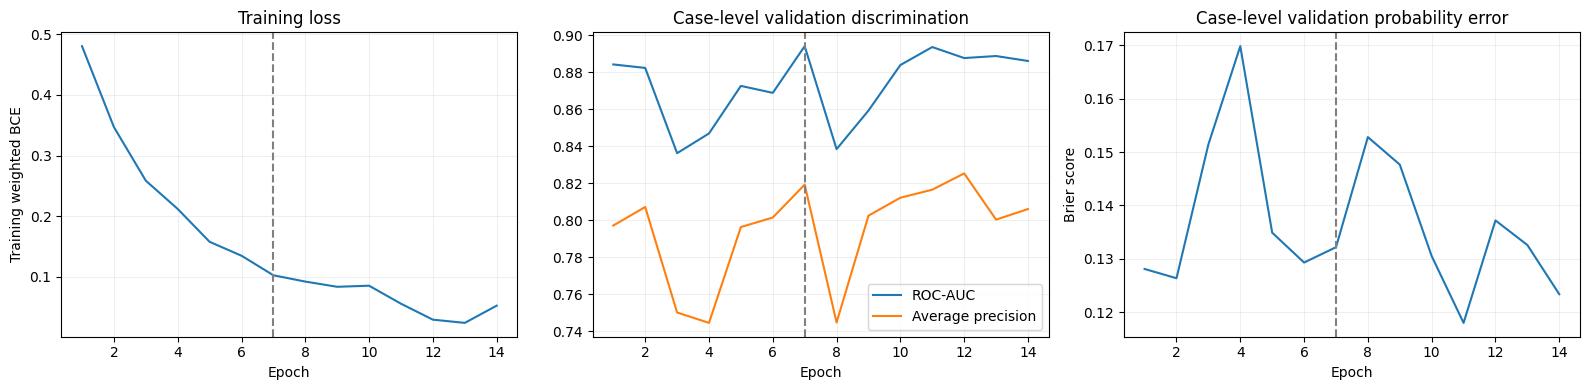

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 7,
  "outer_fold": 5,
  "case_roc_auc": 0.8940438871473354,
  "case_average_precision": 0.819218326231561,
  "case_balanced_accuracy_at_0.5": 0.835344827586207,
  "case_brier_score": 0.13218602160084583,
  "cases": 171
}

Validation predictions and learning curves saved.
No training performed. Checkpoint files unchanged.
Outer test partition remains unevaluated.


In [ ]:
# CELL 60 — Verify fold 5 classifier checkpoint
# No training. Outer test partition is not accessed.

import matplotlib.pyplot as plt

assert ACTIVE_FOLD == 5

selected = torch.load(
    CLASSIFIER_RUN_DIR / "best.pt",
    map_location="cpu",
    weights_only=False,
)
assert selected["config"] == classifier_config

classifier_model.load_state_dict(selected["model_state"], strict=True)
classifier_model.to(DEVICE)

metrics, image_predictions, case_predictions = evaluate_classifier(
    classifier_model, classifier_loaders["validation"]
)

assert np.isclose(
    metrics["case_roc_auc"],
    selected["best_auc"],
    atol=1e-10,
    rtol=0,
), "Selected checkpoint validation AUC does not match the saved value."

report = {
    "selected_epoch": int(selected["epoch"]),
    "outer_fold": ACTIVE_FOLD,
    **metrics,
}

image_predictions.to_csv(
    CLASSIFIER_RUN_DIR / "validation_image_predictions.csv", index=False
)
case_predictions.to_csv(
    CLASSIFIER_RUN_DIR / "validation_case_predictions.csv", index=False
)
(CLASSIFIER_RUN_DIR / "selected_validation_metrics.json").write_text(
    json.dumps(report, indent=2)
)

latest = torch.load(
    CLASSIFIER_RUN_DIR / "last.pt",
    map_location="cpu",
    weights_only=False,
)
curves = pd.DataFrame(latest["history"])
selected_epoch = report["selected_epoch"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(curves["epoch"], curves["train_weighted_loss"])
axes[0].set_title("Training loss")
axes[0].set_ylabel("Training weighted BCE")

axes[1].plot(
    curves["epoch"], curves["case_roc_auc"], label="ROC-AUC"
)
axes[1].plot(
    curves["epoch"], curves["case_average_precision"],
    label="Average precision",
)
axes[1].set_title("Case-level validation discrimination")
axes[1].legend()

axes[2].plot(curves["epoch"], curves["case_brier_score"])
axes[2].set_title("Case-level validation probability error")
axes[2].set_ylabel("Brier score")

for axis in axes:
    axis.axvline(selected_epoch, color="gray", linestyle="--")
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    CLASSIFIER_RUN_DIR / "learning_curves.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("SELECTED CHECKPOINT — VERIFIED")
print(json.dumps(report, indent=2))
print("\nValidation predictions and learning curves saved.")
print("No training performed. Checkpoint files unchanged.")
print("Outer test partition remains unevaluated.")

del selected, latest

Fold 1 | Cases 212 | Test AUC 0.9326 | AP 0.8809
Fold 2 | Cases 213 | Test AUC 0.9227 | AP 0.8638
Fold 3 | Cases 213 | Test AUC 0.8793 | AP 0.7946
Fold 4 | Cases 214 | Test AUC 0.8524 | AP 0.7255
Fold 5 | Cases 212 | Test AUC 0.8721 | AP 0.8089


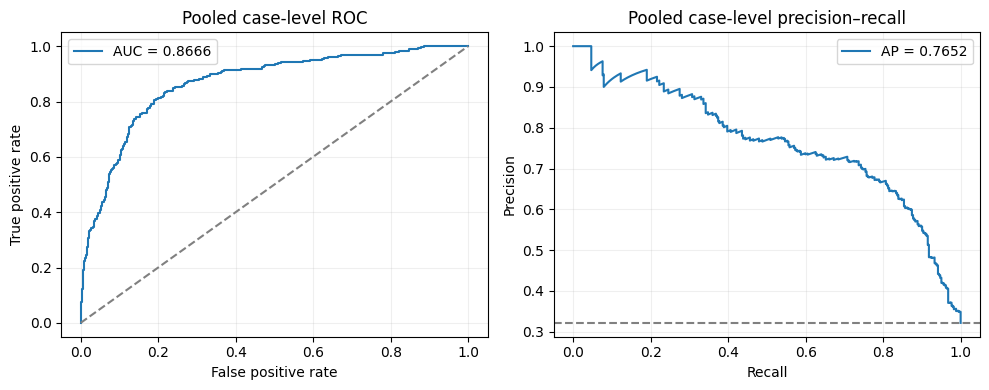


AUTOMATIC-CROP OUTER-TEST RESULTS


,Outer_fold,Selected_epoch,case_roc_auc,case_average_precision,case_balanced_accuracy_at_0.5,case_brier_score,cases
0,1,1,0.932598,0.880865,0.750408,0.120598,212
1,2,7,0.922705,0.863774,0.824728,0.106707,213
2,3,21,0.879310,0.794554,0.792951,0.147895,213
3,4,2,0.852374,0.725544,0.780260,0.154326,214
4,5,7,0.872141,0.808914,0.801062,0.171794,212



POOLED CASE-LEVEL RESULTS
{
  "cases": 1064,
  "case_roc_auc": 0.8666391278288057,
  "case_average_precision": 0.7652394141744612,
  "case_balanced_accuracy_at_0.5": 0.7900123114804556,
  "case_brier_score": 0.14026614568286913
}

Saved: /content/drive/MyDrive/BUSBRA_Research/results/automatic_crop_resnet18
No training performed. Checkpoint files unchanged.


In [ ]:
# CELL 61 — Automatic-crop outer-test evaluation, all five folds
# Uses saved predicted masks. Expert masks are not accessed.

import copy
from sklearn.metrics import roc_curve, precision_recall_curve

RESULTS_DIR = PROJECT_ROOT / "results" / "automatic_crop_resnet18"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

fold_results = []
all_image_predictions = []
all_case_predictions = []

expected_cases = {1: 212, 2: 213, 3: 213, 4: 214, 5: 212}
expected_images = {1: 376, 2: 385, 3: 366, 4: 365, 5: 383}

# Reuse the architecture without downloading or initialising new weights.
test_model = copy.deepcopy(classifier_model).to(DEVICE)

for fold in range(1, 6):
    run_dir = (
        PROJECT_ROOT / "models" / "automatic_crop_resnet18"
        / f"fold_{fold}"
    )
    checkpoint = torch.load(
        run_dir / "best.pt", map_location="cpu", weights_only=False
    )
    config = checkpoint["config"]
    assert config["outer_fold"] == fold
    assert float(config["crop_margin_per_side"]) == CROP_MARGIN

    verified_report = json.loads(
        (run_dir / "selected_validation_metrics.json").read_text()
    )
    assert verified_report["selected_epoch"] == int(checkpoint["epoch"])
    assert np.isclose(
        verified_report["case_roc_auc"], checkpoint["best_auc"],
        atol=1e-10, rtol=0,
    )

    state = dict(checkpoint["model_state"])
    # Earlier definitions may use these alternative buffer names.
    for old, new in (("mean", "image_mean"), ("std", "image_std")):
        if old in state and new not in state:
            state[new] = state.pop(old)
    test_model.load_state_dict(state, strict=True)

    partition = pd.read_csv(
        PROJECT_ROOT / "splits" / f"outer_fold_{fold}.csv"
    )
    test_table = partition.loc[partition["Split"].eq("test")].copy()
    mask_manifest = pd.read_csv(
        PROJECT_ROOT / "predicted_masks" / f"outer_fold_{fold}"
        / "mask_manifest.csv"
    )
    test_masks = mask_manifest.loc[
        mask_manifest["Split"].eq("test"),
        ["ID", "Case", "Mask_path"],
    ].rename(columns={"Case": "Mask_case"})

    test_table = test_table.merge(
        test_masks, on="ID", how="left", validate="one_to_one"
    )
    assert test_table["Mask_path"].notna().all()
    assert (
        test_table["Case"].astype(str)
        == test_table["Mask_case"].astype(str)
    ).all()
    assert len(test_table) == expected_images[fold]
    assert test_table["Case"].nunique() == expected_cases[fold]

    development_cases = set(
        partition.loc[partition["Split"].ne("test"), "Case"].astype(str)
    )
    assert set(test_table["Case"].astype(str)).isdisjoint(development_cases)

    # Use local images where available; otherwise read directly from Drive.
    test_table["Cached_image_path"] = [
        str(
            LOCAL_DATA_ROOT / relative
            if (LOCAL_DATA_ROOT / relative).exists()
            else DATA_ROOT / relative
        )
        for relative in test_table["Image_relative_path"]
    ]
    test_table["Cached_mask_path"] = test_table["Mask_path"]

    loader = DataLoader(
        AutomaticCropDataset(test_table, augment=False),
        batch_size=int(config["batch_size"]),
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
    )
    metrics, image_preds, case_preds = evaluate_classifier(test_model, loader)

    image_preds["Outer_fold"] = fold
    case_preds["Outer_fold"] = fold
    fold_results.append({
        "Outer_fold": fold,
        "Selected_epoch": int(checkpoint["epoch"]),
        **metrics,
    })
    all_image_predictions.append(image_preds)
    all_case_predictions.append(case_preds)

    # Save each completed fold immediately.
    image_preds.to_csv(
        RESULTS_DIR / f"fold_{fold}_test_image_predictions.csv", index=False
    )
    case_preds.to_csv(
        RESULTS_DIR / f"fold_{fold}_test_case_predictions.csv", index=False
    )
    print(
        f"Fold {fold} | Cases {metrics['cases']} | "
        f"Test AUC {metrics['case_roc_auc']:.4f} | "
        f"AP {metrics['case_average_precision']:.4f}",
        flush=True,
    )
    del checkpoint, state

outer_results = pd.DataFrame(fold_results)
pooled_images = pd.concat(all_image_predictions, ignore_index=True)
pooled_cases = pd.concat(all_case_predictions, ignore_index=True)

assert pooled_images["ID"].is_unique
assert pooled_cases["Case"].is_unique
assert len(pooled_images) == 1875
assert len(pooled_cases) == 1064

labels = pooled_cases["Label"].to_numpy()
probabilities = pooled_cases["Probability"].to_numpy()
pooled_metrics = {
    "cases": int(len(pooled_cases)),
    "case_roc_auc": float(roc_auc_score(labels, probabilities)),
    "case_average_precision": float(
        average_precision_score(labels, probabilities)
    ),
    "case_balanced_accuracy_at_0.5": float(
        balanced_accuracy_score(labels, probabilities >= 0.5)
    ),
    "case_brier_score": float(brier_score_loss(labels, probabilities)),
}

outer_results.to_csv(RESULTS_DIR / "outer_test_results.csv", index=False)
pooled_images.to_csv(
    RESULTS_DIR / "pooled_test_image_predictions.csv", index=False
)
pooled_cases.to_csv(
    RESULTS_DIR / "pooled_test_case_predictions.csv", index=False
)
(RESULTS_DIR / "pooled_test_metrics.json").write_text(
    json.dumps(pooled_metrics, indent=2)
)

fpr, tpr, _ = roc_curve(labels, probabilities)
precision, recall, _ = precision_recall_curve(labels, probabilities)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(
    fpr, tpr, label=f"AUC = {pooled_metrics['case_roc_auc']:.4f}"
)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(
    xlabel="False positive rate", ylabel="True positive rate",
    title="Pooled case-level ROC",
)
axes[1].plot(
    recall, precision,
    label=f"AP = {pooled_metrics['case_average_precision']:.4f}",
)
axes[1].axhline(labels.mean(), linestyle="--", color="gray")
axes[1].set(
    xlabel="Recall", ylabel="Precision",
    title="Pooled case-level precision–recall",
)
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pooled_test_curves.png", dpi=200)
plt.show()

print("\nAUTOMATIC-CROP OUTER-TEST RESULTS")
display(outer_results)
print("\nPOOLED CASE-LEVEL RESULTS")
print(json.dumps(pooled_metrics, indent=2))
print("\nSaved:", RESULTS_DIR)
print("No training performed. Checkpoint files unchanged.")

del test_model

In [ ]:
# CELL 62 — Locate saved case predictions for paired comparison
# Read-only. No training or inference.

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")

for name in (
    "full_image_resnet18",
    "expert_crop_resnet18",
    "automatic_crop_resnet18",
):
    folder = PROJECT_ROOT / "results" / name
    print(f"\n{name}")
    candidates = sorted(
        path for path in folder.glob("*.csv")
        if "case" in path.name.lower()
        and "prediction" in path.name.lower()
    )

    if not candidates:
        print("No matching prediction CSV found.")
        print("Available CSV files:", [p.name for p in folder.glob("*.csv")])

    for path in candidates:
        table = pd.read_csv(path)
        print(
            f"  {path.name} | Rows: {len(table)} | "
            f"Columns: {list(table.columns)}"
        )

print("\nInspection complete. No files changed.")


full_image_resnet18
  outer_test_case_predictions.csv | Rows: 1064 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']

expert_crop_resnet18
  outer_test_case_predictions.csv | Rows: 1064 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']

automatic_crop_resnet18
  fold_1_test_case_predictions.csv | Rows: 212 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']
  fold_2_test_case_predictions.csv | Rows: 213 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']
  fold_3_test_case_predictions.csv | Rows: 213 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']
  fold_4_test_case_predictions.csv | Rows: 214 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']
  fold_5_test_case_predictions.csv | Rows: 212 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']
  pooled_test_case_predictions.csv | Rows: 1064 | Columns: ['Case', 'Label', 'Probability', 'Images', 'Outer_fold']

Inspection

In [ ]:
# CELL 63 — Paired comparison of the three classifiers
# CPU only. No training or inference.
# Differences = candidate minus reference; lower Brier is better.

import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss,
)

comparison_dir = PROJECT_ROOT / "results" / "three_model_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

paths = {
    "Full_image": PROJECT_ROOT / "results" / "full_image_resnet18"
        / "outer_test_case_predictions.csv",
    "Expert_crop": PROJECT_ROOT / "results" / "expert_crop_resnet18"
        / "outer_test_case_predictions.csv",
    "Automatic_crop": PROJECT_ROOT / "results" / "automatic_crop_resnet18"
        / "pooled_test_case_predictions.csv",
}

tables = {}
for name, path in paths.items():
    table = pd.read_csv(path, dtype={"Case": str})
    assert len(table) == 1064
    assert table["Case"].notna().all() and table["Case"].is_unique
    assert table["Label"].isin([0, 1]).all()
    assert np.isfinite(table["Probability"]).all()
    assert table["Probability"].between(0, 1).all()
    tables[name] = table.set_index("Case").sort_index()

reference = tables["Full_image"]
for name, table in tables.items():
    assert table.index.equals(reference.index), f"Case mismatch: {name}"
    for column in ("Label", "Outer_fold", "Images"):
        assert np.array_equal(table[column], reference[column]), (
            f"{column} mismatch: {name}"
        )

y = reference["Label"].to_numpy(dtype=int)
folds = reference["Outer_fold"].to_numpy(dtype=int)
names = list(tables)
probabilities = np.column_stack([
    tables[name]["Probability"].to_numpy() for name in names
])

metric_names = [
    "ROC_AUC", "Average_precision",
    "Balanced_accuracy_at_0.5", "Brier_score",
]


def metric_vector(labels, scores):
    return np.array([
        roc_auc_score(labels, scores),
        average_precision_score(labels, scores),
        balanced_accuracy_score(labels, scores >= 0.5),
        brier_score_loss(labels, scores),
    ])


observed = np.stack([
    metric_vector(y, probabilities[:, j]) for j in range(len(names))
])

# Same sampled cases are used for every model in each replicate.
N_BOOTSTRAP = 2000
rng = np.random.default_rng(2026)
bootstrap = np.empty((N_BOOTSTRAP, len(names), len(metric_names)))

for b in tqdm(range(N_BOOTSTRAP), desc="Paired case bootstrap"):
    while True:
        indices = rng.integers(0, len(y), size=len(y))
        if np.unique(y[indices]).size == 2:
            break
    for j in range(len(names)):
        bootstrap[b, j] = metric_vector(
            y[indices], probabilities[indices, j]
        )

absolute_rows = []
for j, name in enumerate(names):
    for k, metric in enumerate(metric_names):
        low, high = np.quantile(bootstrap[:, j, k], [0.025, 0.975])
        absolute_rows.append({
            "Model": name,
            "Metric": metric,
            "Estimate": observed[j, k],
            "CI_95_lower": low,
            "CI_95_upper": high,
        })
absolute_results = pd.DataFrame(absolute_rows)

pairs = [
    ("Expert_crop", "Full_image"),
    ("Automatic_crop", "Full_image"),
    ("Automatic_crop", "Expert_crop"),
]
difference_rows = []
fold_rows = []

for candidate, baseline in pairs:
    candidate_index = names.index(candidate)
    baseline_index = names.index(baseline)

    for k, metric in enumerate(metric_names):
        differences = (
            bootstrap[:, candidate_index, k]
            - bootstrap[:, baseline_index, k]
        )
        low, high = np.quantile(differences, [0.025, 0.975])
        difference_rows.append({
            "Candidate": candidate,
            "Reference": baseline,
            "Metric": metric,
            "Reference_value": observed[baseline_index, k],
            "Candidate_value": observed[candidate_index, k],
            "Difference": (
                observed[candidate_index, k] - observed[baseline_index, k]
            ),
            "Difference_CI_95_lower": low,
            "Difference_CI_95_upper": high,
        })

    for fold in sorted(np.unique(folds)):
        selected = folds == fold
        difference = (
            metric_vector(y[selected], probabilities[selected, candidate_index])
            - metric_vector(y[selected], probabilities[selected, baseline_index])
        )
        fold_rows.append({
            "Candidate": candidate,
            "Reference": baseline,
            "Outer_fold": int(fold),
            **dict(zip(metric_names, difference)),
        })

paired_results = pd.DataFrame(difference_rows)
within_fold_results = pd.DataFrame(fold_rows)
mean_fold_differences = within_fold_results.groupby(
    ["Candidate", "Reference"]
)[metric_names].mean()

absolute_results.to_csv(
    comparison_dir / "pooled_metrics_with_ci.csv", index=False
)
paired_results.to_csv(
    comparison_dir / "pooled_paired_differences.csv", index=False
)
within_fold_results.to_csv(
    comparison_dir / "within_fold_differences.csv", index=False
)
mean_fold_differences.to_csv(
    comparison_dir / "mean_within_fold_differences.csv"
)

matched = reference[["Label", "Outer_fold", "Images"]].copy()
for j, name in enumerate(names):
    matched[name] = probabilities[:, j]
matched.reset_index().to_csv(
    comparison_dir / "matched_case_predictions.csv", index=False
)

np.savez_compressed(
    comparison_dir / "paired_bootstrap_samples.npz",
    values=bootstrap,
    models=np.array(names),
    metrics=np.array(metric_names),
)
(comparison_dir / "comparison_config.json").write_text(json.dumps({
    "cases": len(y),
    "bootstrap_replicates": N_BOOTSTRAP,
    "seed": 2026,
    "resampling": "Unstratified paired case bootstrap",
    "interval": "Pointwise percentile 95%; no multiplicity adjustment",
    "difference_direction": "Candidate minus reference",
    "uncertainty_scope": "Conditional on fitted models; no retraining",
}, indent=2))

print("\nPOOLED METRICS WITH 95% CONFIDENCE INTERVALS")
display(absolute_results.round(4))
print("\nPOOLED PAIRED DIFFERENCES — CANDIDATE MINUS REFERENCE")
display(paired_results.round(4))
print("\nWITHIN-FOLD DIFFERENCES")
display(within_fold_results.round(4))
print("\nMEAN WITHIN-FOLD DIFFERENCES")
display(mean_fold_differences.round(4))
print("\nPositive differences favour the candidate except for Brier score.")
print("Intervals are pointwise and conditional on the fitted models.")
print("Saved:", comparison_dir)
print("No training or inference performed.")

Paired case bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]


POOLED METRICS WITH 95% CONFIDENCE INTERVALS


,Model,Metric,Estimate,CI_95_lower,CI_95_upper
0,Full_image,ROC_AUC,0.9071,0.8876,0.9264
1,Full_image,Average_precision,0.8421,0.8061,0.8761
2,Full_image,Balanced_accuracy_at_0.5,0.8172,0.7917,0.8420
3,Full_image,Brier_score,0.1176,0.1019,0.1331
4,Expert_crop,ROC_AUC,0.8885,0.8659,0.9096
5,Expert_crop,Average_precision,0.8140,0.7768,0.8491
6,Expert_crop,Balanced_accuracy_at_0.5,0.8044,0.7780,0.8296
7,Expert_crop,Brier_score,0.1246,0.1095,0.1401
8,Automatic_crop,ROC_AUC,0.8666,0.8437,0.8897
9,Automatic_crop,Average_precision,0.7652,0.7210,0.8078



POOLED PAIRED DIFFERENCES — CANDIDATE MINUS REFERENCE


,Candidate,Reference,Metric,Reference_value,Candidate_value,Difference,Difference_CI_95_lower,Difference_CI_95_upper
0,Expert_crop,Full_image,ROC_AUC,0.9071,0.8885,-0.0185,-0.0404,0.0030
1,Expert_crop,Full_image,Average_precision,0.8421,0.8140,-0.0282,-0.0613,0.0063
2,Expert_crop,Full_image,Balanced_accuracy_at_0.5,0.8172,0.8044,-0.0128,-0.0409,0.0169
3,Expert_crop,Full_image,Brier_score,0.1176,0.1246,0.0070,-0.0095,0.0235
4,Automatic_crop,Full_image,ROC_AUC,0.9071,0.8666,-0.0404,-0.0639,-0.0192
5,Automatic_crop,Full_image,Average_precision,0.8421,0.7652,-0.0769,-0.1178,-0.0364
6,Automatic_crop,Full_image,Balanced_accuracy_at_0.5,0.8172,0.7900,-0.0272,-0.0562,0.0027
7,Automatic_crop,Full_image,Brier_score,0.1176,0.1403,0.0226,0.0070,0.0383
8,Automatic_crop,Expert_crop,ROC_AUC,0.8885,0.8666,-0.0219,-0.0426,-0.0020
9,Automatic_crop,Expert_crop,Average_precision,0.8140,0.7652,-0.0487,-0.0808,-0.0154



WITHIN-FOLD DIFFERENCES


,Candidate,Reference,Outer_fold,ROC_AUC,Average_precision,Balanced_accuracy_at_0.5,Brier_score
0,Expert_crop,Full_image,1,-0.0253,-0.0538,-0.0952,0.0341
1,Expert_crop,Full_image,2,0.0331,0.0486,-0.0673,-0.0111
2,Expert_crop,Full_image,3,-0.0096,0.0073,0.0299,0.0002
3,Expert_crop,Full_image,4,-0.0089,-0.0018,0.0093,0.0154
4,Expert_crop,Full_image,5,0.0019,0.0141,0.0605,-0.0037
5,Automatic_crop,Full_image,1,-0.0258,-0.0561,-0.1250,0.0462
6,Automatic_crop,Full_image,2,0.0300,0.0276,0.0069,-0.0202
7,Automatic_crop,Full_image,3,-0.0249,-0.0409,-0.0113,0.0193
8,Automatic_crop,Full_image,4,-0.0342,-0.0752,-0.0334,0.0231
9,Automatic_crop,Full_image,5,-0.0242,-0.0176,0.0266,0.0450



MEAN WITHIN-FOLD DIFFERENCES


ROC_AUC  Average_precision  \
Candidate      Reference                                 
Automatic_crop Expert_crop  -0.0141            -0.0353   
               Full_image   -0.0158            -0.0324   
Expert_crop    Full_image   -0.0018             0.0029   

                            Balanced_accuracy_at_0.5  Brier_score  
Candidate      Reference                                           
Automatic_crop Expert_crop                   -0.0147       0.0157  
               Full_image                    -0.0272       0.0227  
Expert_crop    Full_image                    -0.0126       0.0070


Positive differences favour the candidate except for Brier score.
Intervals are pointwise and conditional on the fitted models.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/three_model_comparison
No training or inference performed.


In [ ]:
# CELL 64 — Inspect existing outputs for error analysis
# No training, inference, or image copying. No files changed.

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")

folders_to_inspect = {
    "Segmentation results":
        PROJECT_ROOT / "results" / "segmentation_resnet18_unet",
    "Full-image classification":
        PROJECT_ROOT / "results" / "full_image_resnet18",
    "Expert-crop classification":
        PROJECT_ROOT / "results" / "expert_crop_resnet18",
    "Automatic-crop classification":
        PROJECT_ROOT / "results" / "automatic_crop_resnet18",
}

for title, folder in folders_to_inspect.items():
    print(f"\n{'=' * 72}\n{title}\n{'=' * 72}")

    if not folder.exists():
        print("Folder missing:", folder)
        continue

    candidates = sorted(
        path for path in folder.rglob("*.csv")
        if (
            "image" in path.name.lower()
            or "segmentation" in title.lower()
        )
    )

    for path in candidates:
        table = pd.read_csv(path)
        print(f"\n{path.relative_to(folder)} | Rows: {len(table):,}")
        print("Columns:", list(table.columns))
        print(table.head(2).to_string(index=False))

    if not candidates:
        print("Available CSV files:")
        for path in sorted(folder.rglob("*.csv")):
            print(" ", path.relative_to(folder))

print("\nPREDICTED-MASK MANIFEST — FOLD 1")
manifest_path = (
    PROJECT_ROOT / "predicted_masks" / "outer_fold_1"
    / "mask_manifest.csv"
)
manifest = pd.read_csv(manifest_path)
print("Columns:", list(manifest.columns))
print(manifest.head(2).to_string(index=False))

print("\nANALYSIS MANIFEST")
analysis_manifest = pd.read_csv(
    PROJECT_ROOT / "audit" / "analysis_manifest.csv"
)
print("Columns:", list(analysis_manifest.columns))
print(analysis_manifest.head(2).to_string(index=False))

print("\nInspection complete. No files changed.")


Segmentation results

outer_test_case_scores.csv | Rows: 1,064
Columns: ['Case', 'Dice', 'IoU', 'Images', 'Outer_fold']
 Case     Dice      IoU  Images  Outer_fold
 1000 0.894403 0.811331       2           1
 1003 0.771460 0.657821       2           1

outer_test_fold_metrics.csv | Rows: 5
Columns: ['Outer_fold', 'Selected_epoch', 'case_dice', 'case_iou', 'empty_prediction_images', 'cases']
 Outer_fold  Selected_epoch  case_dice  case_iou  empty_prediction_images  cases
          1              15   0.891135  0.817964                        1    212
          2              23   0.880283  0.807375                        2    213

outer_test_image_scores.csv | Rows: 1,875
Columns: ['ID', 'Case', 'Dice', 'IoU', 'Empty_prediction', 'Outer_fold']
        ID  Case     Dice      IoU  Empty_prediction  Outer_fold
bus_0007-l     7 0.919325 0.850694             False           1
bus_0007-r     7 0.894244 0.808717             False           1

Full-image classification

outer_test_image_predic

In [ ]:
# CELL 65 — Link segmentation quality to classification errors
# CPU only. No training, inference, or mask reading.

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ERROR_DIR = PROJECT_ROOT / "results" / "error_analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

segmentation = pd.read_csv(
    PROJECT_ROOT / "results" / "segmentation_resnet18_unet"
    / "outer_test_image_scores.csv",
    dtype={"ID": str, "Case": str},
)

prediction_paths = {
    "Full_image": PROJECT_ROOT / "results" / "full_image_resnet18"
        / "outer_test_image_predictions.csv",
    "Expert_crop": PROJECT_ROOT / "results" / "expert_crop_resnet18"
        / "outer_test_image_predictions.csv",
    "Automatic_crop": PROJECT_ROOT / "results" / "automatic_crop_resnet18"
        / "pooled_test_image_predictions.csv",
}

keys = ["ID", "Case", "Outer_fold"]
assert len(segmentation) == 1875
assert segmentation["ID"].is_unique

linked = segmentation.copy()

for name, path in prediction_paths.items():
    predictions = pd.read_csv(path, dtype={"ID": str, "Case": str})
    assert predictions["ID"].is_unique
    assert set(predictions["ID"]) == set(linked["ID"])

    linked = linked.merge(
        predictions[keys + ["Label", "Probability"]].rename(
            columns={"Label": f"Label_{name}", "Probability": name}
        ),
        on=keys,
        how="left",
        validate="one_to_one",
    )
    assert linked[[f"Label_{name}", name]].notna().all().all()
    assert linked[name].between(0, 1).all()

linked["Label"] = linked["Label_Full_image"].astype(int)
for name in prediction_paths:
    assert linked[f"Label_{name}"].eq(linked["Label"]).all()
assert linked.groupby("Case")["Label"].nunique().eq(1).all()
assert linked.groupby("Case")["Outer_fold"].nunique().eq(1).all()

# Handle Boolean values robustly after CSV loading.
empty_values = linked["Empty_prediction"].astype(str).str.lower()
assert empty_values.isin(["true", "false", "1", "0"]).all()
linked["Empty_prediction"] = empty_values.isin(["true", "1"]).astype(int)

case_analysis = linked.groupby("Case", as_index=False).agg(
    Label=("Label", "first"),
    Outer_fold=("Outer_fold", "first"),
    Images=("ID", "size"),
    Mean_Dice=("Dice", "mean"),
    Minimum_Dice=("Dice", "min"),
    Mean_IoU=("IoU", "mean"),
    Empty_prediction_images=("Empty_prediction", "sum"),
    Full_image=("Full_image", "mean"),
    Expert_crop=("Expert_crop", "mean"),
    Automatic_crop=("Automatic_crop", "mean"),
)
assert len(case_analysis) == 1064

for name in prediction_paths:
    case_analysis[f"{name}_error"] = (
        (case_analysis[name] >= 0.5)
        != case_analysis["Label"].astype(bool)
    ).astype(int)
    case_analysis[f"{name}_Brier"] = (
        case_analysis[name] - case_analysis["Label"]
    ) ** 2

case_analysis["Brier_difference_auto_minus_full"] = (
    case_analysis["Automatic_crop_Brier"]
    - case_analysis["Full_image_Brier"]
)
case_analysis["Brier_difference_auto_minus_expert"] = (
    case_analysis["Automatic_crop_Brier"]
    - case_analysis["Expert_crop_Brier"]
)

# Fixed descriptive bands; not used for model or threshold selection.
case_analysis["Dice_band"] = pd.cut(
    case_analysis["Mean_Dice"],
    bins=[-np.inf, 0.5, 0.8, 0.9, np.inf],
    labels=["<0.50", "0.50–<0.80", "0.80–<0.90", "≥0.90"],
    right=False,
)

band_summary = case_analysis.groupby(
    "Dice_band", observed=True
).agg(
    Cases=("Case", "size"),
    Malignant_cases=("Label", "sum"),
    Mean_Dice=("Mean_Dice", "mean"),
    Full_image_error_rate=("Full_image_error", "mean"),
    Expert_crop_error_rate=("Expert_crop_error", "mean"),
    Automatic_crop_error_rate=("Automatic_crop_error", "mean"),
    Brier_difference_auto_minus_full=(
        "Brier_difference_auto_minus_full", "mean"
    ),
    Brier_difference_auto_minus_expert=(
        "Brier_difference_auto_minus_expert", "mean"
    ),
)

# Paired error patterns at the existing threshold of 0.5.
error_patterns = []
for baseline in ("Full_image", "Expert_crop"):
    baseline_wrong = case_analysis[f"{baseline}_error"].astype(bool)
    automatic_wrong = case_analysis["Automatic_crop_error"].astype(bool)

    for pattern, selected in {
        "Both correct": ~baseline_wrong & ~automatic_wrong,
        "Automatic wrong; reference correct": automatic_wrong & ~baseline_wrong,
        "Automatic correct; reference wrong": ~automatic_wrong & baseline_wrong,
        "Both wrong": automatic_wrong & baseline_wrong,
    }.items():
        subset = case_analysis.loc[selected]
        error_patterns.append({
            "Reference": baseline,
            "Pattern": pattern,
            "Cases": len(subset),
            "Mean_Dice": subset["Mean_Dice"].mean(),
            "Median_Dice": subset["Mean_Dice"].median(),
            "Cases_with_empty_prediction": int(
                subset["Empty_prediction_images"].gt(0).sum()
            ),
        })
error_patterns = pd.DataFrame(error_patterns)

# Descriptive associations overall and separately by class.
association_rows = []
for group, subset in [
    ("All cases", case_analysis),
    ("Benign", case_analysis.loc[case_analysis["Label"].eq(0)]),
    ("Malignant", case_analysis.loc[case_analysis["Label"].eq(1)]),
]:
    for outcome in (
        "Automatic_crop_Brier",
        "Brier_difference_auto_minus_full",
        "Brier_difference_auto_minus_expert",
    ):
        rho = spearmanr(subset["Mean_Dice"], subset[outcome]).statistic
        association_rows.append({
            "Group": group,
            "Cases": len(subset),
            "Outcome": outcome,
            "Spearman_rho": rho,
        })
associations = pd.DataFrame(association_rows)

linked.to_csv(ERROR_DIR / "linked_image_outputs.csv", index=False)
case_analysis.to_csv(ERROR_DIR / "linked_case_outputs.csv", index=False)
band_summary.to_csv(ERROR_DIR / "segmentation_quality_bands.csv")
error_patterns.to_csv(ERROR_DIR / "paired_error_patterns.csv", index=False)
associations.to_csv(
    ERROR_DIR / "segmentation_error_associations.csv", index=False
)

print("SEGMENTATION QUALITY AND CASE-LEVEL CLASSIFICATION ERROR")
display(band_summary.round(4))

print("\nPAIRED ERROR PATTERNS AT THRESHOLD 0.5")
display(error_patterns.round(4))

print("\nDESCRIPTIVE SPEARMAN ASSOCIATIONS")
display(associations.round(4))

print("\nPositive Brier differences indicate worse automatic-crop predictions.")
print("Associations are exploratory and do not establish causation.")
print("Dice scores were measured on the 256 × 256 padded canvas.")
print("Saved:", ERROR_DIR)
print("No training or inference performed.")

SEGMENTATION QUALITY AND CASE-LEVEL CLASSIFICATION ERROR


,Cases,Malignant_cases,Mean_Dice,Full_image_error_rate,Expert_crop_error_rate,Automatic_crop_error_rate,Brier_difference_auto_minus_full,Brier_difference_auto_minus_expert
Dice_band,,,,,,,,
<0.50,19,6,0.2569,0.3158,0.2632,0.2632,0.0101,-0.0262
0.50–<0.80,71,38,0.7126,0.1690,0.1831,0.2958,0.0761,0.0721
0.80–<0.90,256,119,0.8623,0.1680,0.1641,0.1719,-0.0062,0.0270
≥0.90,718,179,0.9390,0.1295,0.1504,0.1685,0.0279,0.0072



PAIRED ERROR PATTERNS AT THRESHOLD 0.5


,Reference,Pattern,Cases,Mean_Dice,Median_Dice,Cases_with_empty_prediction
0,Full_image,Both correct,811,0.8994,0.9256,3
1,Full_image,Automatic wrong; reference correct,99,0.8800,0.9205,1
2,Full_image,Automatic correct; reference wrong,62,0.8728,0.9113,0
3,Full_image,Both wrong,92,0.8676,0.9174,1
4,Expert_crop,Both correct,812,0.9003,0.9260,2
5,Expert_crop,Automatic wrong; reference correct,84,0.8634,0.9166,1
6,Expert_crop,Automatic correct; reference wrong,61,0.8597,0.9068,1
7,Expert_crop,Both wrong,107,0.8824,0.9206,1



DESCRIPTIVE SPEARMAN ASSOCIATIONS


,Group,Cases,Outcome,Spearman_rho
0,All cases,1064,Automatic_crop_Brier,-0.1291
1,All cases,1064,Brier_difference_auto_minus_full,-0.0366
2,All cases,1064,Brier_difference_auto_minus_expert,-0.0544
3,Benign,722,Automatic_crop_Brier,-0.1296
4,Benign,722,Brier_difference_auto_minus_full,-0.0507
5,Benign,722,Brier_difference_auto_minus_expert,0.0119
6,Malignant,342,Automatic_crop_Brier,0.0705
7,Malignant,342,Brier_difference_auto_minus_full,-0.0193
8,Malignant,342,Brier_difference_auto_minus_expert,-0.1511



Positive Brier differences indicate worse automatic-crop predictions.
Associations are exploratory and do not establish causation.
Dice scores were measured on the 256 × 256 padded canvas.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/error_analysis
No training or inference performed.


In [ ]:
# CELL 66 — Original-size crop geometry and lesion coverage
# Exploratory analysis only. No training or inference.

import math
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

ERROR_DIR = PROJECT_ROOT / "results" / "error_analysis"
GEOMETRY_PATH = ERROR_DIR / "original_size_crop_geometry.csv"

metadata = pd.read_csv(
    PROJECT_ROOT / "audit" / "analysis_manifest.csv",
    dtype={"ID": str, "Case": str},
).set_index("ID")
assert metadata.index.is_unique

test_manifests = []
for fold in range(1, 6):
    manifest = pd.read_csv(
        PROJECT_ROOT / "predicted_masks" / f"outer_fold_{fold}"
        / "mask_manifest.csv",
        dtype={"ID": str, "Case": str},
    )
    test_manifests.append(manifest.loc[manifest["Split"].eq("test")])

mask_table = pd.concat(test_manifests, ignore_index=True)
assert len(mask_table) == 1875
assert mask_table["ID"].is_unique

if GEOMETRY_PATH.exists():
    geometry_records = pd.read_csv(
        GEOMETRY_PATH, dtype={"ID": str, "Case": str}
    ).to_dict("records")
else:
    geometry_records = []

completed = {row["ID"] for row in geometry_records}
assert len(completed) == len(geometry_records)
assert completed.issubset(set(mask_table["ID"]))


def margin_box(binary_mask, margin=0.2):
    height, width = binary_mask.shape
    ys, xs = np.where(binary_mask)
    if len(xs) == 0:
        return (0, 0, width, height), True

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    mx = math.ceil((x1 - x0) * margin)
    my = math.ceil((y1 - y0) * margin)
    return (
        max(0, x0 - mx), max(0, y0 - my),
        min(width, x1 + mx), min(height, y1 + my),
    ), False


def save_geometry():
    temporary = GEOMETRY_PATH.with_suffix(".tmp.csv")
    pd.DataFrame(geometry_records).to_csv(temporary, index=False)
    temporary.replace(GEOMETRY_PATH)


pending = mask_table.loc[~mask_table["ID"].isin(completed)]
print(f"Already measured: {len(completed)} | Remaining: {len(pending)}")

for row in tqdm(
    pending.itertuples(index=False),
    total=len(pending),
    desc="Measuring saved crop geometry",
):
    info = metadata.loc[row.ID]
    assert str(info["Case"]) == str(row.Case)

    with Image.open(row.Mask_path) as source:
        predicted = np.asarray(source.convert("L")) > 0
    with Image.open(DATA_ROOT / info["Mask_relative_path"]) as source:
        expert = np.asarray(source.convert("L")) > 0

    assert predicted.shape == expert.shape
    height, width = expert.shape
    assert width == int(row.Width) and height == int(row.Height)
    expert_area = int(expert.sum())
    assert expert_area > 0

    auto_box, fallback = margin_box(predicted)
    expert_box, _ = margin_box(expert)
    x0, y0, x1, y1 = auto_box
    ex0, ey0, ex1, ey1 = expert_box

    auto_area = (x1 - x0) * (y1 - y0)
    expert_crop_area = (ex1 - ex0) * (ey1 - ey0)
    coverage = float(expert[y0:y1, x0:x1].sum() / expert_area)
    intersection = int((predicted & expert).sum())
    total_area = int(predicted.sum()) + expert_area
    original_dice = 2 * intersection / total_area

    box_intersection = (
        max(0, min(x1, ex1) - max(x0, ex0))
        * max(0, min(y1, ey1) - max(y0, ey0))
    )
    box_union = auto_area + expert_crop_area - box_intersection

    geometry_records.append({
        "ID": row.ID,
        "Case": str(row.Case),
        "Outer_fold": int(row.Outer_fold),
        "Label": int(info["Label"]),
        "Width": width,
        "Height": height,
        "Empty_mask_fallback": int(fallback),
        "Original_size_Dice": original_dice,
        "Expert_lesion_coverage": coverage,
        "Expert_lesion_fraction_excluded": 1 - coverage,
        "Auto_crop_area_fraction": auto_area / (width * height),
        "Expert_crop_area_fraction": expert_crop_area / (width * height),
        "Auto_to_expert_crop_area_ratio": auto_area / expert_crop_area,
        "Crop_box_IoU": box_intersection / box_union,
        "Auto_x0": x0, "Auto_y0": y0,
        "Auto_x1": x1, "Auto_y1": y1,
    })

    if len(geometry_records) % 100 == 0:
        save_geometry()

save_geometry()
geometry = pd.DataFrame(geometry_records)
assert len(geometry) == 1875

case_geometry = geometry.groupby("Case", as_index=False).agg(
    Outer_fold=("Outer_fold", "first"),
    Label=("Label", "first"),
    Minimum_lesion_coverage=("Expert_lesion_coverage", "min"),
    Mean_lesion_coverage=("Expert_lesion_coverage", "mean"),
    Mean_auto_crop_area_fraction=("Auto_crop_area_fraction", "mean"),
    Mean_crop_area_ratio=("Auto_to_expert_crop_area_ratio", "mean"),
    Mean_crop_box_IoU=("Crop_box_IoU", "mean"),
    Empty_mask_images=("Empty_mask_fallback", "sum"),
)

case_outputs = pd.read_csv(
    ERROR_DIR / "linked_case_outputs.csv", dtype={"Case": str}
)
case_geometry = case_geometry.merge(
    case_outputs[[
        "Case", "Full_image_error", "Expert_crop_error",
        "Automatic_crop_error", "Brier_difference_auto_minus_full",
        "Brier_difference_auto_minus_expert",
    ]],
    on="Case", how="left", validate="one_to_one",
)
assert case_geometry["Automatic_crop_error"].notna().all()

case_geometry["Coverage_band"] = pd.cut(
    case_geometry["Minimum_lesion_coverage"],
    bins=[-np.inf, 0.90, 0.99, np.inf],
    labels=["<90%", "90–<99%", "≥99%"],
    right=False,
)

coverage_summary = case_geometry.groupby(
    "Coverage_band", observed=True
).agg(
    Cases=("Case", "size"),
    Malignant_cases=("Label", "sum"),
    Mean_minimum_coverage=("Minimum_lesion_coverage", "mean"),
    Full_image_error_rate=("Full_image_error", "mean"),
    Expert_crop_error_rate=("Expert_crop_error", "mean"),
    Automatic_crop_error_rate=("Automatic_crop_error", "mean"),
    Brier_difference_auto_minus_full=(
        "Brier_difference_auto_minus_full", "mean"
    ),
    Brier_difference_auto_minus_expert=(
        "Brier_difference_auto_minus_expert", "mean"
    ),
)

case_geometry.to_csv(
    ERROR_DIR / "case_crop_geometry.csv", index=False
)
coverage_summary.to_csv(
    ERROR_DIR / "lesion_coverage_summary.csv"
)

print("\nORIGINAL-SIZE CROP GEOMETRY")
display(geometry[[
    "Expert_lesion_coverage", "Auto_crop_area_fraction",
    "Auto_to_expert_crop_area_ratio", "Crop_box_IoU",
]].describe().round(4))

print("\nCASE-LEVEL RESULTS BY MINIMUM LESION COVERAGE")
display(coverage_summary.round(4))

print("\nImages using full-image fallback:",
      int(geometry["Empty_mask_fallback"].sum()))
print("Images excluding more than 1% of the expert lesion:",
      int((geometry["Expert_lesion_coverage"] < 0.99).sum()))
print("Coverage includes the established full-image fallback.")
print("Saved:", ERROR_DIR)
print("No training or inference performed.")

Already measured: 0 | Remaining: 1875


Measuring saved crop geometry:   0%|          | 0/1875 [00:00<?, ?it/s]


ORIGINAL-SIZE CROP GEOMETRY


,Expert_lesion_coverage,Auto_crop_area_fraction,Auto_to_expert_crop_area_ratio,Crop_box_IoU
count,1875.0000,1875.0000,1875.0000,1875.0000
mean,0.9911,0.2313,1.0659,0.8507
std,0.0668,0.1773,0.7849,0.1422
min,0.0000,0.0192,0.0730,0.0000
25%,1.0000,0.0917,0.8979,0.8178
50%,1.0000,0.1811,0.9825,0.8930
75%,1.0000,0.3232,1.0574,0.9383
max,1.0000,1.0000,16.7555,1.0000



CASE-LEVEL RESULTS BY MINIMUM LESION COVERAGE


,Cases,Malignant_cases,Mean_minimum_coverage,Full_image_error_rate,Expert_crop_error_rate,Automatic_crop_error_rate,Brier_difference_auto_minus_full,Brier_difference_auto_minus_expert
Coverage_band,,,,,,,,
<90%,35,20,0.6332,0.2286,0.1714,0.2286,0.0179,0.0807
90–<99%,40,27,0.9584,0.2250,0.3250,0.2500,0.0203,-0.0032
≥99%,989,295,0.9999,0.1385,0.1507,0.1749,0.0229,0.0141



Images using full-image fallback: 6
Images excluding more than 1% of the expert lesion: 82
Coverage includes the established full-image fallback.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/error_analysis
No training or inference performed.


In [ ]:
# CELL 67 — Class- and fold-specific analysis of lesion-preserving crops
# CSV analysis only. No training, inference, or mask reading.

from scipy.stats import spearmanr

ERROR_DIR = PROJECT_ROOT / "results" / "error_analysis"

geometry = pd.read_csv(
    ERROR_DIR / "case_crop_geometry.csv", dtype={"Case": str}
)
outputs = pd.read_csv(
    ERROR_DIR / "linked_case_outputs.csv", dtype={"Case": str}
)

assert geometry["Case"].is_unique and outputs["Case"].is_unique
assert set(geometry["Case"]) == set(outputs["Case"])

analysis = geometry.merge(
    outputs[[
        "Case", "Full_image", "Expert_crop", "Automatic_crop",
        "Full_image_Brier", "Expert_crop_Brier", "Automatic_crop_Brier",
    ]],
    on="Case", how="left", validate="one_to_one",
)
analysis["Diagnosis"] = analysis["Label"].map({0: "Benign", 1: "Malignant"})
analysis["Lesion_preserved"] = analysis["Minimum_lesion_coverage"] >= 0.99
analysis["Has_fallback"] = analysis["Empty_mask_images"] > 0

def summarize_groups(table, columns):
    return table.groupby(columns, observed=True).agg(
        Cases=("Case", "size"),
        Full_image_error_rate=("Full_image_error", "mean"),
        Expert_crop_error_rate=("Expert_crop_error", "mean"),
        Automatic_crop_error_rate=("Automatic_crop_error", "mean"),
        Full_image_Brier=("Full_image_Brier", "mean"),
        Expert_crop_Brier=("Expert_crop_Brier", "mean"),
        Automatic_crop_Brier=("Automatic_crop_Brier", "mean"),
        Brier_difference_auto_minus_full=(
            "Brier_difference_auto_minus_full", "mean"
        ),
        Brier_difference_auto_minus_expert=(
            "Brier_difference_auto_minus_expert", "mean"
        ),
    )

class_summary = summarize_groups(
    analysis, ["Lesion_preserved", "Diagnosis"]
)

# Exclude full-image fallbacks for a stricter descriptive subset.
preserved = analysis.loc[
    analysis["Lesion_preserved"] & ~analysis["Has_fallback"]
].copy()

fold_summary = summarize_groups(preserved, ["Outer_fold"])

association_rows = []
for diagnosis in ("Benign", "Malignant"):
    subset = preserved.loc[preserved["Diagnosis"].eq(diagnosis)]
    for feature in (
        "Mean_auto_crop_area_fraction",
        "Mean_crop_area_ratio",
        "Mean_crop_box_IoU",
    ):
        for outcome in (
            "Brier_difference_auto_minus_full",
            "Brier_difference_auto_minus_expert",
        ):
            rho = spearmanr(subset[feature], subset[outcome]).statistic
            association_rows.append({
                "Diagnosis": diagnosis,
                "Cases": len(subset),
                "Geometry_measure": feature,
                "Outcome": outcome,
                "Spearman_rho": rho,
            })

associations = pd.DataFrame(association_rows)

class_summary.to_csv(ERROR_DIR / "coverage_by_diagnosis.csv")
fold_summary.to_csv(ERROR_DIR / "preserved_lesion_by_fold.csv")
associations.to_csv(
    ERROR_DIR / "preserved_lesion_geometry_associations.csv", index=False
)

print("LESION COVERAGE AND ERRORS BY DIAGNOSIS")
display(class_summary.round(4))
print("For benign cases, error rate is the false-positive rate.")
print("For malignant cases, error rate is the false-negative rate.")

print("\nLESION-PRESERVING CASES, EXCLUDING FULL-IMAGE FALLBACKS")
print("Cases:", len(preserved))
display(fold_summary.round(4))

print("\nGEOMETRY ASSOCIATIONS WITHIN DIAGNOSIS")
display(associations.round(4))

print("\nExploratory subgroup results; no causal attribution.")
print("Positive Brier differences indicate worse automatic-crop predictions.")
print("Saved:", ERROR_DIR)
print("No training or inference performed.")

LESION COVERAGE AND ERRORS BY DIAGNOSIS


Cases  Full_image_error_rate  \
Lesion_preserved Diagnosis                                 
False            Benign        28                 0.1429   
                 Malignant     47                 0.2766   
True             Benign       694                 0.0735   
                 Malignant    295                 0.2915   

                            Expert_crop_error_rate  Automatic_crop_error_rate  \
Lesion_preserved Diagnosis                                                      
False            Benign                     0.1786                     0.1786   
                 Malignant                  0.2979                     0.2766   
True             Benign                     0.0865                     0.1225   
                 Malignant                  0.3017                     0.2983   

                            Full_image_Brier  Expert_crop_Brier  \
Lesion_preserved Diagnosis                                        
False            Benign               0.1201             0.1257   
                 Malignant            0.2183             0.1881   
True             Benign               0.0654             0.0740   
                 Malignant            0.2242             0.2334   

                            Automatic_crop_Brier  \
Lesion_preserved Diagnosis                         
False            Benign                   0.1306   
                 Malignant                0.2426   
True             Benign                   0.0952   
                 Malignant                0.2309   

                            Brier_difference_auto_minus_full  \
Lesion_preserved Diagnosis                                     
False            Benign                               0.0106   
                 Malignant                            0.0243   
True             Benign                               0.0298   
                 Malignant                            0.0067   

                            Brier_difference_auto_minus_expert  
Lesion_preserved Diagnosis                                      
False            Benign                                 0.0050  
                 Malignant                              0.0544  
True             Benign                                 0.0212  
                 Malignant                             -0.0026

For benign cases, error rate is the false-positive rate.
For malignant cases, error rate is the false-negative rate.

LESION-PRESERVING CASES, EXCLUDING FULL-IMAGE FALLBACKS
Cases: 985


,Cases,Full_image_error_rate,Expert_crop_error_rate,Automatic_crop_error_rate,Full_image_Brier,Expert_crop_Brier,Automatic_crop_Brier,Brier_difference_auto_minus_full,Brier_difference_auto_minus_expert
Outer_fold,,,,,,,,,
1,194,0.0825,0.1495,0.1546,0.0693,0.1072,0.1147,0.0454,0.0075
2,198,0.1465,0.1414,0.1465,0.1138,0.1010,0.0974,-0.0164,-0.0036
3,201,0.1443,0.1393,0.1542,0.1239,0.1241,0.1400,0.0162,0.0160
4,201,0.1443,0.1692,0.2040,0.1295,0.1491,0.1537,0.0242,0.0046
5,191,0.1728,0.1466,0.2094,0.1273,0.1199,0.1713,0.0440,0.0514



GEOMETRY ASSOCIATIONS WITHIN DIAGNOSIS


,Diagnosis,Cases,Geometry_measure,Outcome,Spearman_rho
0,Benign,690,Mean_auto_crop_area_fraction,Brier_difference_auto_minus_full,0.1862
1,Benign,690,Mean_auto_crop_area_fraction,Brier_difference_auto_minus_expert,0.0631
2,Benign,690,Mean_crop_area_ratio,Brier_difference_auto_minus_full,0.0777
3,Benign,690,Mean_crop_area_ratio,Brier_difference_auto_minus_expert,0.2063
4,Benign,690,Mean_crop_box_IoU,Brier_difference_auto_minus_full,0.0084
5,Benign,690,Mean_crop_box_IoU,Brier_difference_auto_minus_expert,0.0069
6,Malignant,295,Mean_auto_crop_area_fraction,Brier_difference_auto_minus_full,0.1134
7,Malignant,295,Mean_auto_crop_area_fraction,Brier_difference_auto_minus_expert,0.0131
8,Malignant,295,Mean_crop_area_ratio,Brier_difference_auto_minus_full,0.1038
9,Malignant,295,Mean_crop_area_ratio,Brier_difference_auto_minus_expert,-0.0873



Exploratory subgroup results; no causal attribution.
Positive Brier differences indicate worse automatic-crop predictions.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/error_analysis
No training or inference performed.


In [1]:
# RECOVERY — Restore access to saved analysis outputs
# No training, inference, or image caching.

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
ERROR_DIR = PROJECT_ROOT / "results" / "error_analysis"

required_files = [
    "linked_case_outputs.csv",
    "case_crop_geometry.csv",
    "coverage_by_diagnosis.csv",
    "preserved_lesion_by_fold.csv",
    "preserved_lesion_geometry_associations.csv",
]

print("SAVED ANALYSIS OUTPUTS")
missing = []
for filename in required_files:
    path = ERROR_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")
    if not path.exists():
        missing.append(filename)

if missing:
    raise FileNotFoundError(f"Missing saved outputs: {missing}")

outputs = pd.read_csv(
    ERROR_DIR / "linked_case_outputs.csv", dtype={"Case": str}
)
geometry = pd.read_csv(
    ERROR_DIR / "case_crop_geometry.csv", dtype={"Case": str}
)

assert len(outputs) == len(geometry) == 1064
assert outputs["Case"].is_unique
assert geometry["Case"].is_unique
assert set(outputs["Case"]) == set(geometry["Case"])

previous_result = ERROR_DIR / "class_specific_paired_differences.csv"

print("\nMatched cases:", len(outputs))
print("Cell 68 results already saved:", previous_result.exists())

if previous_result.exists():
    display(pd.read_csv(previous_result).round(4))
else:
    print("Ready to run Cell 68: class-specific paired confidence intervals.")

print("\nRecovery complete. No files changed.")

Mounted at /content/drive
SAVED ANALYSIS OUTPUTS
linked_case_outputs.csv: FOUND
case_crop_geometry.csv: FOUND
coverage_by_diagnosis.csv: FOUND
preserved_lesion_by_fold.csv: FOUND
preserved_lesion_geometry_associations.csv: FOUND

Matched cases: 1064
Cell 68 results already saved: False
Ready to run Cell 68: class-specific paired confidence intervals.

Recovery complete. No files changed.


In [2]:
# CELL 68 — Paired confidence intervals for class-specific differences
# No training, inference, or image reading.

import numpy as np
import pandas as pd

geometry = pd.read_csv(
    ERROR_DIR / "case_crop_geometry.csv", dtype={"Case": str}
)
outputs = pd.read_csv(
    ERROR_DIR / "linked_case_outputs.csv", dtype={"Case": str}
)

assert geometry["Case"].is_unique and outputs["Case"].is_unique
assert set(geometry["Case"]) == set(outputs["Case"])

data = outputs.merge(
    geometry[["Case", "Minimum_lesion_coverage", "Empty_mask_images"]],
    on="Case", how="left", validate="one_to_one",
)

subsets = {
    "All cases": np.ones(len(data), dtype=bool),
    "Lesion preserved; no fallback": (
        data["Minimum_lesion_coverage"].ge(0.99)
        & data["Empty_mask_images"].eq(0)
    ).to_numpy(),
}

rng = np.random.default_rng(2026)
N_BOOTSTRAP = 2000
rows = []

for subset_name, selection in subsets.items():
    for label, diagnosis, error_name in (
        (0, "Benign", "False_positive_rate"),
        (1, "Malignant", "False_negative_rate"),
    ):
        group = data.loc[
            selection & data["Label"].eq(label).to_numpy()
        ].copy()
        assert len(group) > 0

        for baseline in ("Full_image", "Expert_crop"):
            differences = np.column_stack([
                (
                    group["Automatic_crop_error"]
                    - group[f"{baseline}_error"]
                ).to_numpy(dtype=float),
                (
                    group["Automatic_crop_Brier"]
                    - group[f"{baseline}_Brier"]
                ).to_numpy(dtype=float),
            ])

            draws = np.empty((N_BOOTSTRAP, 2))
            for b in range(N_BOOTSTRAP):
                indices = rng.integers(0, len(group), size=len(group))
                draws[b] = differences[indices].mean(axis=0)

            for k, metric in enumerate((error_name, "Brier_score")):
                lower, upper = np.quantile(draws[:, k], [0.025, 0.975])
                suffix = "error" if k == 0 else "Brier"

                rows.append({
                    "Subset": subset_name,
                    "Diagnosis": diagnosis,
                    "Cases": len(group),
                    "Reference": baseline,
                    "Metric": metric,
                    "Reference_value": group[f"{baseline}_{suffix}"].mean(),
                    "Automatic_crop_value": group[
                        f"Automatic_crop_{suffix}"
                    ].mean(),
                    "Difference_auto_minus_reference": (
                        differences[:, k].mean()
                    ),
                    "CI_95_lower": lower,
                    "CI_95_upper": upper,
                })

results = pd.DataFrame(rows)
destination = ERROR_DIR / "class_specific_paired_differences.csv"
temporary = destination.with_suffix(".tmp.csv")
results.to_csv(temporary, index=False)
temporary.replace(destination)

print("CLASS-SPECIFIC PAIRED DIFFERENCES")
display(results.round(4))
print("\nPositive differences indicate worse automatic-crop performance.")
print("Error-rate differences: 0.01 = 1 percentage point.")
print("Exploratory pointwise 95% percentile intervals; 2,000 paired samples.")
print("No multiplicity adjustment; conditional on fitted models and subgroups.")
print("Saved:", destination)
print("No training or inference performed.")

CLASS-SPECIFIC PAIRED DIFFERENCES


,Subset,Diagnosis,Cases,Reference,Metric,Reference_value,Automatic_crop_value,Difference_auto_minus_reference,CI_95_lower,CI_95_upper
0,All cases,Benign,722,Full_image,False_positive_rate,0.0762,0.1247,0.0485,0.0263,0.0720
1,All cases,Benign,722,Full_image,Brier_score,0.0676,0.0966,0.0290,0.0118,0.0469
2,All cases,Benign,722,Expert_crop,False_positive_rate,0.0900,0.1247,0.0346,0.0111,0.0596
3,All cases,Benign,722,Expert_crop,Brier_score,0.0760,0.0966,0.0206,0.0064,0.0354
4,All cases,Malignant,342,Full_image,False_negative_rate,0.2895,0.2953,0.0058,-0.0439,0.0614
5,All cases,Malignant,342,Full_image,Brier_score,0.2234,0.2325,0.0091,-0.0243,0.0441
6,All cases,Malignant,342,Expert_crop,False_negative_rate,0.3012,0.2953,-0.0058,-0.0526,0.0409
7,All cases,Malignant,342,Expert_crop,Brier_score,0.2272,0.2325,0.0053,-0.0249,0.0343
8,Lesion preserved; no fallback,Benign,690,Full_image,False_positive_rate,0.0725,0.1203,0.0478,0.0246,0.0725
9,Lesion preserved; no fallback,Benign,690,Full_image,Brier_score,0.0653,0.0945,0.0291,0.0115,0.0467



Positive differences indicate worse automatic-crop performance.
Error-rate differences: 0.01 = 1 percentage point.
Exploratory pointwise 95% percentile intervals; 2,000 paired samples.
No multiplicity adjustment; conditional on fitted models and subgroups.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/error_analysis/class_specific_paired_differences.csv
No training or inference performed.


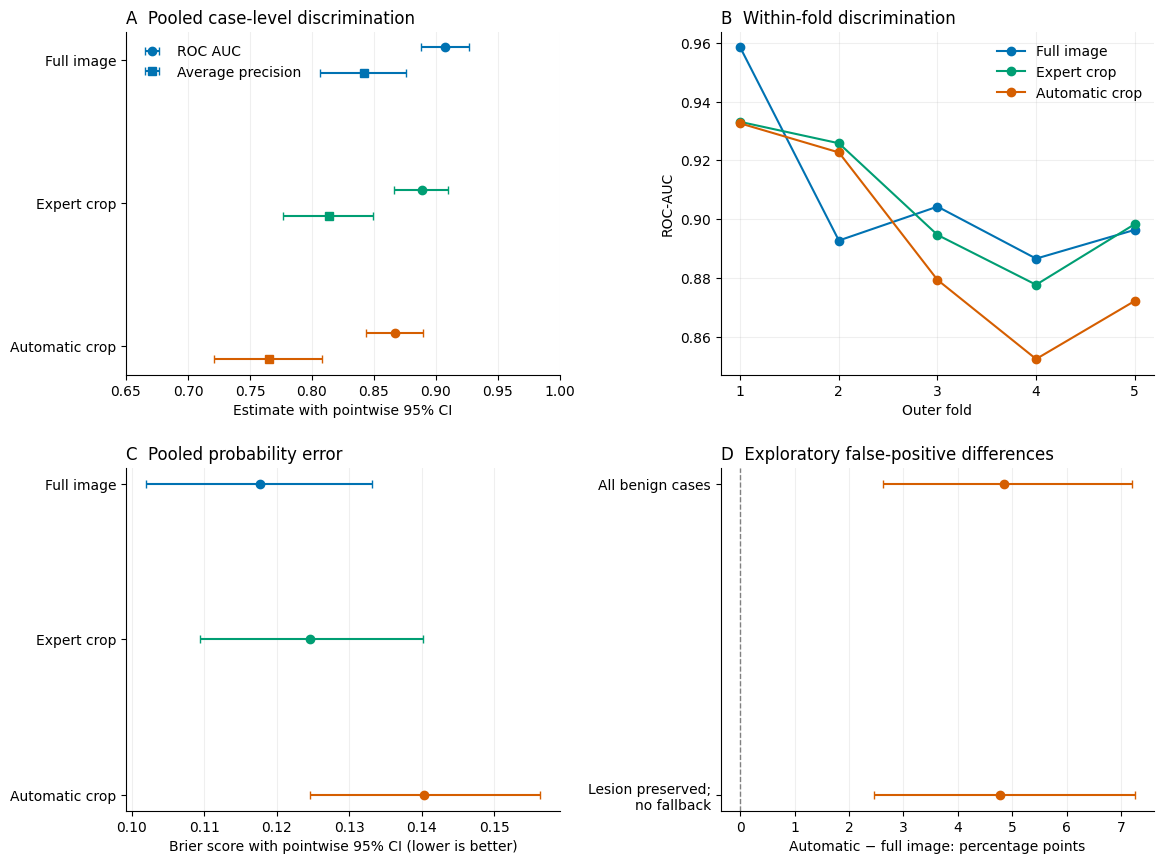


TABLE 1 — POOLED PERFORMANCE (95% CI)


Metric,ROC_AUC,Average_precision,Balanced_accuracy_at_0.5,Brier_score
Full image,0.9071 (0.8876–0.9264),0.8421 (0.8061–0.8761),0.8172 (0.7917–0.8420),0.1176 (0.1019–0.1331)
Expert crop,0.8885 (0.8659–0.9096),0.8140 (0.7768–0.8491),0.8044 (0.7780–0.8296),0.1246 (0.1095–0.1401)
Automatic crop,0.8666 (0.8437–0.8897),0.7652 (0.7210–0.8078),0.7900 (0.7630–0.8166),0.1403 (0.1245–0.1563)



Figure saved as PNG, PDF, and SVG.
Tables and figure caption saved: /content/drive/MyDrive/BUSBRA_Research/results/publication
No training or inference performed.


In [3]:
# CELL 69 — Publication figure and evidence tables
# Saved CSVs only. No training, inference, or image reading.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
COMPARISON_DIR = PROJECT_ROOT / "results" / "three_model_comparison"
ERROR_DIR = PROJECT_ROOT / "results" / "error_analysis"
PUBLICATION_DIR = PROJECT_ROOT / "results" / "publication"
PUBLICATION_DIR.mkdir(parents=True, exist_ok=True)

metrics = pd.read_csv(COMPARISON_DIR / "pooled_metrics_with_ci.csv")
paired = pd.read_csv(COMPARISON_DIR / "pooled_paired_differences.csv")
class_results = pd.read_csv(
    ERROR_DIR / "class_specific_paired_differences.csv"
)
matched = pd.read_csv(
    COMPARISON_DIR / "matched_case_predictions.csv",
    dtype={"Case": str},
)

assert len(matched) == 1064 and matched["Case"].is_unique

models = ["Full_image", "Expert_crop", "Automatic_crop"]
labels = {
    "Full_image": "Full image",
    "Expert_crop": "Expert crop",
    "Automatic_crop": "Automatic crop",
}
colors = {
    "Full_image": "#0072B2",
    "Expert_crop": "#009E73",
    "Automatic_crop": "#D55E00",
}

# Recompute fold metrics from matched predictions for the figure.
from sklearn.metrics import roc_auc_score, average_precision_score

fold_rows = []
for fold, group in matched.groupby("Outer_fold"):
    for model in models:
        fold_rows.append({
            "Outer_fold": int(fold),
            "Model": model,
            "ROC_AUC": roc_auc_score(group["Label"], group[model]),
            "Average_precision": average_precision_score(
                group["Label"], group[model]
            ),
        })
fold_metrics = pd.DataFrame(fold_rows)

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
}):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    # A: pooled discrimination with paired-case bootstrap intervals.
    ax = axes[0, 0]
    positions = np.arange(len(models))
    for metric, offset, marker in (
        ("ROC_AUC", -0.09, "o"),
        ("Average_precision", 0.09, "s"),
    ):
        table = metrics.loc[metrics["Metric"].eq(metric)].set_index("Model")
        for j, model in enumerate(models):
            row = table.loc[model]
            ax.errorbar(
                row["Estimate"], positions[j] + offset,
                xerr=np.array([[
                    row["Estimate"] - row["CI_95_lower"],
                    row["CI_95_upper"] - row["Estimate"],
                ]]).T,
                fmt=marker, color=colors[model], capsize=3,
                label=metric.replace("_", " ") if j == 0 else None,
            )
    ax.set_yticks(positions, [labels[m] for m in models])
    ax.invert_yaxis()
    ax.set_xlim(0.65, 1.0)
    ax.set_xlabel("Estimate with pointwise 95% CI")
    ax.set_title("A  Pooled case-level discrimination", loc="left")
    ax.legend(frameon=False)
    ax.grid(axis="x", alpha=0.2)

    # B: fold-specific AUC.
    ax = axes[0, 1]
    for model in models:
        table = fold_metrics.loc[fold_metrics["Model"].eq(model)]
        ax.plot(
            table["Outer_fold"], table["ROC_AUC"],
            marker="o", color=colors[model], label=labels[model],
        )
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("Outer fold")
    ax.set_ylabel("ROC-AUC")
    ax.set_title("B  Within-fold discrimination", loc="left")
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)

    # C: pooled Brier score.
    ax = axes[1, 0]
    table = metrics.loc[metrics["Metric"].eq("Brier_score")].set_index("Model")
    for j, model in enumerate(models):
        row = table.loc[model]
        ax.errorbar(
            row["Estimate"], j,
            xerr=np.array([[
                row["Estimate"] - row["CI_95_lower"],
                row["CI_95_upper"] - row["Estimate"],
            ]]).T,
            fmt="o", color=colors[model], capsize=3,
        )
    ax.set_yticks(positions, [labels[m] for m in models])
    ax.invert_yaxis()
    ax.set_xlabel("Brier score with pointwise 95% CI (lower is better)")
    ax.set_title("C  Pooled probability error", loc="left")
    ax.grid(axis="x", alpha=0.2)

    # D: benign false-positive differences versus full-image classifier.
    ax = axes[1, 1]
    selected = class_results.loc[
        class_results["Diagnosis"].eq("Benign")
        & class_results["Reference"].eq("Full_image")
        & class_results["Metric"].eq("False_positive_rate")
    ].set_index("Subset")
    subset_order = ["All cases", "Lesion preserved; no fallback"]

    for j, subset in enumerate(subset_order):
        row = selected.loc[subset]
        estimate = 100 * row["Difference_auto_minus_reference"]
        ax.errorbar(
            estimate, j,
            xerr=np.array([[
                estimate - 100 * row["CI_95_lower"],
                100 * row["CI_95_upper"] - estimate,
            ]]).T,
            fmt="o", color=colors["Automatic_crop"], capsize=3,
        )
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(
        [0, 1],
        ["All benign cases", "Lesion preserved;\nno fallback"],
    )
    ax.invert_yaxis()
    ax.set_xlabel("Automatic − full image: percentage points")
    ax.set_title("D  Exploratory false-positive differences", loc="left")
    ax.grid(axis="x", alpha=0.2)

    fig.tight_layout(pad=2)
    for extension in ("png", "pdf", "svg"):
        fig.savefig(
            PUBLICATION_DIR / f"figure_1_classifier_comparison.{extension}",
            dpi=300, bbox_inches="tight",
        )
    plt.show()

# Export readable main results table, retaining numeric source separately.
formatted = metrics.copy()
formatted["Estimate_95CI"] = formatted.apply(
    lambda row: (
        f"{row['Estimate']:.4f} "
        f"({row['CI_95_lower']:.4f}–{row['CI_95_upper']:.4f})"
    ),
    axis=1,
)
main_table = formatted.pivot(
    index="Model", columns="Metric", values="Estimate_95CI"
).reindex(models)[[
    "ROC_AUC", "Average_precision",
    "Balanced_accuracy_at_0.5", "Brier_score",
]]
main_table.index = [labels[m] for m in main_table.index]

main_table.to_csv(PUBLICATION_DIR / "table_1_pooled_performance.csv")
paired.to_csv(PUBLICATION_DIR / "table_2_paired_differences.csv", index=False)
class_results.to_csv(
    PUBLICATION_DIR / "table_S1_class_specific_differences.csv", index=False
)
fold_metrics.to_csv(
    PUBLICATION_DIR / "table_S2_fold_discrimination.csv", index=False
)

caption = """Figure 1. Classification performance with full-image,
expert-guided crop, and automatic-crop inputs. (A) Pooled case-level ROC-AUC
and average precision. (B) ROC-AUC within each outer test fold.
(C) Pooled Brier score. (D) Exploratory automatic-minus-full-image
false-positive-rate differences among all benign cases and among benign
cases retaining at least 99% of the expert-marked lesion in every image,
excluding cases with any full-image fallback. Intervals are pointwise
95% percentile intervals from 2,000 paired case-bootstrap samples,
conditional on the fitted models; no multiplicity adjustment was applied.
Classification errors use a fixed probability threshold of 0.5.
Pooled discrimination compares predictions across different fold models.
"""
(PUBLICATION_DIR / "figure_1_caption.txt").write_text(caption)

print("\nTABLE 1 — POOLED PERFORMANCE (95% CI)")
display(main_table)
print("\nFigure saved as PNG, PDF, and SVG.")
print("Tables and figure caption saved:", PUBLICATION_DIR)
print("No training or inference performed.")

In [4]:
# CELL 70 — Audit saved training configurations
# Read-only: no training, inference, or checkpoint loading.

import json
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")

families = (
    "full_image_resnet18",
    "expert_crop_resnet18",
    "automatic_crop_resnet18",
    "segmentation_resnet18_unet",
)

configs = {}
missing = []

for family in families:
    for fold in range(1, 6):
        path = (
            PROJECT_ROOT / "models" / family
            / f"fold_{fold}" / "training_config.json"
        )
        if path.exists():
            configs[(family, fold)] = json.loads(path.read_text())
        else:
            missing.append(str(path))

print("CONFIGURATION AVAILABILITY")
for family in families:
    count = sum((family, fold) in configs for fold in range(1, 6))
    print(f"{family}: {count}/5")

if missing:
    print("\nMissing configuration files:")
    for path in missing:
        print(path)

def encode(value):
    return json.dumps(value, sort_keys=True, ensure_ascii=False)

for family in families:
    available = {
        fold: configs[(family, fold)]
        for fold in range(1, 6)
        if (family, fold) in configs
    }
    if not available:
        continue

    print(f"\n{'=' * 72}\n{family}\n{'=' * 72}")

    keys = sorted(set().union(*(config.keys() for config in available.values())))
    common = {}
    varying = []

    for key in keys:
        values = {
            fold: encode(config[key]) if key in config else "<MISSING>"
            for fold, config in available.items()
        }
        if len(set(values.values())) == 1:
            common[key] = next(iter(values.values()))
        else:
            varying.append({"Field": key, **{
                f"Fold_{fold}": value for fold, value in values.items()
            }})

    print("\nCommon configuration fields:")
    for key, value in common.items():
        print(f"  {key}: {value}")

    print("\nFields differing across folds:")
    if varying:
        display(pd.DataFrame(varying))
    else:
        print("None.")

# Compare classifier settings, retaining input-specific differences.
print("\nCLASSIFIER CONFIGURATION COMPARISON — FOLD 1")
classifier_families = families[:3]
available = {
    family: configs[(family, 1)]
    for family in classifier_families
    if (family, 1) in configs
}
if available:
    keys = sorted(set().union(*(config.keys() for config in available.values())))
    differences = []
    for key in keys:
        values = {
            family: encode(config[key]) if key in config else "<MISSING>"
            for family, config in available.items()
        }
        if len(set(values.values())) > 1:
            differences.append({"Field": key, **values})
    if differences:
        display(pd.DataFrame(differences))
    else:
        print("No differences recorded.")

print("\nINNER SEGMENTATION CONFIGURATIONS")
inner_configs = []
for outer_fold in range(1, 6):
    for inner_fold in range(1, 4):
        path = (
            PROJECT_ROOT / "models" / "segmentation_crossfit"
            / f"outer_fold_{outer_fold}" / f"inner_fold_{inner_fold}"
            / "training_config.json"
        )
        if path.exists():
            config = json.loads(path.read_text())
            inner_configs.append((outer_fold, inner_fold, config))
        else:
            print("MISSING:", path)

print(f"Found: {len(inner_configs)}/15")
if inner_configs:
    keys = sorted(set().union(*(c.keys() for _, _, c in inner_configs)))
    for key in keys:
        if key in ("outer_fold", "inner_fold"):
            continue
        values = {
            encode(c[key]) if key in c else "<MISSING>"
            for _, _, c in inner_configs
        }
        if len(values) == 1:
            print(f"  {key}: {next(iter(values))}")
        else:
            print(f"\n  VARYING FIELD: {key}")
            for outer, inner, config in inner_configs:
                value = encode(config[key]) if key in config else "<MISSING>"
                print(f"    Outer {outer}, inner {inner}: {value}")

print("\nConfiguration inspection complete. No files changed.")
print("Saved settings document intent; code consistency requires a separate check.")

CONFIGURATION AVAILABILITY
full_image_resnet18: 5/5
expert_crop_resnet18: 5/5
automatic_crop_resnet18: 5/5
segmentation_resnet18_unet: 5/5

full_image_resnet18

Common configuration fields:
  augmentation: "Paired horizontal flip, probability 0.5"
  batch_size: 16
  case_prediction: "Mean image probability within case"
  case_weighting: "Each image weighted by inverse images per training case"
  diagnostic_threshold: 0.5
  early_stopping_patience: 7
  gradient_clip_norm: 1.0
  image_size: 256
  learning_rate: 0.0001
  loss: "Unweighted BCEWithLogitsLoss"
  max_epochs: 30
  model: "ResNet18"
  seed: 2026
  selection_metric: "Validation case-level ROC-AUC"
  weight_decay: 0.0001
  weights: "ImageNet1K_V1"

Fields differing across folds:


,Field,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,outer_fold,1,2,3,4,5



expert_crop_resnet18

Common configuration fields:
  augmentation: "Paired horizontal flip, probability 0.5"
  batch_size: 16
  case_prediction: "Mean image probability within case"
  case_weighting: "Each image weighted by inverse images per training case"
  crop_margin_per_side: 0.2
  diagnostic_threshold: 0.5
  early_stopping_patience: 7
  empty_mask_policy: "Full-image fallback"
  gradient_clip_norm: 1.0
  image_size: 256
  input_mode: "Expert-mask bounding-box crop"
  learning_rate: 0.0001
  loss: "Unweighted BCEWithLogitsLoss"
  max_epochs: 30
  model: "ResNet18"
  seed: 2026
  selection_metric: "Validation case-level ROC-AUC"
  weight_decay: 0.0001
  weights: "ImageNet1K_V1"

Fields differing across folds:


,Field,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,outer_fold,1,2,3,4,5



automatic_crop_resnet18

Common configuration fields:
  augmentation: "Paired horizontal flip, probability 0.5"
  batch_size: 16
  case_prediction: "Mean image probability within case"
  case_weighting: "Each image weighted by inverse images per training case"
  crop_margin_per_side: 0.2
  diagnostic_threshold: 0.5
  early_stopping_patience: 7
  empty_mask_policy: "Full-image fallback"
  evaluation_mask_source: "Outer-fold segmenter"
  gradient_clip_norm: 1.0
  image_size: 256
  input_mode: "Predicted-mask bounding-box crop"
  learning_rate: 0.0001
  loss: "Unweighted BCEWithLogitsLoss"
  max_epochs: 30
  model: "ResNet18"
  seed: 2026
  segmentation_threshold: 0.5
  selection_metric: "Validation case-level ROC-AUC"
  training_mask_source: "Three case-separated inner segmenters"
  weight_decay: 0.0001
  weights: "ImageNet1K_V1"

Fields differing across folds:


,Field,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,outer_fold,1,2,3,4,5



segmentation_resnet18_unet

Common configuration fields:
  architecture: "ResNet18UNet"
  augmentation: "Paired horizontal flip, probability 0.5"
  batch_size: 8
  case_weighting: "Inverse training images per case, normalised to mean 1"
  early_stopping_patience: 8
  encoder_weights: "ImageNet1K_V1"
  gradient_clip_norm: 1.0
  image_size: 256
  input: "Full grayscale image"
  learning_rate: 0.0001
  loss: "0.5 * pixel_mean_BCE + 0.5 * soft_Dice_loss"
  max_epochs: 40
  metric_aggregation: "Mean image metric per case, then mean across cases"
  partition_source: "Existing saved case-separated partitions"
  postprocessing: "None"
  prediction_threshold: 0.5
  resize: "Aspect-ratio-preserving resize with centre padding"
  seed: 2026
  selection_metric: "Validation mean case Dice at threshold 0.5"
  target: "Expert binary lesion mask"
  weight_decay: 0.0001

Fields differing across folds:


,Field,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,outer_fold,1,2,3,4,5



CLASSIFIER CONFIGURATION COMPARISON — FOLD 1


,Field,full_image_resnet18,expert_crop_resnet18,automatic_crop_resnet18
0,crop_margin_per_side,<MISSING>,0.2,0.2
1,empty_mask_policy,<MISSING>,"""Full-image fallback""","""Full-image fallback"""
2,evaluation_mask_source,<MISSING>,<MISSING>,"""Outer-fold segmenter"""
3,input_mode,<MISSING>,"""Expert-mask bounding-box crop""","""Predicted-mask bounding-box crop"""
4,segmentation_threshold,<MISSING>,<MISSING>,0.5
5,training_mask_source,<MISSING>,<MISSING>,"""Three case-separated inner segmenters"""



INNER SEGMENTATION CONFIGURATIONS
Found: 15/15
  architecture: "ResNet18UNet"
  augmentation: "Paired horizontal flip, probability 0.5"
  batch_size: 8
  case_weighting: "Inverse training images per case, normalised to mean 1"
  early_stopping_patience: 8
  encoder_weights: "ImageNet1K_V1"
  gradient_clip_norm: 1.0
  image_size: 256
  input: "Full grayscale image"
  learning_rate: 0.0001
  loss: "0.5 * pixel_mean_BCE + 0.5 * soft_Dice_loss"
  max_epochs: 40
  metric_aggregation: "Mean image metric per case, then mean across cases"
  partition_source: "Saved inner case-separated cross-fitting partitions"
  postprocessing: "None"
  prediction_threshold: 0.5
  resize: "Aspect-ratio-preserving resize with centre padding"
  seed: 2026
  selection_metric: "Validation mean case Dice at threshold 0.5"
  target: "Expert binary lesion mask"
  weight_decay: 0.0001

Configuration inspection complete. No files changed.
Saved settings document intent; code consistency requires a separate check.


In [5]:
# CELL 71 — Audit partitions and automatic-mask assignments
# CSV files only. No training, inference, or image reading.

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA_Research")
audit_rows = []
test_case_sets = []
test_image_sets = []

def case_set(table):
    return set(table["Case"].astype(str))

for fold in range(1, 6):
    outer = pd.read_csv(
        PROJECT_ROOT / "splits" / f"outer_fold_{fold}.csv",
        dtype={"ID": str, "Case": str},
    )
    assert outer["ID"].is_unique
    assert len(outer) == 1875
    assert set(outer["Split"]) == {"train", "validation", "test"}
    assert outer.groupby("Case")["Split"].nunique().eq(1).all()
    assert outer.groupby("Case")["Label"].nunique().eq(1).all()

    splits = {
        split: outer.loc[outer["Split"].eq(split)].copy()
        for split in ("train", "validation", "test")
    }
    for a, b in (("train", "validation"), ("train", "test"),
                 ("validation", "test")):
        assert case_set(splits[a]).isdisjoint(case_set(splits[b]))

    train = splits["train"]
    excluded = case_set(splits["validation"]) | case_set(splits["test"])
    prediction_assignments = []

    for inner in (1, 2, 3):
        assignment = pd.read_csv(
            PROJECT_ROOT / "splits" / f"segmentation_crossfit_outer_{fold}"
            / f"inner_fold_{inner}.csv",
            dtype={"ID": str, "Case": str},
        )
        assert assignment["ID"].is_unique
        assert set(assignment["ID"]) == set(train["ID"])
        assert set(assignment["Segmentation_role"]) == {
            "fit", "selection", "predict"
        }
        assert assignment.groupby("Case")[
            "Segmentation_role"
        ].nunique().eq(1).all()
        assert case_set(assignment).isdisjoint(excluded)

        matched = assignment[["ID", "Case"]].merge(
            train[["ID", "Case"]], on="ID",
            suffixes=("_inner", "_outer"), validate="one_to_one",
        )
        assert matched["Case_inner"].eq(matched["Case_outer"]).all()

        predicted = assignment.loc[
            assignment["Segmentation_role"].eq("predict"),
            ["ID", "Case"],
        ].copy()
        predicted["Inner_fold"] = inner
        prediction_assignments.append(predicted)

    expected_masks = pd.concat(prediction_assignments, ignore_index=True)
    assert expected_masks["ID"].is_unique
    assert set(expected_masks["ID"]) == set(train["ID"])
    assert expected_masks.groupby("Case")["Inner_fold"].nunique().eq(1).all()

    mask_root = PROJECT_ROOT / "predicted_masks" / f"outer_fold_{fold}"
    training_masks = pd.read_csv(
        mask_root / "train_mask_manifest.csv",
        dtype={"ID": str, "Case": str},
    )
    assert training_masks["ID"].is_unique
    assert set(training_masks["ID"]) == set(train["ID"])
    assert training_masks["Split"].eq("train").all()
    assert training_masks["Outer_fold"].eq(fold).all()
    assert training_masks["Mask_path"].notna().all()

    matched = expected_masks.merge(
        training_masks[["ID", "Case", "Inner_fold"]],
        on="ID", suffixes=("_expected", "_saved"),
        validate="one_to_one",
    )
    for column in ("Case", "Inner_fold"):
        assert matched[f"{column}_expected"].eq(
            matched[f"{column}_saved"]
        ).all()

    evaluation_masks = pd.read_csv(
        mask_root / "mask_manifest.csv",
        dtype={"ID": str, "Case": str},
    )
    assert evaluation_masks["ID"].is_unique
    assert set(evaluation_masks["Split"]) == {"validation", "test"}
    assert evaluation_masks["Outer_fold"].eq(fold).all()

    for split in ("validation", "test"):
        masks = evaluation_masks.loc[
            evaluation_masks["Split"].eq(split)
        ]
        assert set(masks["ID"]) == set(splits[split]["ID"])
        matched = masks[["ID", "Case"]].merge(
            splits[split][["ID", "Case"]],
            on="ID", suffixes=("_mask", "_outer"),
            validate="one_to_one",
        )
        assert matched["Case_mask"].eq(matched["Case_outer"]).all()
        assert masks["Mask_path"].notna().all()

    test_case_sets.append(case_set(splits["test"]))
    test_image_sets.append(set(splits["test"]["ID"]))

    audit_rows.append({
        "Outer_fold": fold,
        "Training_cases": train["Case"].nunique(),
        "Validation_cases": splits["validation"]["Case"].nunique(),
        "Test_cases": splits["test"]["Case"].nunique(),
        "Cross_fitted_training_images": len(training_masks),
        "Validation_mask_images": len(splits["validation"]),
        "Test_mask_images": len(splits["test"]),
        "Partition_and_assignment_checks": "PASS",
    })

for i in range(5):
    for j in range(i + 1, 5):
        assert test_case_sets[i].isdisjoint(test_case_sets[j])
        assert test_image_sets[i].isdisjoint(test_image_sets[j])

assert len(set.union(*test_case_sets)) == 1064
assert len(set.union(*test_image_sets)) == 1875

audit = pd.DataFrame(audit_rows)
destination = PROJECT_ROOT / "results" / "publication" / "partition_audit.csv"
destination.parent.mkdir(parents=True, exist_ok=True)
audit.to_csv(destination, index=False)

display(audit)
print("\nEvery case and image appears in exactly one outer test fold.")
print("Every outer-training image has exactly one inner prediction assignment.")
print("Saved mask manifests match the assigned images, cases, and folds.")
print("This checks recorded assignments; model-code provenance remains separate.")
print("Saved:", destination)
print("No training or inference performed.")

,Outer_fold,Training_cases,Validation_cases,Test_cases,Cross_fitted_training_images,Validation_mask_images,Test_mask_images,Partition_and_assignment_checks
0,1,681,171,212,1186,313,376,PASS
1,2,680,171,213,1183,307,385,PASS
2,3,680,171,213,1192,317,366,PASS
3,4,680,170,214,1205,305,365,PASS
4,5,681,171,212,1192,300,383,PASS



Every case and image appears in exactly one outer test fold.
Every outer-training image has exactly one inner prediction assignment.
Saved mask manifests match the assigned images, cases, and folds.
This checks recorded assignments; model-code provenance remains separate.
Saved: /content/drive/MyDrive/BUSBRA_Research/results/publication/partition_audit.csv
No training or inference performed.


In [8]:
# CELL 72 — Locate saved implementation sources
# Read-only. No training or inference.

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/BUSBRA")

sources = sorted(
    path
    for path in PROJECT_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in {".ipynb", ".py"}
)

print("IMPLEMENTATION SOURCES IN PROJECT FOLDER")
if sources:
    for path in sources:
        print(path)
else:
    print("No notebook or Python files found in BUSBRA.")

# Colab notebooks may be saved outside the research folder.
colab_folder = Path("/content/drive/MyDrive/Colab Notebooks")
print("\nNOTEBOOKS IN COLAB NOTEBOOKS FOLDER")
if colab_folder.exists():
    for path in sorted(colab_folder.glob("*.ipynb")):
        print(path.name)
else:
    print("Folder not found.")

print("\nSource discovery complete. No files changed.")

IMPLEMENTATION SOURCES IN PROJECT FOLDER
/content/drive/MyDrive/BUSBRA/AI_Health.ipynb

NOTEBOOKS IN COLAB NOTEBOOKS FOLDER

Source discovery complete. No files changed.


In [9]:
# CELL 73 — Inspect implementation source in the saved notebook
# Read-only. Does not execute notebook code.

import json
import re
from pathlib import Path

NOTEBOOK_PATH = Path("/content/drive/MyDrive/BUSBRA/AI_Health.ipynb")
assert NOTEBOOK_PATH.exists(), f"Notebook not found: {NOTEBOOK_PATH}"

notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
code_cells = [
    (index + 1, "".join(cell.get("source", [])))
    for index, cell in enumerate(notebook["cells"])
    if cell.get("cell_type") == "code"
]

# Print relevant definitions, including repeated versions after recovery.
definition_patterns = {
    "Resize and padding": r"^\s*def\s+resize_pair\s*\(",
    "Automatic-crop dataset": r"^\s*class\s+AutomaticCropDataset\b",
    "Expert-crop dataset": r"^\s*class\s+\w*(?:ExpertCrop|CropDataset)\w*\b",
    "Classifier architecture": r"^\s*class\s+FullImageClassifier\b",
    "Segmentation architecture": r"^\s*class\s+ResNet18UNet\b",
}

def definition_blocks(source, pattern):
    lines = source.splitlines()
    blocks = []
    for start, line in enumerate(lines):
        if not re.search(pattern, line):
            continue
        # Include the class/function body until the next top-level statement.
        end = start + 1
        while end < len(lines):
            candidate = lines[end]
            if candidate.strip() and not candidate.startswith((" ", "\t", "#")):
                break
            end += 1
        blocks.append("\n".join(lines[start:end]))
    return blocks

print("NOTEBOOK:", NOTEBOOK_PATH)
print("Code cells:", len(code_cells))
print("Cell indices below are notebook positions, including markdown cells.")

for category, pattern in definition_patterns.items():
    print(f"\n{'=' * 72}\n{category}\n{'=' * 72}")
    found = False
    for position, source in code_cells:
        blocks = definition_blocks(source, pattern)
        for block in blocks:
            found = True
            print(f"\n--- Notebook position {position} ---")
            print(block)
    if not found:
        print("No matching definition found.")

# Extract surrounding lines for loss weighting and recovery logic.
print("\n" + "=" * 72)
print("TRAINING LOSS, WEIGHTING, AND CHECKPOINT RECOVERY EXCERPTS")
print("=" * 72)

training_patterns = (
    r"binary_cross_entropy_with_logits",
    r"BCEWithLogitsLoss",
    r"image_weights\s*/=",
    r"classifier_id_weights\s*=",
    r"load_state_dict\(.*optimizer",
    r"classifier_optimizer\.load_state_dict",
)

for position, source in code_cells:
    lines = source.splitlines()
    hits = [
        index for index, line in enumerate(lines)
        if any(re.search(pattern, line) for pattern in training_patterns)
    ]
    if not hits:
        continue

    selected_lines = set()
    for index in hits:
        selected_lines.update(
            range(max(0, index - 5), min(len(lines), index + 9))
        )

    print(f"\n--- Notebook position {position} ---")
    previous = -2
    for index in sorted(selected_lines):
        if index > previous + 1:
            print("...")
        print(f"{index + 1:4d}: {lines[index]}")
        previous = index

print("\nInspection complete. Notebook code was not executed.")
print("No files changed.")

NOTEBOOK: /content/drive/MyDrive/BUSBRA/AI_Health.ipynb
Code cells: 93
Cell indices below are notebook positions, including markdown cells.

Resize and padding

--- Notebook position 13 ---
def resize_pair(image, mask, size=IMAGE_SIZE):
    """Resize image and mask identically, then centre-pad to a square."""
    if image.size != mask.size:
        raise ValueError("Image and mask dimensions differ.")

    width, height = image.size
    scale = size / max(width, height)
    new_width = max(1, min(size, round(width * scale)))
    new_height = max(1, min(size, round(height * scale)))

    image_resized = image.convert("L").resize(
        (new_width, new_height), Image.Resampling.BILINEAR
    )
    mask_resized = mask.convert("L").resize(
        (new_width, new_height), Image.Resampling.NEAREST
    )

    left = (size - new_width) // 2
    top = (size - new_height) // 2

    image_canvas = Image.new("L", (size, size), color=0)
    mask_canvas = Image.new("L", (size, size), color=0)
    

In [10]:
# CELL 74 — Inspect crop helper and original loss weighting
# Read-only. Does not execute notebook cells.

import ast
import json
from pathlib import Path

NOTEBOOK_PATH = Path("/content/drive/MyDrive/BUSBRA/AI_Health.ipynb")
notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))

targets = {"crop_from_mask", "training_loss"}
found = set()

for position, cell in enumerate(notebook["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    try:
        tree = ast.parse(source)
    except SyntaxError:
        # Ignore Colab magic/shell lines for parsing only.
        cleaned = "\n".join(
            line if not line.lstrip().startswith(("%", "!")) else ""
            for line in source.splitlines()
        )
        try:
            tree = ast.parse(cleaned)
        except SyntaxError:
            continue

    lines = source.splitlines()
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in targets:
                found.add(node.name)
                print(f"\n{'=' * 72}")
                print(f"{node.name} — notebook position {position}")
                print("=" * 72)
                print("\n".join(lines[node.lineno - 1:node.end_lineno]))

print("\nDefinitions found:", sorted(found))
print("Definitions missing:", sorted(targets - found))
print("No notebook cells executed. No files changed.")


training_loss — notebook position 16
def training_loss(logits, labels, image_ids):
    weights = torch.tensor(
        [train_id_weights[str(image_id)] for image_id in image_ids],
        dtype=logits.dtype,
        device=logits.device,
    )
    return (criterion(logits, labels) * weights).mean()

crop_from_mask — notebook position 22
def crop_from_mask(image, mask, margin=CROP_MARGIN):
    """
    Crop to the foreground bounding box, expanded on each side by
    margin × bounding-box width/height. Empty masks use the full image.
    Coordinates refer to original image pixels.
    """
    if image.size != mask.size:
        raise ValueError("Image and mask dimensions differ.")

    binary_mask = np.asarray(mask.convert("L")) > 0
    ys, xs = np.where(binary_mask)

    if len(xs) == 0:
        return image.copy(), mask.copy(), {
            "box": (0, 0, image.width, image.height),
            "fallback": True,
        }

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int

In [ ]:
# CELL 43 — verify the active inner segmentation checkpoint
import json
import numpy as np
import torch

selected = torch.load(
    SEG_BEST_PATH, map_location="cpu", weights_only=False
)
assert selected["config"] == segmentation_config
assert selected["config"]["outer_fold"] == CROSSFIT_OUTER_FOLD
assert selected["config"]["inner_fold"] == INNER_FOLD

segmentation_model.load_state_dict(selected["model_state"], strict=True)
segmentation_model.to(DEVICE)

metrics, image_scores, case_scores = evaluate_segmentation(
    segmentation_model, segmentation_loaders["validation"]
)
assert np.isclose(
    metrics["case_dice"], selected["best_dice"],
    atol=1e-6, rtol=0,
), "Validation Dice does not match the checkpoint."

report = {
    "selected_epoch": int(selected["epoch"]),
    "outer_fold": CROSSFIT_OUTER_FOLD,
    "inner_fold": INNER_FOLD,
    **metrics,
}
image_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_image_scores.csv", index=False
)
case_scores.to_csv(
    SEGMENTATION_RUN_DIR / "validation_case_scores.csv", index=False
)
with (SEGMENTATION_RUN_DIR / "selected_validation_metrics.json").open("w") as f:
    json.dump(report, f, indent=2)

print("SELECTED CHECKPOINT — VERIFIED")
print(json.dumps(report, indent=2))
print("\nValidation scores saved. No training performed.")
print("Inner prediction partition remains unused by this cell.")

SELECTED CHECKPOINT — VERIFIED
{
  "selected_epoch": 18,
  "outer_fold": 5,
  "inner_fold": 2,
  "case_dice": 0.8924430732194406,
  "case_iou": 0.8190213218065885,
  "empty_prediction_images": 0,
  "cases": 91
}

Validation scores saved. No training performed.
Inner prediction partition remains unused by this cell.


In [ ]:
# CELL 44 — generate cross-fitted training masks for the active outer fold
import hashlib
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.nn import functional as F
from tqdm.auto import tqdm

CROSSFIT_OUTER_FOLD = 4
assert torch.cuda.is_available()
DEVICE = torch.device("cuda")

fold = CROSSFIT_OUTER_FOLD
output_dir = PROJECT_ROOT / "predicted_masks" / f"outer_fold_{fold}"
(output_dir / "train").mkdir(parents=True, exist_ok=True)

outer_table = pd.read_csv(
    PROJECT_ROOT / "splits" / f"outer_fold_{fold}.csv",
    dtype={"ID": str, "Case": str},
)
outer_train = outer_table.loc[outer_table["Split"].eq("train")]
expected_ids = set(outer_train["ID"])
excluded_cases = set(
    outer_table.loc[~outer_table["Split"].eq("train"), "Case"]
)

records, provenance = [], []

with torch.inference_mode():
    for inner_fold in (1, 2, 3):
        table = pd.read_csv(
            PROJECT_ROOT / "splits"
            / f"segmentation_crossfit_outer_{fold}"
            / f"inner_fold_{inner_fold}.csv",
            dtype={"ID": str, "Case": str},
        )
        roles = {
            role: set(table.loc[table["Segmentation_role"].eq(role), "Case"])
            for role in ("fit", "selection", "predict")
        }
        assert roles["predict"].isdisjoint(roles["fit"])
        assert roles["predict"].isdisjoint(roles["selection"])
        assert set(table["Case"]).isdisjoint(excluded_cases)
        assert set(table["ID"]) == expected_ids

        checkpoint_path = (
            PROJECT_ROOT / "models" / "segmentation_crossfit"
            / f"outer_fold_{fold}" / f"inner_fold_{inner_fold}" / "best.pt"
        )
        saved = torch.load(
            checkpoint_path, map_location="cpu", weights_only=False
        )
        assert saved["config"]["outer_fold"] == fold
        assert saved["config"]["inner_fold"] == inner_fold
        assert saved["config"]["prediction_threshold"] == 0.5

        model = ResNet18UNet().to(DEVICE)
        model.load_state_dict(saved["model_state"], strict=True)
        model.eval()

        prediction_table = table.loc[
            table["Segmentation_role"].eq("predict")
        ]
        for row in tqdm(
            prediction_table.to_dict("records"),
            desc=f"Inner fold {inner_fold}",
        ):
            with Image.open(
                LOCAL_DATA_ROOT / row["Image_relative_path"]
            ) as f:
                image = f.convert("L")

            width, height = image.size
            image_array, _, geometry = resize_pair(
                image, Image.new("L", image.size, 0),
                saved["config"]["image_size"],
            )
            tensor = torch.from_numpy(
                image_array.copy()
            )[None, None].to(DEVICE)
            probabilities = model(tensor).sigmoid()

            left, top = geometry["left_padding"], geometry["top_padding"]
            rw, rh = geometry["resized_width"], geometry["resized_height"]
            probabilities = probabilities[:, :, top:top + rh, left:left + rw]
            probabilities = F.interpolate(
                probabilities, size=(height, width),
                mode="bilinear", align_corners=False,
            )
            binary = (
                probabilities[0, 0] >= 0.5
            ).cpu().numpy().astype(np.uint8) * 255

            destination = output_dir / "train" / f"{row['ID']}.png"
            temporary = destination.with_suffix(".tmp.png")
            Image.fromarray(binary).save(temporary)
            temporary.replace(destination)

            records.append({
                "ID": row["ID"], "Case": row["Case"], "Split": "train",
                "Outer_fold": fold, "Inner_fold": inner_fold,
                "Mask_path": str(destination),
                "Width": width, "Height": height,
                "Empty_prediction": int(not binary.any()),
            })

        digest = hashlib.sha256()
        with checkpoint_path.open("rb") as f:
            for block in iter(lambda: f.read(1024 * 1024), b""):
                digest.update(block)

        provenance.append({
            "inner_fold": inner_fold,
            "checkpoint": str(checkpoint_path),
            "checkpoint_sha256": digest.hexdigest(),
            "selected_epoch": int(saved["epoch"]),
            **{f"{role}_cases": sorted(cases) for role, cases in roles.items()},
        })
        del model, saved
        torch.cuda.empty_cache()

train_mask_manifest = pd.DataFrame(records)
assert train_mask_manifest["ID"].is_unique
assert set(train_mask_manifest["ID"]) == expected_ids
assert len(train_mask_manifest) == len(outer_train)
assert train_mask_manifest["Case"].nunique() == outer_train["Case"].nunique()

train_mask_manifest.to_csv(
    output_dir / "train_mask_manifest.csv", index=False
)
with (output_dir / "train_mask_provenance.json").open("w") as f:
    json.dump({
        "outer_fold": fold,
        "threshold": 0.5,
        "postprocessing": "None",
        "mask_space": "Original image dimensions",
        "expert_masks_read_during_prediction": False,
        "inner_models": provenance,
    }, f, indent=2)

print("\nCROSS-FITTED TRAINING MASKS SAVED")
display(train_mask_manifest.groupby("Inner_fold").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
    Empty_masks=("Empty_prediction", "sum"),
))
print("Total images:", len(train_mask_manifest))
print("Total cases:", train_mask_manifest["Case"].nunique())
print("Output:", output_dir / "train")
print("No classifier training performed.")

Inner fold 1:   0%|          | 0/399 [00:00<?, ?it/s]

Inner fold 2:   0%|          | 0/406 [00:00<?, ?it/s]

Inner fold 3:   0%|          | 0/400 [00:00<?, ?it/s]


CROSS-FITTED TRAINING MASKS SAVED


,Images,Cases,Empty_masks
Inner_fold,,,
1,399,227,3
2,406,227,0
3,400,226,2


Total images: 1205
Total cases: 680
Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_4/train
No classifier training performed.


In [ ]:
# CELL 29 — TRAIN SEGMENTATION MODEL, OUTER FOLD 1

import random
import time
import numpy as np
import pandas as pd
import torch

SEG_BEST_PATH = SEGMENTATION_RUN_DIR / "best.pt"
SEG_LAST_PATH = SEGMENTATION_RUN_DIR / "last.pt"

seg_start_epoch = 1
seg_best_dice = -float("inf")
seg_stale_epochs = 0
seg_history = []

if SEG_LAST_PATH.exists():
    saved = torch.load(
        SEG_LAST_PATH, map_location="cpu", weights_only=False
    )
    assert saved["config"] == SEGMENTATION_CONFIG

    segmentation_model.load_state_dict(saved["model_state"])
    segmentation_optimizer.load_state_dict(saved["optimizer_state"])

    for state in segmentation_optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(DEVICE)

    seg_start_epoch = saved["epoch"] + 1
    seg_best_dice = saved["best_dice"]
    seg_stale_epochs = saved["stale_epochs"]
    seg_history = saved["history"]

    random.setstate(saved["python_rng"])
    np.random.set_state(saved["numpy_rng"])
    torch.set_rng_state(saved["torch_rng"])
    segmentation_generator.set_state(saved["loader_rng"])
    if torch.cuda.is_available():
        torch.cuda.set_rng_state_all(saved["cuda_rng"])

    print(f"Resuming after epoch {saved['epoch']}.")
else:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    segmentation_generator.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    print("Starting segmentation training.")

if seg_stale_epochs >= SEGMENTATION_CONFIG["early_stopping_patience"]:
    print("This run has already reached early stopping.")
else:
    for epoch in range(
        seg_start_epoch, SEGMENTATION_CONFIG["max_epochs"] + 1
    ):
        started = time.perf_counter()
        segmentation_model.train()
        loss_sum = 0.0
        image_count = 0

        for training_batch in segmentation_train_loader:
            images = training_batch["image"].to(
                DEVICE, non_blocking=True
            )
            masks = training_batch["mask"].to(
                DEVICE, non_blocking=True
            )

            segmentation_optimizer.zero_grad(set_to_none=True)
            logits = segmentation_model(images)
            loss = segmentation_loss(
                logits, masks, training_batch["id"]
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite segmentation loss at epoch {epoch}."
                )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                segmentation_model.parameters(),
                SEGMENTATION_CONFIG["gradient_clip_norm"],
                error_if_nonfinite=True,
            )
            segmentation_optimizer.step()

            loss_sum += loss.item() * len(images)
            image_count += len(images)

        val_metrics, _, _ = evaluate_segmentation(
            segmentation_model, segmentation_validation_loader
        )

        improved = val_metrics["case_dice"] > seg_best_dice
        if improved:
            seg_best_dice = val_metrics["case_dice"]
            seg_stale_epochs = 0
        else:
            seg_stale_epochs += 1

        record = {
            "epoch": epoch,
            "train_weighted_loss": loss_sum / image_count,
            **val_metrics,
            "seconds": time.perf_counter() - started,
        }
        seg_history.append(record)

        checkpoint = {
            "epoch": epoch,
            "config": SEGMENTATION_CONFIG,
            "model_state": segmentation_model.state_dict(),
            "optimizer_state": segmentation_optimizer.state_dict(),
            "best_dice": seg_best_dice,
            "stale_epochs": seg_stale_epochs,
            "history": seg_history,
            "python_rng": random.getstate(),
            "numpy_rng": np.random.get_state(),
            "torch_rng": torch.get_rng_state(),
            "loader_rng": segmentation_generator.get_state(),
            "cuda_rng": (
                torch.cuda.get_rng_state_all()
                if torch.cuda.is_available() else None
            ),
        }

        if improved:
            save_checkpoint_atomic(checkpoint, SEG_BEST_PATH)
        save_checkpoint_atomic(checkpoint, SEG_LAST_PATH)

        pd.DataFrame(seg_history).to_csv(
            SEGMENTATION_RUN_DIR / "training_history.csv",
            index=False,
        )

        print(
            f"Epoch {epoch:02d} | "
            f"Loss {record['train_weighted_loss']:.4f} | "
            f"Val Dice {val_metrics['case_dice']:.4f} | "
            f"Val IoU {val_metrics['case_iou']:.4f} | "
            f"Empty {val_metrics['empty_prediction_images']} | "
            f"{record['seconds']:.1f}s"
            + (" | BEST" if improved else ""),
            flush=True,
        )

        if (
            seg_stale_epochs
            >= SEGMENTATION_CONFIG["early_stopping_patience"]
        ):
            print("Early stopping reached.")
            break

print(f"\nBest validation case-level Dice: {seg_best_dice:.4f}")
print("Best checkpoint:", SEG_BEST_PATH)
print("Segmentation outer test partition remains unevaluated.")

NameError: name 'SEGMENTATION_RUN_DIR' is not defined

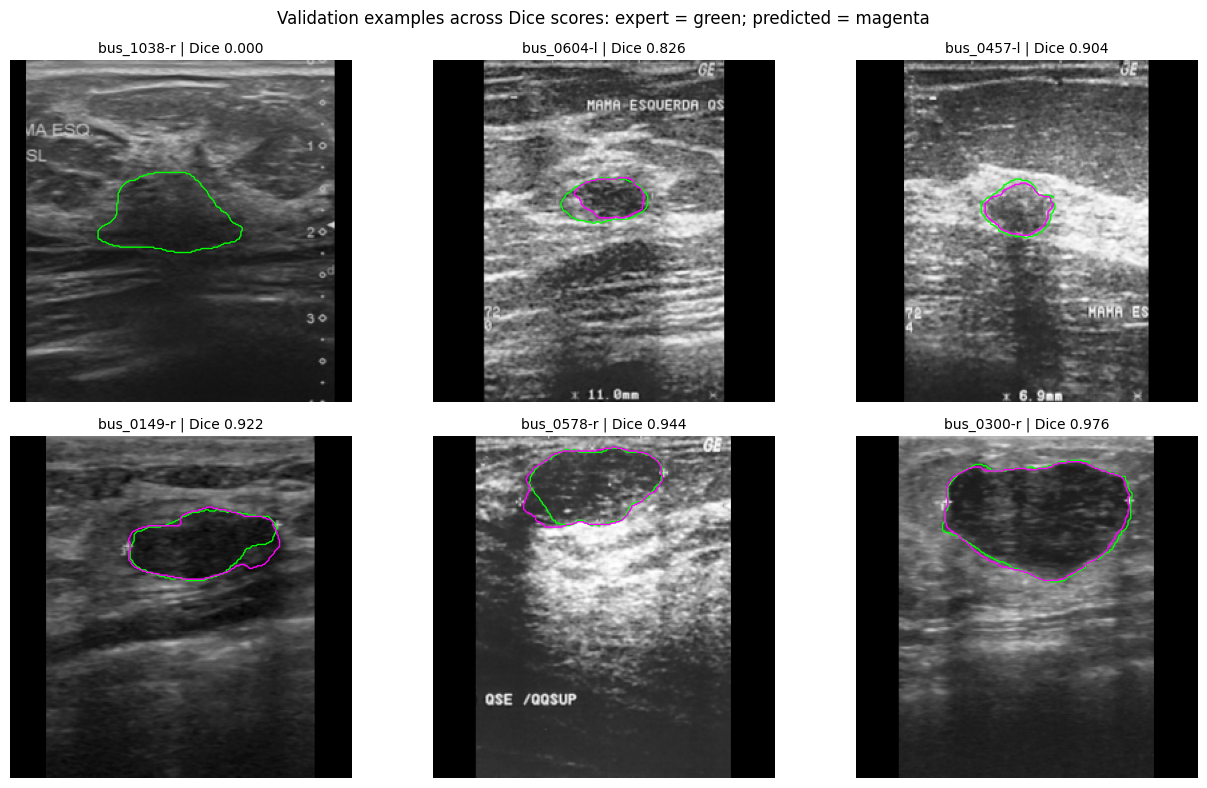

SELECTED SEGMENTATION CHECKPOINT — VERIFIED
{
  "selected_epoch": 21,
  "outer_fold": 2,
  "case_dice": 0.8759337546605132,
  "case_iou": 0.7973056808967968,
  "empty_prediction_images": 1,
  "cases": 91
}

Validation scores and review figure saved.
Examples were selected by validation Dice, not sampled randomly.
Segmentation outer test partition remains unevaluated.


In [ ]:
# CELL 30 — VERIFY SEGMENTATION CHECKPOINT AND REVIEW PREDICTIONS

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

seg_best_checkpoint = torch.load(
    SEG_BEST_PATH, map_location="cpu", weights_only=False
)
assert seg_best_checkpoint["config"] == SEGMENTATION_CONFIG

segmentation_model.load_state_dict(seg_best_checkpoint["model_state"])
segmentation_model.to(DEVICE)
segmentation_model.eval()

seg_val_metrics, seg_val_images, seg_val_cases = evaluate_segmentation(
    segmentation_model, segmentation_validation_loader
)

assert np.isclose(
    seg_val_metrics["case_dice"],
    seg_best_checkpoint["best_dice"],
    atol=1e-6,
), "Restored Dice differs from the saved checkpoint."

seg_val_images.to_csv(
    SEGMENTATION_RUN_DIR / "validation_image_scores.csv", index=False
)
seg_val_cases.to_csv(
    SEGMENTATION_RUN_DIR / "validation_case_scores.csv", index=False
)

seg_selected_result = {
    "selected_epoch": int(seg_best_checkpoint["epoch"]),
    "outer_fold": SEGMENTATION_FOLD,
    **seg_val_metrics,
}
(SEGMENTATION_RUN_DIR / "selected_validation_metrics.json").write_text(
    json.dumps(seg_selected_result, indent=2), encoding="utf-8"
)

# Review examples spread across the validation Dice distribution.
ordered_scores = seg_val_images.sort_values(
    ["Dice", "ID"]
).reset_index(drop=True)
positions = np.linspace(0, len(ordered_scores) - 1, 6).round().astype(int)
review_scores = ordered_scores.iloc[positions]

validation_dataset = segmentation_datasets["validation"]
id_to_index = {
    str(image_id): index
    for index, image_id in enumerate(validation_dataset.table["ID"])
}

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, (_, score_row) in zip(axes.flat, review_scores.iterrows()):
    sample = validation_dataset[id_to_index[score_row["ID"]]]
    image = sample["image"].squeeze(0).numpy()
    target = sample["mask"].squeeze(0).numpy() > 0.5

    with torch.inference_mode():
        probability = torch.sigmoid(
            segmentation_model(sample["image"].unsqueeze(0).to(DEVICE))
        )[0, 0].cpu().numpy()

    prediction = probability >= 0.5

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.contour(target, levels=[0.5], colors=["lime"], linewidths=1)
    if prediction.any() and not prediction.all():
        ax.contour(
            prediction, levels=[0.5], colors=["magenta"], linewidths=1
        )
    ax.set_title(
        f"{score_row['ID']} | Dice {score_row['Dice']:.3f}",
        fontsize=10
    )
    ax.axis("off")

fig.suptitle(
    "Validation examples across Dice scores: expert = green; predicted = magenta"
)
plt.tight_layout()
fig.savefig(
    SEGMENTATION_RUN_DIR / "validation_prediction_review.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

print("SELECTED SEGMENTATION CHECKPOINT — VERIFIED")
print("=" * 70)
print(json.dumps(seg_selected_result, indent=2))
print("\nValidation scores and review figure saved.")
print("Examples were selected by validation Dice, not sampled randomly.")
print("Segmentation outer test partition remains unevaluated.")

In [ ]:
# CELL 31 — FIVE-FOLD OUTER-TEST SEGMENTATION EVALUATION

import json
import pandas as pd
import torch
from torch.utils.data import DataLoader

SEG_MODEL_DIR = PROJECT_ROOT / "models" / "segmentation_resnet18_unet"
SEG_RESULTS_DIR = PROJECT_ROOT / "results" / "segmentation_resnet18_unet"
SEG_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

seg_test_fold_records = []
seg_test_image_tables = []
seg_test_case_tables = []

seg_evaluation_model = ResNet18UNet().to(DEVICE)

for fold in range(1, 6):
    fold_dir = SEG_MODEL_DIR / f"fold_{fold}"
    checkpoint = torch.load(
        fold_dir / "best.pt",
        map_location="cpu",
        weights_only=False,
    )
    saved_config = json.loads(
        (fold_dir / "training_config.json").read_text()
    )

    assert checkpoint["config"] == saved_config
    assert saved_config["outer_fold"] == fold
    assert saved_config["prediction_threshold"] == 0.5
    assert saved_config["postprocessing"] == "None"

    test_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & all_splits["Split"].eq("test")
    ].copy()

    development_table = all_splits.loc[
        all_splits["Evaluation_fold"].eq(fold)
        & ~all_splits["Split"].eq("test")
    ]
    assert set(test_table["Case"]).isdisjoint(
        set(development_table["Case"])
    )

    test_loader = DataLoader(
        BUSBRADataset(test_table, LOCAL_DATA_ROOT, augment=False),
        batch_size=saved_config["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

    seg_evaluation_model.load_state_dict(checkpoint["model_state"])
    metrics, image_scores, case_scores = evaluate_segmentation(
        seg_evaluation_model, test_loader
    )

    assert image_scores["ID"].is_unique
    assert set(image_scores["ID"]) == set(test_table["ID"])

    image_scores["Outer_fold"] = fold
    case_scores["Outer_fold"] = fold

    image_scores.to_csv(
        fold_dir / "test_image_scores.csv", index=False
    )
    case_scores.to_csv(
        fold_dir / "test_case_scores.csv", index=False
    )

    seg_test_image_tables.append(image_scores)
    seg_test_case_tables.append(case_scores)
    seg_test_fold_records.append({
        "Outer_fold": fold,
        "Selected_epoch": int(checkpoint["epoch"]),
        **metrics,
    })

    print(
        f"Fold {fold} | Cases {metrics['cases']} | "
        f"Test Dice {metrics['case_dice']:.4f} | "
        f"IoU {metrics['case_iou']:.4f} | "
        f"Empty {metrics['empty_prediction_images']}",
        flush=True,
    )

seg_oof_images = pd.concat(seg_test_image_tables, ignore_index=True)
seg_oof_cases = pd.concat(seg_test_case_tables, ignore_index=True)
seg_outer_results = pd.DataFrame(seg_test_fold_records)

assert seg_oof_images["ID"].is_unique
assert len(seg_oof_images) == len(manifest)
assert seg_oof_cases["Case"].is_unique
assert set(seg_oof_cases["Case"]) == set(manifest["Case"].astype(str))

seg_pooled_metrics = {
    "cases": int(len(seg_oof_cases)),
    "images": int(len(seg_oof_images)),
    "case_dice": float(seg_oof_cases["Dice"].mean()),
    "case_iou": float(seg_oof_cases["IoU"].mean()),
    "empty_prediction_images": int(
        seg_oof_images["Empty_prediction"].sum()
    ),
    "image_dice_below_0.5": int(seg_oof_images["Dice"].lt(0.5).sum()),
    "metric_space": "256x256 padded canvas",
}

seg_oof_images.to_csv(
    SEG_RESULTS_DIR / "outer_test_image_scores.csv", index=False
)
seg_oof_cases.to_csv(
    SEG_RESULTS_DIR / "outer_test_case_scores.csv", index=False
)
seg_outer_results.to_csv(
    SEG_RESULTS_DIR / "outer_test_fold_metrics.csv", index=False
)
(SEG_RESULTS_DIR / "pooled_outer_test_metrics.json").write_text(
    json.dumps(seg_pooled_metrics, indent=2), encoding="utf-8"
)

print("\nOUTER-TEST SEGMENTATION RESULTS")
display(seg_outer_results)

print("\nPOOLED CASE-LEVEL RESULTS")
print(json.dumps(seg_pooled_metrics, indent=2))
print("\nSaved:", SEG_RESULTS_DIR)

Fold 1 | Cases 212 | Test Dice 0.8911 | IoU 0.8180 | Empty 1
Fold 2 | Cases 213 | Test Dice 0.8803 | IoU 0.8074 | Empty 2
Fold 3 | Cases 213 | Test Dice 0.9009 | IoU 0.8298 | Empty 0
Fold 4 | Cases 214 | Test Dice 0.8973 | IoU 0.8293 | Empty 2
Fold 5 | Cases 212 | Test Dice 0.8967 | IoU 0.8273 | Empty 1

OUTER-TEST SEGMENTATION RESULTS


,Outer_fold,Selected_epoch,case_dice,case_iou,empty_prediction_images,cases
0,1,15,0.891135,0.817964,1,212
1,2,23,0.880283,0.807375,2,213
2,3,14,0.900927,0.829850,0,213
3,4,14,0.897310,0.829281,2,214
4,5,19,0.896667,0.827331,1,212



POOLED CASE-LEVEL RESULTS
{
  "cases": 1064,
  "images": 1875,
  "case_dice": 0.8932670380657245,
  "case_iou": 0.8223662770939375,
  "empty_prediction_images": 6,
  "image_dice_below_0.5": 30,
  "metric_space": "256x256 padded canvas"
}

Saved: /content/drive/MyDrive/BUSBRA_Research/results/segmentation_resnet18_unet


In [ ]:
# CELL 32 — SAVE ORIGINAL-SIZE PREDICTED MASKS, OUTER FOLD 1

import hashlib
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

MASK_FOLD = 2
checkpoint_path = (
    SEG_MODEL_DIR / f"fold_{MASK_FOLD}" / "best.pt"
)
checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
assert checkpoint["config"]["outer_fold"] == MASK_FOLD

mask_model = ResNet18UNet().to(DEVICE)
mask_model.load_state_dict(checkpoint["model_state"])
mask_model.eval()

MASK_OUTPUT_DIR = (
    PROJECT_ROOT / "predicted_masks" / f"outer_fold_{MASK_FOLD}"
)
MASK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Only validation and test images here. Training masks require inner cross-fitting.
prediction_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(MASK_FOLD)
    & all_splits["Split"].isin(["validation", "test"])
].copy()

mask_records = []

for row in tqdm(
    prediction_table.to_dict("records"),
    desc="Saving original-size masks"
):
    with Image.open(LOCAL_DATA_ROOT / row["Image_relative_path"]) as im:
        image = im.convert("L")

    # A blank placeholder supplies geometry without accessing the expert mask.
    blank_mask = Image.new("L", image.size, 0)
    image_array, _, geometry = resize_pair(image, blank_mask)

    tensor = torch.from_numpy(image_array).unsqueeze(0).unsqueeze(0)
    with torch.inference_mode():
        probability = torch.sigmoid(mask_model(tensor.to(DEVICE)))

        top = geometry["top_padding"]
        left = geometry["left_padding"]
        height = geometry["resized_height"]
        width = geometry["resized_width"]

        unpadded = probability[
            :, :, top:top + height, left:left + width
        ]
        original_probability = F.interpolate(
            unpadded,
            size=(image.height, image.width),
            mode="bilinear",
            align_corners=False,
        )[0, 0].cpu().numpy()

    predicted_mask = original_probability >= 0.5
    assert predicted_mask.shape == (image.height, image.width)

    split_dir = MASK_OUTPUT_DIR / row["Split"]
    split_dir.mkdir(parents=True, exist_ok=True)
    destination = split_dir / f"{row['ID']}.png"
    Image.fromarray(predicted_mask.astype(np.uint8) * 255).save(destination)

    mask_records.append({
        "ID": str(row["ID"]),
        "Case": str(row["Case"]),
        "Split": row["Split"],
        "Outer_fold": MASK_FOLD,
        "Mask_path": str(destination),
        "Width": image.width,
        "Height": image.height,
        "Empty_prediction": bool(not predicted_mask.any()),
    })

predicted_mask_manifest = pd.DataFrame(mask_records)
assert predicted_mask_manifest["ID"].is_unique
assert set(predicted_mask_manifest["ID"]) == set(prediction_table["ID"])

predicted_mask_manifest.to_csv(
    MASK_OUTPUT_DIR / "mask_manifest.csv", index=False
)

provenance = {
    "outer_fold": MASK_FOLD,
    "checkpoint": str(checkpoint_path),
    "checkpoint_sha256": hashlib.sha256(
        checkpoint_path.read_bytes()
    ).hexdigest(),
    "selected_epoch": int(checkpoint["epoch"]),
    "coordinate_mapping": (
        "Remove padding; bilinear resize probabilities to original size; "
        "threshold at 0.5"
    ),
    "postprocessing": "None",
    "validation_role": "Used for segmentation checkpoint selection",
    "test_role": "Excluded from segmentation training and selection",
    "training_masks_generated": False,
}
(MASK_OUTPUT_DIR / "provenance.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

print("\nPREDICTED MASKS SAVED")
display(
    predicted_mask_manifest.groupby("Split").agg(
        Images=("ID", "size"),
        Cases=("Case", "nunique"),
        Empty_masks=("Empty_prediction", "sum"),
    )
)
print("Output:", MASK_OUTPUT_DIR)
print("Expert masks were not accessed during prediction.")

Saving original-size masks:   0%|          | 0/692 [00:00<?, ?it/s]


PREDICTED MASKS SAVED


,Images,Cases,Empty_masks
Split,,,
test,385,213,2
validation,307,171,1


Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_2
Expert masks were not accessed during prediction.


In [ ]:
# CELL 33 — DEFINE INNER CROSS-FITTING PARTITIONS, OUTER FOLD 1

import json
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

CROSSFIT_OUTER_FOLD = 2
INNER_FOLDS = 3
CROSSFIT_DIR = (
    PROJECT_ROOT / "splits"
    / f"segmentation_crossfit_outer_{CROSSFIT_OUTER_FOLD}"
)
CROSSFIT_DIR.mkdir(parents=True, exist_ok=True)

outer_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(CROSSFIT_OUTER_FOLD)
].copy()

outer_training = outer_table.loc[
    outer_table["Split"].eq("train")
].copy()

inner_cases = (
    outer_training[["Case", "Label"]]
    .drop_duplicates()
    .sort_values("Case")
    .reset_index(drop=True)
)
assert inner_cases["Case"].is_unique

splitter = StratifiedKFold(
    n_splits=INNER_FOLDS, shuffle=True, random_state=SEED
)

crossfit_tables = []
crossfit_summary_rows = []

for inner_fold, (development_idx, prediction_idx) in enumerate(
    splitter.split(inner_cases["Case"], inner_cases["Label"]), start=1
):
    development_cases = inner_cases.iloc[development_idx]
    prediction_cases = inner_cases.iloc[prediction_idx]

    fitting_cases, selection_cases = train_test_split(
        development_cases,
        test_size=0.20,
        stratify=development_cases["Label"],
        random_state=SEED + inner_fold,
    )

    role_sets = {
        "fit": set(fitting_cases["Case"]),
        "selection": set(selection_cases["Case"]),
        "predict": set(prediction_cases["Case"]),
    }

    assert role_sets["fit"].isdisjoint(role_sets["selection"])
    assert role_sets["fit"].isdisjoint(role_sets["predict"])
    assert role_sets["selection"].isdisjoint(role_sets["predict"])
    assert set.union(*role_sets.values()) == set(inner_cases["Case"])

    case_to_role = {
        case: role
        for role, cases in role_sets.items()
        for case in cases
    }

    table = outer_training.copy()
    table["Inner_fold"] = inner_fold
    table["Segmentation_role"] = table["Case"].map(case_to_role)

    assert table["Segmentation_role"].notna().all()
    assert table.groupby("Case")["Segmentation_role"].nunique().eq(1).all()

    path = CROSSFIT_DIR / f"inner_fold_{inner_fold}.csv"
    if path.exists():
        previous = pd.read_csv(path, dtype=str)
        pd.testing.assert_frame_equal(
            previous.fillna(""),
            table.astype(str).fillna(""),
            check_dtype=False,
        )
    else:
        table.to_csv(path, index=False)

    crossfit_tables.append(table)

    for role in ["fit", "selection", "predict"]:
        subset = table.loc[table["Segmentation_role"].eq(role)]
        cases = subset.drop_duplicates("Case")
        crossfit_summary_rows.append({
            "Inner_fold": inner_fold,
            "Role": role,
            "Cases": len(cases),
            "Images": len(subset),
            "Malignant_cases": int(cases["Label"].sum()),
        })

crossfit_assignments = pd.concat(crossfit_tables, ignore_index=True)
prediction_rows = crossfit_assignments.loc[
    crossfit_assignments["Segmentation_role"].eq("predict")
]

assert prediction_rows["ID"].is_unique
assert set(prediction_rows["ID"]) == set(outer_training["ID"])

crossfit_summary = pd.DataFrame(crossfit_summary_rows)
crossfit_summary.to_csv(CROSSFIT_DIR / "summary.csv", index=False)

display(crossfit_summary)
print("\nEvery outer-training image has exactly one inner prediction fold.")
print("Outer validation and test cases are excluded from all inner folds.")
print("Assignments saved:", CROSSFIT_DIR)

,Inner_fold,Role,Cases,Images,Malignant_cases
0,1,fit,362,627,116
1,1,selection,91,158,29
2,1,predict,227,398,73
3,2,fit,362,624,116
4,2,selection,91,168,29
5,2,predict,227,391,73
6,3,fit,363,626,117
7,3,selection,91,163,29
8,3,predict,226,394,72



Every outer-training image has exactly one inner prediction fold.
Outer validation and test cases are excluded from all inner folds.
Assignments saved: /content/drive/MyDrive/BUSBRA_Research/splits/segmentation_crossfit_outer_2


In [ ]:
# CELL 34 — PREPARE INNER SEGMENTER 1, OUTER FOLD 1

import json
import random
import numpy as np
import torch
from torch.utils.data import DataLoader

INNER_FOLD = 3

inner_table = crossfit_assignments.loc[
    crossfit_assignments["Inner_fold"].eq(INNER_FOLD)
].copy()

segmentation_datasets = {
    split: BUSBRADataset(
        inner_table.loc[inner_table["Segmentation_role"].eq(role)],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split, role in {
        "train": "fit",
        "validation": "selection",
        "predict": "predict",
    }.items()
}

segmentation_generator = torch.Generator().manual_seed(SEED)

segmentation_train_loader = DataLoader(
    segmentation_datasets["train"],
    batch_size=SEGMENTATION_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=segmentation_generator,
)
segmentation_validation_loader = DataLoader(
    segmentation_datasets["validation"],
    batch_size=SEGMENTATION_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Load established settings without inheriting another fitted model.
base_config_path = (
    PROJECT_ROOT / "models" / "segmentation_resnet18_unet"
    / f"fold_{CROSSFIT_OUTER_FOLD}" / "training_config.json"
)
SEGMENTATION_CONFIG = {
    **json.loads(base_config_path.read_text()),
    "outer_fold": CROSSFIT_OUTER_FOLD,
    "inner_fold": INNER_FOLD,
    "partition_source": "Saved inner case-separated cross-fitting partitions",
}

SEGMENTATION_FOLD = CROSSFIT_OUTER_FOLD
SEGMENTATION_RUN_DIR = (
    PROJECT_ROOT / "models" / "segmentation_crossfit"
    / f"outer_fold_{CROSSFIT_OUTER_FOLD}"
    / f"inner_fold_{INNER_FOLD}"
)
SEGMENTATION_RUN_DIR.mkdir(parents=True, exist_ok=True)

seg_train_table = segmentation_datasets["train"].table
seg_case_sizes = seg_train_table.groupby("Case").size()
segmentation_id_weights = {
    str(row["ID"]): 1.0 / seg_case_sizes.loc[row["Case"]]
    for _, row in seg_train_table.iterrows()
}
seg_mean_weight = np.mean(list(segmentation_id_weights.values()))
segmentation_id_weights = {
    key: float(value / seg_mean_weight)
    for key, value in segmentation_id_weights.items()
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

segmentation_model = ResNet18UNet().to(DEVICE)
segmentation_optimizer = torch.optim.AdamW(
    segmentation_model.parameters(),
    lr=SEGMENTATION_CONFIG["learning_rate"],
    weight_decay=SEGMENTATION_CONFIG["weight_decay"],
)

config_path = SEGMENTATION_RUN_DIR / "training_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == SEGMENTATION_CONFIG
else:
    config_path.write_text(
        json.dumps(SEGMENTATION_CONFIG, indent=2), encoding="utf-8"
    )

print(f"Outer fold {CROSSFIT_OUTER_FOLD} — inner fold {INNER_FOLD}")
for split, dataset in segmentation_datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("Fresh model and optimizer initialised.")
print("Checkpoint folder:", SEGMENTATION_RUN_DIR)
print("No training performed.")

Outer fold 2 — inner fold 3
train       : 626 images
validation  : 163 images
predict     : 394 images
Fresh model and optimizer initialised.
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/segmentation_crossfit/outer_fold_2/inner_fold_3
No training performed.


In [ ]:
# CELL 35 — GENERATE CROSS-FITTED TRAINING MASKS, OUTER FOLD 1

import hashlib
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

CROSSFIT_OUTER_FOLD = 1
TRAIN_MASK_DIR = (
    PROJECT_ROOT / "predicted_masks"
    / f"outer_fold_{CROSSFIT_OUTER_FOLD}" / "train"
)
TRAIN_MASK_DIR.mkdir(parents=True, exist_ok=True)

crossfit_mask_records = []
crossfit_provenance = []
prediction_model = ResNet18UNet().to(DEVICE)

for inner_fold in range(1, INNER_FOLDS + 1):
    assignments = crossfit_assignments.loc[
        crossfit_assignments["Inner_fold"].eq(inner_fold)
    ].copy()

    prediction_rows = assignments.loc[
        assignments["Segmentation_role"].eq("predict")
    ]
    used_cases = set(assignments.loc[
        assignments["Segmentation_role"].isin(["fit", "selection"]), "Case"
    ])
    assert set(prediction_rows["Case"]).isdisjoint(used_cases)

    checkpoint_path = (
        PROJECT_ROOT / "models" / "segmentation_crossfit"
        / f"outer_fold_{CROSSFIT_OUTER_FOLD}"
        / f"inner_fold_{inner_fold}" / "best.pt"
    )
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    assert checkpoint["config"]["outer_fold"] == CROSSFIT_OUTER_FOLD
    assert checkpoint["config"]["inner_fold"] == inner_fold

    prediction_model.load_state_dict(checkpoint["model_state"])
    prediction_model.eval()

    crossfit_provenance.append({
        "inner_fold": inner_fold,
        "checkpoint": str(checkpoint_path),
        "selected_epoch": int(checkpoint["epoch"]),
        "checkpoint_sha256": hashlib.sha256(
            checkpoint_path.read_bytes()
        ).hexdigest(),
        "fit_cases": sorted(map(str, assignments.loc[
            assignments["Segmentation_role"].eq("fit"), "Case"
        ].unique())),
        "selection_cases": sorted(map(str, assignments.loc[
            assignments["Segmentation_role"].eq("selection"), "Case"
        ].unique())),
        "prediction_cases": sorted(map(str, prediction_rows["Case"].unique())),
    })

    for row in tqdm(
        prediction_rows.to_dict("records"),
        desc=f"Inner fold {inner_fold}"
    ):
        with Image.open(LOCAL_DATA_ROOT / row["Image_relative_path"]) as im:
            image = im.convert("L")

        # Expert masks are not needed for inference or coordinate mapping.
        blank_mask = Image.new("L", image.size, 0)
        image_array, _, geometry = resize_pair(image, blank_mask)
        tensor = torch.from_numpy(image_array)[None, None].to(DEVICE)

        with torch.inference_mode():
            probabilities = torch.sigmoid(prediction_model(tensor))
            top = geometry["top_padding"]
            left = geometry["left_padding"]
            height = geometry["resized_height"]
            width = geometry["resized_width"]

            probabilities = probabilities[
                :, :, top:top + height, left:left + width
            ]
            probabilities = F.interpolate(
                probabilities,
                size=(image.height, image.width),
                mode="bilinear",
                align_corners=False,
            )[0, 0].cpu().numpy()

        assert np.isfinite(probabilities).all()
        predicted_mask = probabilities >= 0.5
        destination = TRAIN_MASK_DIR / f"{row['ID']}.png"
        Image.fromarray(predicted_mask.astype(np.uint8) * 255).save(
            destination
        )

        crossfit_mask_records.append({
            "ID": str(row["ID"]),
            "Case": str(row["Case"]),
            "Split": "train",
            "Outer_fold": CROSSFIT_OUTER_FOLD,
            "Inner_fold": inner_fold,
            "Mask_path": str(destination),
            "Width": image.width,
            "Height": image.height,
            "Empty_prediction": bool(not predicted_mask.any()),
        })

crossfit_mask_manifest = pd.DataFrame(crossfit_mask_records)

expected_training = all_splits.loc[
    all_splits["Evaluation_fold"].eq(CROSSFIT_OUTER_FOLD)
    & all_splits["Split"].eq("train")
]
assert crossfit_mask_manifest["ID"].is_unique
assert set(crossfit_mask_manifest["ID"]) == set(expected_training["ID"])
assert crossfit_mask_manifest.groupby("Case")["Inner_fold"].nunique().eq(1).all()

crossfit_mask_manifest.to_csv(
    TRAIN_MASK_DIR.parent / "train_mask_manifest.csv", index=False
)
(TRAIN_MASK_DIR.parent / "train_mask_provenance.json").write_text(
    json.dumps({
        "outer_fold": CROSSFIT_OUTER_FOLD,
        "threshold": 0.5,
        "postprocessing": "None",
        "mapping": "Unpad probabilities, resize to original size, threshold",
        "models": crossfit_provenance,
    }, indent=2),
    encoding="utf-8",
)

print("\nCROSS-FITTED TRAINING MASKS SAVED")
display(crossfit_mask_manifest.groupby("Inner_fold").agg(
    Images=("ID", "size"),
    Cases=("Case", "nunique"),
    Empty_masks=("Empty_prediction", "sum"),
))
print("Total images:", len(crossfit_mask_manifest))
print("Total cases:", crossfit_mask_manifest["Case"].nunique())
print("Output:", TRAIN_MASK_DIR)

Inner fold 1:   0%|          | 0/402 [00:00<?, ?it/s]

Inner fold 2:   0%|          | 0/389 [00:00<?, ?it/s]

Inner fold 3:   0%|          | 0/395 [00:00<?, ?it/s]


CROSS-FITTED TRAINING MASKS SAVED


,Images,Cases,Empty_masks
Inner_fold,,,
1,402,227,0
2,389,227,0
3,395,227,6


Total images: 1186
Total cases: 681
Output: /content/drive/MyDrive/BUSBRA_Research/predicted_masks/outer_fold_1/train


In [ ]:
# CELL 36 — PREPARE AUTOMATIC-CROP CLASSIFIER, OUTER FOLD 1

from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader

ACTIVE_FOLD = 1
mask_root = PROJECT_ROOT / "predicted_masks" / f"outer_fold_{ACTIVE_FOLD}"

train_masks = pd.read_csv(
    mask_root / "train_mask_manifest.csv", dtype={"ID": str, "Case": str}
)
evaluation_masks = pd.read_csv(
    mask_root / "mask_manifest.csv", dtype={"ID": str, "Case": str}
)

mask_table = pd.concat(
    [train_masks, evaluation_masks], ignore_index=True
)
assert mask_table["ID"].is_unique
assert mask_table["Outer_fold"].eq(ACTIVE_FOLD).all()

fold_table = all_splits.loc[
    all_splits["Evaluation_fold"].eq(ACTIVE_FOLD)
].copy()
fold_table["Case"] = fold_table["Case"].astype(str)

automatic_fold_table = fold_table.merge(
    mask_table[["ID", "Case", "Split", "Mask_path"]],
    on=["ID", "Case", "Split"],
    how="left",
    validate="one_to_one",
)
assert automatic_fold_table["Mask_path"].notna().all()
assert all(Path(p).is_file() for p in automatic_fold_table["Mask_path"])

class AutomaticCropDataset(BUSBRADataset):
    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(self.root / row["Image_relative_path"]) as im:
            image = im.convert("L")
        with Image.open(Path(row["Mask_path"])) as im:
            predicted_mask = im.convert("L")

        image, predicted_mask, crop_info = crop_from_mask(
            image, predicted_mask
        )
        image, predicted_mask, _ = resize_pair(image, predicted_mask)

        if self.augment and torch.rand(()).item() < 0.5:
            image = np.flip(image, axis=1).copy()
            predicted_mask = np.flip(predicted_mask, axis=1).copy()

        return {
            "image": torch.from_numpy(image.copy()).unsqueeze(0),
            "mask": torch.from_numpy(predicted_mask.copy()).unsqueeze(0),
            "label": torch.tensor(float(row["Label"]), dtype=torch.float32),
            "id": str(row["ID"]),
            "case": str(row["Case"]),
            "fallback": crop_info["fallback"],
        }

datasets = {
    split: AutomaticCropDataset(
        automatic_fold_table.loc[
            automatic_fold_table["Split"].eq(split)
        ],
        LOCAL_DATA_ROOT,
        augment=(split == "train"),
    )
    for split in ["train", "validation", "test"]
}

reference_config = json.loads((
    PROJECT_ROOT / "models" / "full_image_resnet18"
    / f"fold_{ACTIVE_FOLD}" / "training_config.json"
).read_text())

TRAIN_CONFIG = {
    **reference_config,
    "input_mode": "Predicted-mask bounding-box crop",
    "crop_margin_per_side": CROP_MARGIN,
    "empty_mask_policy": "Full-image fallback",
    "training_mask_source": "Three case-separated inner segmenters",
    "evaluation_mask_source": "Outer-fold segmenter",
    "segmentation_threshold": 0.5,
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    datasets["train"], batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator,
)
validation_loader = DataLoader(
    datasets["validation"], batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

train_table = datasets["train"].table
train_case_sizes = train_table.groupby("Case").size()
train_id_weights = {
    str(row["ID"]): 1.0 / train_case_sizes.loc[row["Case"]]
    for _, row in train_table.iterrows()
}
mean_weight = np.mean(list(train_id_weights.values()))
train_id_weights = {
    key: float(value / mean_weight)
    for key, value in train_id_weights.items()
}

full_image_model = FullImageClassifier().to(DEVICE)
optimizer = torch.optim.AdamW(
    full_image_model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"],
)

RUN_DIR = (
    PROJECT_ROOT / "models" / "automatic_crop_resnet18"
    / f"fold_{ACTIVE_FOLD}"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

config_path = RUN_DIR / "training_config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == TRAIN_CONFIG
else:
    config_path.write_text(
        json.dumps(TRAIN_CONFIG, indent=2), encoding="utf-8"
    )

automatic_fold_table.to_csv(RUN_DIR / "input_manifest.csv", index=False)

sample = datasets["validation"][0]
assert sample["image"].shape == (1, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(sample["image"]).all()

print("AUTOMATIC-CROP CLASSIFIER READY")
print("=" * 70)
for split, dataset in datasets.items():
    print(f"{split:12s}: {len(dataset):,} images")
print("Fresh ImageNet classifier initialised.")
print("Expert masks are not read by this classifier dataset.")
print("Checkpoint folder:", RUN_DIR)
print("No training performed.")

AUTOMATIC-CROP CLASSIFIER READY
train       : 1,186 images
validation  : 313 images
test        : 376 images
Fresh ImageNet classifier initialised.
Expert masks are not read by this classifier dataset.
Checkpoint folder: /content/drive/MyDrive/BUSBRA_Research/models/automatic_crop_resnet18/fold_1
No training performed.
